# BIL545 · Proje 1 · Vizeye kadarki konular (2.–7. haftalar)
**Veri Madenciliğinde İleri Konular · 2026–2027 Güz** · **Vize Projesi**


## Grup bilgisi
| | Ad Soyad | Öğrenci no |
|---|---|---|
| Üye 1 | Nurseda Akgül | 244329048 |
| Üye 2 | Kübra Girit Kopuz | 244329057 |
| Üye 3 | Barış Refik Aykent | 244329058 |
| Üye 4 | Elif Öztürk | 244329059 |
| Üye 5 | Alicem Elverdi | 244329066 |

**Grup adı:** Grup04  
**GitHub deposu:** https://github.com/Uskudar-Universitesi/dataminingproject_04  
**Seçilen konu:** 9.19 · İstanbul'da Airbnb ilanları  
**Grup tipi:** 5 kişi (temel kapsam + Ek paket 1 + Ek paket 2)  
**Veri kümesi ve sorumuz (tek cümle):** Inside Airbnb İstanbul (25.09.2026 kazıması ve fiyatı görünen bütün ilanlar dahil edilmiştir.). Bir ilanın yapısal, ev sahibi ve konum gibi özelliklerinden fiyat dilimi ( ucuz/orta/pahalı) ne kadar doğru tahmin edilebilir olduğunu belirlemek mümkün mü? Bu sonuçlar hangi özellikler ile belirlenebilir?


## Hazırlık

In [1]:
import sys, warnings, numpy as np, pandas as pd, sklearn, scipy, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)
#Çapraz doğrulama bölmeleri, modeller, k-means random_state=SEED ile çalışır.
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 50, "display.width", 200)
#Kütüphaneler ve sürüm bilgileri
print("Python      ", sys.version.split()[0]); print("numpy       ", np.__version__)
print("pandas      ", pd.__version__);          print("scikit-learn", sklearn.__version__)
print("scipy       ", scipy.__version__);       print("matplotlib  ", matplotlib.__version__)

Python       3.13.18
numpy        2.4.6
pandas       2.2.3
scikit-learn 1.6.1
scipy        1.16.3
matplotlib   3.10.0


### Veriyi yükleme
**Kaynak:** [Inside Airbnb · İstanbul](https://insideairbnb.com/get-the-data/) · `listings.csv.gz` (ayrıntılı ilan dosyası), kazıma tarihi 25 Eylül 2026  
**Lisans:** Creative Commons Attribution 4.0 (CC BY 4.0)  
**İndirme / yükleme adımı:** Veri doğrudan Inside Airbnb bağlantısından okunur. Inside Airbnb eski kazımaları zamanla kaldırabildiği için çalışma yapılan dosyanın yedeği grup üyeleri tarafından saklanmıştır. Bağlantının çalışmaması durumunda yedek dosya Colab'in Dosyalar paneline yüklenir ve kullanılabilir.

In [2]:
VERI_URL = "https://data.insideairbnb.com/turkey/marmara/istanbul/2026-09-25/data/listings.csv.gz"
df_ham = pd.read_csv(VERI_URL, low_memory=False)
print("Kaynak :", VERI_URL)
print("Boyut :", df_ham.shape)
assert df_ham["scrape_id"].nunique() == 1 and df_ham.shape == (27232, 90), "Beklenen kazıma değil!"

Kaynak : https://data.insideairbnb.com/turkey/marmara/istanbul/2026-09-25/data/listings.csv.gz
Boyut : (27232, 90)


# Bölüm 1 · Veri, ön işleme ve sızıntı *(ağırlık 30)*
**Makale:** Kaufman vd. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM TKDD*, 6(4).

**Okuma notu:** Kaufman vd. sızıntıyı tahmin anında bilinemeyecek hedef bilgisinin modele girmesi olarak tanımlar. Sızıntı ikiye ayrılır:

*   Öznitelik sızıntısı: Hedefi ya da hedeften sonra oluşan bilgiyi taşıyan sütunlar
*   Eğitim örneği sızıntısı: Test örnekleri hakkındaki bilginin eğitim bilgisine karışması

Sızıntıyı önlemenin temel ilkesi; öğren-tahmin et ayırımını kurmaktır. Her öznitelik ve her ön işleme adımı yalnız tahmin anında meşru olarak elde edilebilecek bilgi ve yalnızca eğitim verisinden kurulmalıdır. Makalede sızıntıyı bulabilmek için veri üretim sürecini ve veriyi anlamak, şüpheli derecede iyi öznitelikleri ve skorları sorgulamak önerilir. Sızıntıyı sonradan temizlemek yerine veri ön işleme aşamasında önlemek için yöntemler belirlemenin daha güvenli olduğu savunulur.
Bu çalışmada iki tür de sınanmıştır. Fiyattan türetilmiş sütunlar öznitelik sızıntısı, aynı ev sahibine ait verilerin eğitim ve test kümelerinde dağılması ise örnek sızıntısı olarak ele alınmıştır.

### 1.1 Veri künyesi
| Soru | Cevap |
|---|---|
| Kim, hangi amaçla topladı? | **Inside Airbnb**: Airbnb'den bağımsız olarak çalışan kâr amacı gütmeyen bir proje kapsamında çalışmaktadır. Kısa dönem kiralamanın kiralama yapılan mahalleler ve konutlar üzerindeki etkisinin anlaşılması amacıyla Airbnb'nin public ilan sayfaları kazıyarak elde edilen verilerden oluşur. Airbnb'nin resmi verisi değildir. |
| Hangi dönemi kapsıyor? | Tek bir kesit: 25 Eylül 2026 kazıması ile 28-29 Eylül 2026 tarihleri arası sayfalar okunarak elde edilmiştir. Yorumlar ise 2011-2026 yılları arasını kapsamaktadır. `source = previous scrape` olan ilanların bu kazımada güncel okunamadığı önceki kazımadan taşınmış olabileceği düşünülmektedir. Bu oran %39 olarak hesaplanmıştır. |
| Hedef gerçek olgu mu, vekil mi? | **Vekil.** Bu çalışmada bilmek istediğimiz; ilanın İstanbul Airbnb pazarındaki fiyat düzeyidir ve  `price` özniteliği bunu doğrudan ölçmemektedir. Veride bulunan fiyat kazıma sırasında belirli tarih aralığı için alınan fiyat teklifinin gece başı değeridir.  (`price` değeri `price_quote_price_per_night` ile birebir aynı). Fiyat değeri ev sahibi tarafından belirlenen; gerçekleşen kira, doluluk ya da evin piyasa değeri değil ev sahinin talep ettiği fiyattır.<br>Ev aynı kalsa bile fiyat değeri aşağıda belirtilen ölçüm koşullarına göre değişebilir: <br> **(1) Fiyat teklifin süresine bağlı olarak değişebilir:** İlanların %36,4'ünde en az konaklama 100 gece ve daha fazla gözükmektedir ve bu uzun süreli ilanların medyan gecelik fiyatı diğerlerinin yarısından daha azdır. (2.062 / 4.458 TL) Bu durum büyük olasılıkla uzun konaklama indiriminden kaynaklanmaktadır. <br> **(2) Dönemsel fiyat değişikliği**: İlanların teklifleri farklı dönemler için alınsaydı farklı fiyatlar çıkarılabilirdi. <br> **(3) Ev sahibinin fiyat stratejisi**: Yüksek fiyat talep edildiği halde kiralanamayan evler bulunabilir. Bu evler veride "pahalı" olarak görünür, fakat bu evin gerçek durumunu ifade etmeyebilir. Ev sahibinin yüksek fiyat stratejisi de olabilir. |
| Kimler eksik temsil ediliyor olabilir? | **Pasif ilanlar:** Fiyatı boş %9,8 ilan hedefi olmadığı için modelden çıkarılmıştır; çıkarılan satırların %97'si önceki kazılmadan taşınmış ve daha az aktif olanlardır. Çıkarılan ilenların son yorumlarının medyanı Haziran 2024'dür. Fiyatlı ilanların ise son yorumlarının medyanı Ağustos 2026'dır. <br>**İzinsiz kısa dönem kiralama ihtimali:** 7464 sayılı Kanun'la (1 Ocak 2024) 100 günden kısa turizm amaçlı kiralama izne bağlanmakla birlikte izinsiz kısa dönem kiralayanlar "en az 100 gece" yazarak görünmüş ve kısa dönem kiralama yapılmış olabilir. Veri gerçek davranışı değil ev sahibinin beyanını göstermektedir.<br>**Merkez dışı ilçeler:** İlanlar merkezde yoğun olarak bulunmaktadır. (Beyoğlu 7.447, Sultangazi 17); az ilanlı ilçelerde model daha az öğrenmektedir.<br>**Puanlar:** Yalnız yorum bırakan misafirler temsil edilmektedir. |
| Lisans | CC BY 4.0 (Inside Airbnb). Kaynak gösterilerek akademik kullanım ve yeniden paylaşım serbest. Veride kişisel veri olarak ev sahibi adı ve profil fotoğrafı bağlantısı var; modelde kullanılmıyor. |

In [3]:
# Künyedeki cevapları destekleyen sayılar
tarih = lambda c: pd.to_datetime(df_ham[c], errors="coerce")
print("Kazıma kimliği (scrape_id):", df_ham["scrape_id"].unique())
print("Kazıma günleri (last_scraped):", sorted(df_ham["last_scraped"].unique()))
print("İlk yorum tarihi aralığı :", tarih("first_review").min().date(), "→", tarih("first_review").max().date())
print("Son yorum tarihi aralığı :", tarih("last_review").min().date(), "→", tarih("last_review").max().date())
print("Ev sahipliği süresi (yıl):", df_ham["hosts_time_as_host_years"].describe()[["min", "50%", "max"]].to_dict())

fiyat_ham = df_ham["price"].str.replace(r"[$,]", "", regex=True).astype(float)
print(f"\nFiyatı boş ilan oranı: {fiyat_ham.isna().mean():.1%}")
print("Fiyat teklifi gece sayısı (checkout − checkin), en sık 5 değer:")
gece = (tarih("price_quote_checkout_date") - tarih("price_quote_checkin_date")).dt.days
print(gece.value_counts().head(5).to_string())
print("Teklif süresi en az / en çok (gece):", gece.min(), "/", gece.max(), f"· 100 geceyi aşan: {(gece > 100).sum()} ilan")
print("\nEn az konaklama ≥ 100 gece olan ilan oranı (bütün ilanlar içinde):", f"{(df_ham['minimum_nights'] >= 100).mean():.1%}")
print("Medyan gecelik fiyat (TL), en az konaklamaya göre:")
print(fiyat_ham.groupby(np.where(df_ham["minimum_nights"] >= 100, "≥100 gece", "<100 gece")).median().round(0).to_string())

print(f"\nÖnceki kazımadan taşınan ilan oranı (source = previous scrape): {(df_ham['source'] == 'previous scrape').mean():.1%}")
print(f"Fiyatı boş ilanlar · önceki kazımadan: {(df_ham.loc[fiyat_ham.isna(), 'source'] == 'previous scrape').mean():.0%}",
      f"· medyan son yorum: {tarih('last_review')[fiyat_ham.isna()].median().date()}",
      f"(fiyatlılarda {tarih('last_review')[fiyat_ham.notna()].median().date()})")
print("İlçe başına ilan · en çok:", df_ham["neighbourhood_cleansed"].value_counts().head(3).to_dict(),
      "· en az:", df_ham["neighbourhood_cleansed"].value_counts().tail(3).to_dict())

Kazıma kimliği (scrape_id): [20260925130056]
Kazıma günleri (last_scraped): ['2026-09-28', '2026-09-29']
İlk yorum tarihi aralığı : 2011-05-17 → 2026-09-28
Son yorum tarihi aralığı : 2012-01-07 → 2026-09-28
Ev sahipliği süresi (yıl): {'min': 0.0, '50%': 3.0, 'max': 15.0}

Fiyatı boş ilan oranı: 9.8%
Fiyat teklifi gece sayısı (checkout − checkin), en sık 5 değer:
1.0      8409
100.0    8215
2.0      4644
3.0      2192
5.0       453
Teklif süresi en az / en çok (gece): 1.0 / 365.0 · 100 geceyi aşan: 548 ilan

En az konaklama ≥ 100 gece olan ilan oranı (bütün ilanlar içinde): 36.4%
Medyan gecelik fiyat (TL), en az konaklamaya göre:
<100 gece    4458.0
≥100 gece    2062.0

Önceki kazımadan taşınan ilan oranı (source = previous scrape): 39.2%
Fiyatı boş ilanlar · önceki kazımadan: 97% · medyan son yorum: 2024-06-04 (fiyatlılarda 2026-08-13)
İlçe başına ilan · en çok: {'Beyoglu': 7447, 'Fatih': 4135, 'Sisli': 3722} · en az: {'Catalca': 27, 'Sultanbeyli': 18, 'Sultangazi': 17}


**Yorum**

Hedefimiz bir vekil olduğu için modelin öğreneceği şey "evin değeri" değil, *ilan sahibinin bu kazıma anında belirli bir konaklama için istediği gecelik fiyat*tır.En büyük ölçüm sorunu en az 100 gece kuralı: İlanların %36,4'ünde en az konaklama 100 gece ya da daha fazladır; bu ilanlarda fiyat teklifi de 100 gece ya da daha uzun bir konaklama için verilmiştir. Bu ilanların medyan gecelik fiyatı 2.062 TL olarak hesaplanmıştır. 100 geceden az olanlarda ise medyan fiyat teklifi 4.458 TL olarak hesaplanmıştır. Bu fark büyük olasılıkla uzun konaklama indirimi; yani aynı ev, en az konaklaması değişince başka dilime düşebilir. Bu etki modele `log_min_gece` ile verilmiştir. Bir yandan da bu ilanların bir kısmının gerçekten kısa dönem kiralanıp kiralanmadığı veriyle doğrulanamamaktadır.

**Neyi söyleyemeyiz:** Sonuçlar başka bir tarih aralığına (Türk lirasında yaşanacak değer kaybı sınırları anlamsızlaştırır) ya da başka bir şehre taşınamaz. Veri tek bir kazımadan geldiği için tüm yılı kapsayan bir analiz olduğu söylenemez. Aynı zamanda fiyatı olmayan %9,8'lik daha pasif ilanlar hakkında bir analiz yapılamamaktadır.

### 1.2 Keşifsel analiz
Boyut; saklama ve ölçek tipleri; hedef dağılımı; yinelenen satırlar; künye tablosu (tip, eksik oranı, farklı değer sayısı, sıfır oranı); şüpheli öznitelik listesi.

Satır × sütun: 27,232 × 90  ·  bellek: 142 MB
Farklı ev sahibi: 9,967  ·  farklı ilçe: 39

Terciller: [2731.0, 5100.0] → yuvarlanmış eşikler: [2750, 5100]
count      24553.0
mean        6022.0
std        38240.0
min           79.0
1%           417.0
50%         3710.0
99%        38318.0
max      4989148.0

Hedef dağılımı (fiyatı olan ilanlar):
              count  proportion
fiyat_dilimi                   
ucuz           8311       0.338
orta           8061       0.328
pahalı         8181       0.333


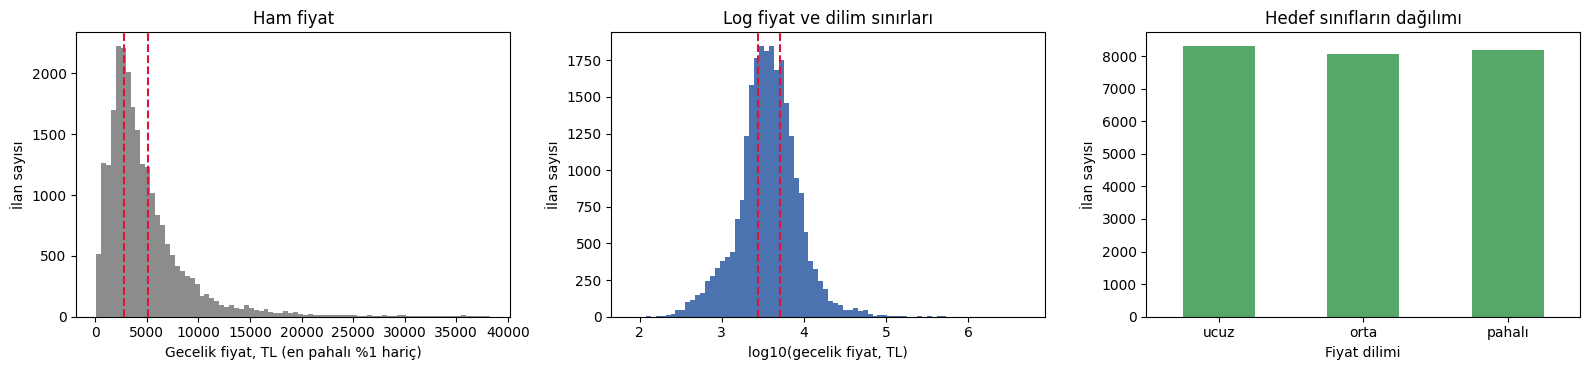

Grafik: ham fiyat sağa çok çarpık (çarpıklık 100.3; en pahalı %1 dışarıda bırakılsa bile uzun bir sağ kuyruk var), log ölçekte neredeyse simetrik (çarpıklık 0.17). Kesikli çizgiler 2,750 ve 5,100 TL sınırları; sınıflar yaklaşık dengeli.


In [6]:
df = df_ham.copy() # ham veri korunur; bütün düzeltmeler bu kopya üzerinde yapılır
df["fiyat"] = df["price"].str.replace(r"[$,]", "", regex=True).astype(float)   # "$4,736.32" → 4736.32 (birim TL)

# Boyut
print(f"Satır × sütun: {df_ham.shape[0]:,} × {df_ham.shape[1]}  ·  bellek: {df_ham.memory_usage(deep=True).sum()/1e6:.0f} MB")
print(f"Farklı ev sahibi: {df['host_id'].nunique():,}  ·  farklı ilçe: {df['neighbourhood_cleansed'].nunique()}")

# Hedef: fiyat dilimi (3 sınıf) — eşikler veriden: terciller, en yakın 50 TL'ye yuvarlanır
# Hedef tanımı: eşikler bütün veriden BİR KEZ hesaplanır (hedef bütün katlarda aynı olmalı, yoksa skorlar karşılaştırılamaz);
# katlardan bağımsızlığı 1.3'teki kontrol hücresinde ölçüldü: eşikler yalnız eğitim katından hesaplansa da hiçbir etiket değişmiyor.
SINIFLAR = ["ucuz", "orta", "pahalı"]
YUVARLAMA = 50
terciller = df["fiyat"].quantile([1/3, 2/3]) # fiyatları üç eşit parçaya bölen iki değer (fiyatı boş ilanlar hesaba girmez)
ESIKLER = (terciller / YUVARLAMA).round().mul(YUVARLAMA).astype(int).tolist() # en yakın 50 TL'ye yuvarlama: 2731 → 2750
print("\nTerciller:", terciller.round(0).tolist(), "→ yuvarlanmış eşikler:", ESIKLER)
print(df["fiyat"].describe(percentiles=[.01, .5, .99]).round(0).to_string())
df["fiyat_dilimi"] = pd.cut(df["fiyat"], [-np.inf, *ESIKLER, np.inf], labels=SINIFLAR, right=False)
print("\nHedef dağılımı (fiyatı olan ilanlar):")
print(pd.concat([df["fiyat_dilimi"].value_counts().reindex(SINIFLAR),
                 df["fiyat_dilimi"].value_counts(normalize=True).reindex(SINIFLAR).round(3)], axis=1).to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].hist(df["fiyat"][df["fiyat"] <= df["fiyat"].quantile(0.99)], bins=80, color="#8C8C8C")   # en pahalı %1 dışarıda: yoksa her şey tek çubuğa düşer
for e in ESIKLER: ax[0].axvline(e, color="crimson", ls="--")
ax[0].set(xlabel="Gecelik fiyat, TL (en pahalı %1 hariç)", ylabel="İlan sayısı", title="Ham fiyat")
ax[1].hist(np.log10(df["fiyat"].dropna()), bins=80, color="#4C72B0")
for e in ESIKLER: ax[1].axvline(np.log10(e), color="crimson", ls="--")
ax[1].set(xlabel="log10(gecelik fiyat, TL)", ylabel="İlan sayısı", title="Log fiyat ve dilim sınırları")
df["fiyat_dilimi"].value_counts().reindex(SINIFLAR).plot.bar(ax=ax[2], color="#55A868", rot=0)
ax[2].set(xlabel="Fiyat dilimi", ylabel="İlan sayısı", title="Hedef sınıfların dağılımı")
plt.tight_layout(); plt.show()
print(f"Grafik: ham fiyat sağa çok çarpık (çarpıklık {df['fiyat'].skew():.1f}; en pahalı %1 dışarıda bırakılsa bile uzun bir sağ kuyruk var), "
      f"log ölçekte neredeyse simetrik (çarpıklık {np.log10(df['fiyat']).skew():.2f}). "
      f"Kesikli çizgiler {ESIKLER[0]:,} ve {ESIKLER[1]:,} TL sınırları; sınıflar yaklaşık dengeli.")

**Yorum** · Hedefin tanımı ve dağılımı

**Ne bulduk:** Veride 27.232 ilan ve 90 sütun görülmüştür. İlanların 9.967 ev sahibine ait ve 39 ilçeye dağıldığı izlenmiştir. Fiyat alanı dolu olan 24.553 ilan hedef tanımına girmektedir. Ham gecelik fiyat sağa çarpıktır: medyan 3.710 TL, ortalama 6.022 TL, en yüksek değer 4,99 milyon TL'dir. Ortalamanın medyandan bu kadar yüksek olması, az sayıda çok pahalı ilanın ortalamayı yukarı çektiğini göstermektedir. Logaritma alındığında dağılım neredeyse simetrik hâle gelmektedir. Fiyat tercillerine göre üç dilime bölünmüş, sınırlar en yakın 50 TL'ye yuvarlanarak 2.750 ve 5.100 TL olarak belirlenmiştir. Sınıfların dengeli olarak dağıldığı görülmüştür: Ucuz %33,8, orta %32,8, pahalı %33,3.

**Ne anlama geliyor:** Fiyatın çarpık olması sonucunda iki karar alınmıştır.

1.   Hedef değer aralığına göre değil sıraya göre (terciller) bölünmüştür; böylece uç değerler sınırları kaydıramaz (gerekçesi aşağıdaki karşılaştırmada).
2.   Fiyatla ilişki ölçülürken Pearson yerine Spearman korelasyonu kullanılmıştır (otomatik sızıntı taraması). Sınıfların dengeli olması, modelin tek bir sınıfı tahmin ederek yüksek doğruluk elde edememesi anlamına gelir; yine de her sınıfa eşit ağırlık vermek için ana ölçüt olarak makro F1 kullanılmıştır (1.6).

**Neyi söyleyemeyiz:** Dağılım özetine göre ilanların en ucuz %1'i 417 TL'nin, en pahalı %1'i 38.318 TL'nin ötesindedir; en düşük fiyat 79 TL, en yüksek 4,99 milyon TL'dir. Bu uç değerlerin gerçek fiyat mı yoksa hatalı giriş mi olduğunu veriden ayırt edemeyiz. Tercil bölmesi sıraya baktığı için bu ilanlar dilim sınırlarını değiştirmez, yalnızca "ucuz" ya da "pahalı" sınıfına düşer; bu nedenle veride bırakılmıştır.

#### Hedef için bölme alternatiflerinin karşılaştırılması
Eşit frekanslı (tercil) bölmenin gerekçesinin diğer bölme yöntemleri oluşturularak netleştirilmiştir. Aynı fiyat aralığı ham fiyat eşit genişlik, log fiyat eşit genişlik, K-means, eşit frakans yöntemleri ile bölünerek sonuçlar karşılaştırılmıştır.

,sınır 1 (TL),sınır 2 (TL),ucuz,orta,pahalı,en küçük sınıf %,dengesizlik (en büyük / en küçük)
yöntem,,,,,,,
Eşit genişlik (ham fiyat),1663102,3326125,24550,2,1,0.0,24550.0
Eşit genişlik (log fiyat),3134,125045,10056,14465,32,0.1,452.0
"Kümeleme (k-ortalamalar, log fiyat)",1829,5698,4016,13708,6829,16.4,3.4
Eşit frekans (terciller),2731,5100,8168,8137,8248,33.1,1.0
Seçilen: yuvarlanmış terciller,2750,5100,8311,8061,8181,32.8,1.0


Kontrol: hedefte kullanılan eşikler ile 'Seçilen' satırı aynı ✓ [2750.0, 5100.0]


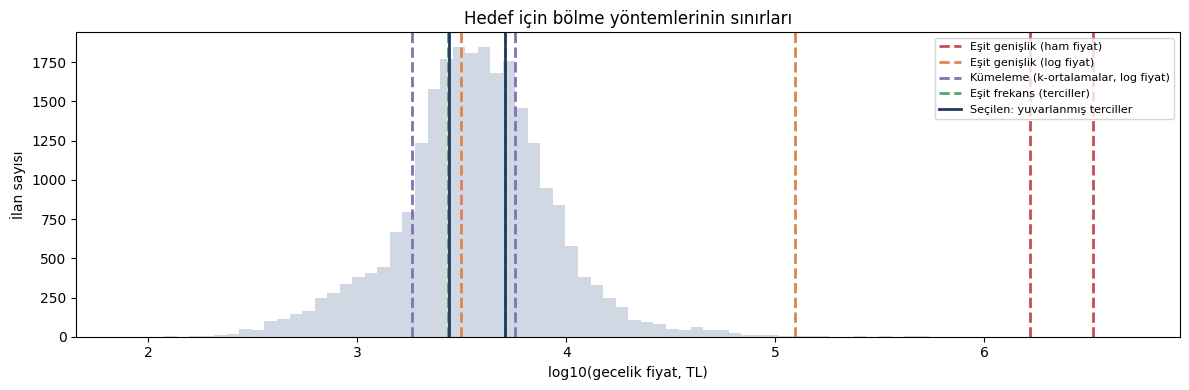

Grafik: gri çubuklar fiyat dağılımı (log ölçek); her renk bir yöntemin iki sınırı. Eşit genişlik sınırları dağılımın sağ kuyruğuna düşüyor, terciller yoğun bölgeyi üçe ayırıyor.

Alternatif büyüklükler (aynı tercil yöntemiyle):
  Kişi başı fiyat          → sınırlar: [959.0, 1533.0] TL/kişi
  İlçe medyanına göre oran → sınırlar: [0.74, 1.33] (1,0 = ilçe medyanı)


In [8]:
# Hedef için bölme alternatiflerinin karşılaştırılması
from sklearn.cluster import KMeans

f = df["fiyat"].dropna()
log_f = np.log10(f)

def sinirlari_bul(yontem):
    if yontem == "Eşit genişlik (ham fiyat)":
        return np.linspace(f.min(), f.max(), 4)[1:-1]
    if yontem == "Eşit genişlik (log fiyat)":
        return 10 ** np.linspace(log_f.min(), log_f.max(), 4)[1:-1]
    if yontem == "Kümeleme (k-ortalamalar, log fiyat)":
        km = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(log_f.to_frame())
        m = np.sort(km.cluster_centers_.ravel())
        return 10 ** ((m[:-1] + m[1:]) / 2)               # iki küme merkezinin ortası = sınır
    if yontem == "Eşit frekans (terciller)":
        return f.quantile([1/3, 2/3]).to_numpy()
    if yontem == "Seçilen: yuvarlanmış terciller":
        return (f.quantile([1/3, 2/3]) / YUVARLAMA).round().to_numpy() * YUVARLAMA

YONTEMLER = ["Eşit genişlik (ham fiyat)", "Eşit genişlik (log fiyat)", "Kümeleme (k-ortalamalar, log fiyat)",
             "Eşit frekans (terciller)", "Seçilen: yuvarlanmış terciller"]
satirlar = []
for yontem in YONTEMLER:
    s = sinirlari_bul(yontem)
    assert s is not None and len(s) == 2, f"'{yontem}' iki sınır döndürmedi: {s}"
    sayilar = pd.cut(f, [-np.inf, *s, np.inf], right=False).value_counts(sort=False).to_numpy()
    satirlar.append({"yöntem": yontem,
                     "sınır 1 (TL)": round(s[0]), "sınır 2 (TL)": round(s[1]),
                     "ucuz": sayilar[0], "orta": sayilar[1], "pahalı": sayilar[2],
                     "en küçük sınıf %": round(100 * sayilar.min() / sayilar.sum(), 1),
                     "dengesizlik (en büyük / en küçük)": round(sayilar.max() / sayilar.min(), 1)})
bolme_tablosu = pd.DataFrame(satirlar).set_index("yöntem")
display(bolme_tablosu)

# Tutarlılık kontrolü: hedefi oluşturan ESIKLER ile bu tablodaki "Seçilen" satırı aynı mı?
secilen = bolme_tablosu.loc["Seçilen: yuvarlanmış terciller", ["sınır 1 (TL)", "sınır 2 (TL)"]].tolist()
assert secilen == list(ESIKLER), f"4a'daki ESIKLER {ESIKLER} ile karşılaştırmadaki sınırlar {secilen} farklı!"
print("Kontrol: hedefte kullanılan eşikler ile 'Seçilen' satırı aynı ✓", secilen)

# Grafik: her yöntemin sınırları aynı log-fiyat dağılımı üzerinde
fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(log_f, bins=80, color="#cfd8e3")
renkler = ["#C44E52", "#DD8452", "#8172B3", "#55A868", "#1f3b5c"]
for (yontem, r), renk in zip(bolme_tablosu.iterrows(), renkler):
    for j, sinir in enumerate([r["sınır 1 (TL)"], r["sınır 2 (TL)"]]):
        ax.axvline(np.log10(sinir), color=renk, ls="--" if "Seçilen" not in yontem else "-", lw=2,
                   label=yontem if j == 0 else None)
ax.set(xlabel="log10(gecelik fiyat, TL)", ylabel="İlan sayısı", title="Hedef için bölme yöntemlerinin sınırları")
ax.legend(fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()
print("Grafik: gri çubuklar fiyat dağılımı (log ölçek); her renk bir yöntemin iki sınırı. "
      "Eşit genişlik sınırları dağılımın sağ kuyruğuna düşüyor, terciller yoğun bölgeyi üçe ayırıyor.")

# Ne böldüğümüz de bir seçim: kapasite ve konum etkisini ayıran iki alternatif büyüklük
kisi_basi = df["fiyat"] / df["accommodates"]
ilceye_gore = df["fiyat"] / df.groupby("neighbourhood_cleansed")["fiyat"].transform("median")
print("\nAlternatif büyüklükler (aynı tercil yöntemiyle):")
print(f"  Kişi başı fiyat          → sınırlar: {kisi_basi.quantile([1/3, 2/3]).round().tolist()} TL/kişi")
print(f"  İlçe medyanına göre oran → sınırlar: {ilceye_gore.quantile([1/3, 2/3]).round(2).tolist()} (1,0 = ilçe medyanı)")

**Yorum** · Hedef için bölme yönteminin seçimi

**Ne bulduk:** Aynı gecelik fiyatı dört yöntemle üç dilime ayırdık:

1. **Eşit genişlik (ham fiyat):** Bu veride kullanılamaz. İlk sınır 1,66 milyon TL'ye düştüğü için ilanların neredeyse tamamı (24.550 / 24.553) "ucuz" sınıfına giriyor.
2. **Eşit genişlik (log fiyat):** Log ölçekte bile en yüksek fiyatlar (en fazla ~5 milyon TL) üst sınırı 125.045 TL'ye itiyor ve "pahalı" sınıfında yalnız 32 ilan kalıyor.
3. **k-ortalamalar (log fiyat):** Daha doğal sınırlar buluyor (1.829 / 5.698 TL), ama ilanların %56'sını orta sınıfa topluyor.
4. **Eşit frekans (terciller):** Sınırlar 2.731 / 5.100 TL; üç dengeli sınıf veriyor.

Sınırları en yakın 50 TL'ye yuvarlamak (2.750 / 5.100 TL) sınıf paylarını en fazla 0,6 puan değiştiriyor.

**Ne anlama geliyor:** Fiyat dağılımı aşırı sağa çarpık olduğu için, değer aralığını eşit bölen yöntemler sınırları birkaç uç ilanın belirlediği boş bölgelere koyuyor. Eşit frekanslı bölme ise değerlere değil sıralara baktığı için uç değerlerden etkilenmiyor: 5 milyon TL'lik bir ilan da yalnızca "pahalı" sınıfına girer. Dengeli sınıflar modelin "hep en kalabalık sınıfı söyle" kolaylığına kaçmasını engeller. Bu nedenle hedef için yuvarlanmış tercilleri seçtik. Model için kullanılan eşikler (`ESIKLER_MODEL`, 1.3) seçilen kapsamdan aynı yöntemle hesaplandığı için kapsam değişirse (ör. yalnız kısa dönem ilanlar) yeni kitleye göre kendiliğinden güncellenir.

Bölünen büyüklük de bir seçimdir. Kişi başı fiyat (sınırlar 959 / 1.533 TL/kişi) kapasiteyi, ilçe medyanına göre göreli fiyat (0,74 / 1,33) ise konumu hedeften arındırır. Bunlar "evin büyüklüğü ve yeri dışında fiyatı ne belirliyor?" sorusuna yönelir ve Proje 2'de ilçe düzeyindeki fiyat farklarını incelemek için bir genişletme yönü oluşturur.

**Neyi söyleyemeyiz:** Hangi bölmenin "doğru" olduğu veriden değil, sorulan sorudan çıkar. Tercillerin piyasada "ucuz" ya da "pahalı" denen bir eşiğe karşılık geldiğini söyleyemeyiz. Sınırlar keskin olduğu için 2.749 TL ile 2.751 TL'lik iki benzer ilan farklı sınıflara düşüyor; orta dilimin iki komşusuyla sınır paylaşması modelin bu sınıfta zorlanmasına yol açabilir. Eşikler bu kazımaya (Eylül 2026, TL) özgüdür.

Bölme yöntemini model başarımına bakarak değil, sınıf dağılımına bakarak seçtik: hedef tanımını model skoruna göre ayarlamak değerlendirmeyi iyimser yapardı.

#### Yinelenenler, künye tablosu ve otomatik sızıntı taraması

In [9]:
# Yinelenen satırlar
kimlikler = ["id", "listing_url", "picture_url", "price_quote_raw"]
print("Tam yinelenen satır (kimlik/URL sütunları hariç):", df_ham.drop(columns=kimlikler).duplicated().sum())
neredeyse = df.duplicated(["host_id", "name", "room_type", "accommodates", "neighbourhood_cleansed"], keep=False)
print("Aynı ev sahibi + aynı ad + aynı oda tipi/kapasite/ilçe olan ilan:", int(neredeyse.sum()))
ilan_sayisi = df.groupby("host_id")["id"].transform("size")
print(f"İlanların {(ilan_sayisi >= 10).mean():.1%}'i 10+ ilanı olan ev sahiplerine ait; en büyük ev sahibinin {ilan_sayisi.max()} ilanı var.")

# Künye tablosu: her sütun için tip, eksik oranı, farklı değer sayısı, sıfır oranı
kunye = pd.DataFrame({
    "saklama_tipi": df_ham.dtypes.astype(str),
    "eksik_orani": df_ham.isna().mean().round(3),
    "farkli_deger": df_ham.nunique(),
    "sifir_orani": df_ham.apply(lambda s: (s == 0).mean() if pd.api.types.is_numeric_dtype(s) else np.nan).round(3),
})
with pd.option_context("display.max_rows", 100):
    display(kunye)

Tam yinelenen satır (kimlik/URL sütunları hariç): 22
Aynı ev sahibi + aynı ad + aynı oda tipi/kapasite/ilçe olan ilan: 1635
İlanların 34.9%'i 10+ ilanı olan ev sahiplerine ait; en büyük ev sahibinin 347 ilanı var.


,saklama_tipi,eksik_orani,farkli_deger,sifir_orani
id,int64,0.000,27232,0.000
listing_url,object,0.000,27232,NaN
scrape_id,int64,0.000,1,0.000
last_scraped,object,0.000,2,NaN
source,object,0.608,1,NaN
name,object,0.000,25571,NaN
description,object,0.006,17410,NaN
neighborhood_overview,float64,1.000,0,0.000
picture_url,object,0.000,25806,NaN
host_id,int64,0.000,9967,0.000


In [13]:
# Ölçek tipleri: hedef ve modelde kullanılan ham sütunlar için çıkarılmıştır.
OLCEK_TIPLERI = {
    "fiyat":                          ("oran",    "hedefin kaynağı; sıfır anlamlı, 'iki katı' denebilir"),
    "fiyat_dilimi":                   ("sıralı",  "hedef: ucuz < orta < pahalı, aralar eşit değil"),
    "accommodates":                   ("oran",    "sayım"),
    "bedrooms":                       ("oran",    "sayım"),
    "beds":                           ("oran",    "sayım"),
    "minimum_nights":                 ("oran",    "sayım (gece)"),
    "calculated_host_listings_count": ("oran",    "sayım"),
    "number_of_reviews":              ("oran",    "sayım"),
    "reviews_per_month":              ("oran",    "sayım / ay"),
    "hosts_time_as_host_years":       ("oran",    "süre"),
    "latitude":                       ("aralık",  "sıfır noktası keyfi (ekvator); fark anlamlı, oran değil"),
    "longitude":                      ("aralık",  "sıfır noktası keyfi (Greenwich)"),
    "review_scores_rating":           ("aralık*", "1–5 yıldızların ortalaması; *yıldızlar sıralı, ortalaması aralık gibi ele alınır"),
    "review_scores_location":         ("aralık*", "1–5 yıldızların ortalaması; *yıldızlar sıralı, ortalaması aralık gibi ele alınır"),
    "review_scores_cleanliness":      ("aralık*", "1–5 yıldızların ortalaması; *yıldızlar sıralı, ortalaması aralık gibi ele alınır"),
    "room_type":                      ("nominal", "4 kategori, sırası yok"),
    "property_type":                  ("nominal", "çok kategorili"),
    "neighbourhood_cleansed":         ("nominal", "ilçe"),
    "host_is_superhost":              ("nominal", "ikili (t / f)"),
    "host_identity_verified":         ("nominal", "ikili (t / f)"),
    "host_has_profile_pic":           ("nominal", "ikili (t / f)"),
    "bathrooms_text":                 ("metin",   "banyo sayısı (oran) + banyo tipi (nominal)"),
    "license":                        ("metin",   "lisans durumu (nominal)"),
    "amenities":                      ("metin",   "olanak sayısı (oran)"),
    "description":                    ("metin",   "açıklama uzunluğu (oran)"),
}
olcek_tablosu = pd.DataFrame(
    [(s, str(df[s].dtype), o, a) for s, (o, a) in OLCEK_TIPLERI.items()],
    columns=["sütun", "saklama_tipi", "ölçek_tipi", "açıklama"]).set_index("sütun")
display(olcek_tablosu)
print("Ölçek tiplerine göre sütun sayısı:", olcek_tablosu["ölçek_tipi"].value_counts().to_dict())

,saklama_tipi,ölçek_tipi,açıklama
sütun,,,
fiyat,float64,oran,"hedefin kaynağı; sıfır anlamlı, 'iki katı' den..."
fiyat_dilimi,category,sıralı,"hedef: ucuz < orta < pahalı, aralar eşit değil"
accommodates,int64,oran,sayım
bedrooms,float64,oran,sayım
beds,float64,oran,sayım
minimum_nights,int64,oran,sayım (gece)
calculated_host_listings_count,int64,oran,sayım
number_of_reviews,int64,oran,sayım
reviews_per_month,float64,oran,sayım / ay


Ölçek tiplerine göre sütun sayısı: {'oran': 9, 'nominal': 6, 'metin': 4, 'aralık*': 3, 'aralık': 2, 'sıralı': 1}


In [14]:
# Otomatik sızıntı taraması: fiyatla aşırı ilişkili sayısal sütunlar (Kaufman vd.: "şüpheli derecede iyi öznitelik")
sayisal = df_ham.select_dtypes("number").columns.drop(["id", "scrape_id", "host_id", "host_profile_id"], errors="ignore")
iliski = df[sayisal].corrwith(df["fiyat"], method="spearman").abs().dropna().sort_values(ascending=False)
print("Fiyatla |Spearman| ilişkisi en yüksek 6 sayısal sütun:"); print(iliski.head(6).round(3).to_string())
print("\nPearson - Spearman karşılaştırması (fiyat çarpık ve uç değerli olduğu için Spearman):")
for c in ["accommodates", "bedrooms", "minimum_nights"]:
    print(f"  {c:<16} Pearson: {df[c].corr(df['fiyat']):.3f} · Spearman: {df[c].corr(df['fiyat'], method='spearman'):.3f}")

# Tahmini gelir fiyattan mı türetilmiş? gelir / (fiyat × doluluk) oranı
r_, o_ = df["estimated_revenue_l365d"], df["estimated_occupancy_l365d"]
m_ = r_ > 0
print(f"\nestimated_revenue_l365d: |Spearman| = {iliski.get('estimated_revenue_l365d', np.nan):.3f}, sıfır oranı = {(r_ == 0).mean():.1%}; "
      f"gelir / (fiyat × doluluk) oranı (gelir > 0 olan {m_.sum():,} ilan): ort = {(r_[m_] / (df['fiyat'][m_] * o_[m_])).mean():.4f}")

Fiyatla |Spearman| ilişkisi en yüksek 6 sayısal sütun:
price_quote_price_per_night                    1.000
accommodates                                   0.518
bedrooms                                       0.390
beds                                           0.375
calculated_host_listings_count_entire_homes    0.352
minimum_nights                                 0.340

Pearson - Spearman karşılaştırması (fiyat çarpık ve uç değerli olduğu için Spearman):
  accommodates     Pearson: 0.093 · Spearman: 0.518
  bedrooms         Pearson: 0.066 · Spearman: 0.390
  minimum_nights   Pearson: -0.004 · Spearman: -0.340

estimated_revenue_l365d: |Spearman| = 0.305, sıfır oranı = 46.3%; gelir / (fiyat × doluluk) oranı (gelir > 0 olan 11,938 ilan): ort = 1.0000


#### Şüpheli öznitelik listesi ve kararlar
Liste iki aşamada oluşturuldu:

1. **Kurallara dayalı otomatik tarama:** Her sütun yedi kurala göre taranmıştır (tamamen boş, sabit, kimlik benzeri, hedefle aşırı ilişkili, metin olarak saklanmış sayı, uzun metin, şüpheli ad kalıbı). Kuralların belirlenmesinde ödevin yönergesinde yer alan şüpheli türleri (kimlik benzeri, kodlanmış eksik, sonradan bilinen) ve Kaufman vd.'nin "şüpheli derecede iyi öznitelik" önerisi belirleyici olmuştur.
2. **Alan bilgisiyle eklenenler:** Verinin nasıl üretildiğine (Inside Airbnb sütun tanımları, 7464 sayılı Kanun) ve sütunların en sık değerlerine bakılarak bulunan sızıntı adayları ve kodlanmış değerler ile belirlenmiştir. Örneğin `maximum_nights` sütunundaki 1125 değeri Airbnb'nin "sınır yok" varsayılanıdır; `license` sütunundaki `12-3456` bir yer tutucudur.


Karar tablosundaki "nasıl bulundu" sütunu her satırın hangi aşamadan geldiğini gösterir: *otomatik tarama*, *alan bilgisi* ya da satırdaki sütunların bir kısmı taramadan, kalanı alan bilgisinden geldiyse *kısmen otomatik*.



In [15]:
# Kurallara dayalı şüpheli aday taraması
import re
# Kural için anahtar kelimeler: fiyat/gelir/değer/doluluk ve kazıma anına göre zaman pencereleri.
# Bu liste ALAN BİLGİSİYLE seçildi (Inside Airbnb sütun tanımları); istatistiksel bir kural değildir.
SIZINTI_AD_KALIBI = r"price|revenue|value|occupancy|availability|_ltm|_l30d|_ly$|_l365d"

n = len(df_ham)
bulgular = []
for c in df_ham.columns:
    s = df_ham[c]
    eksik, farkli = s.isna().mean(), s.nunique()
    metin = not pd.api.types.is_numeric_dtype(s)
    if eksik == 1:
        bulgular.append((c, "1 · tamamen boş", "eksik oranı = 1")); continue
    if farkli == 1:
        bulgular.append((c, "2 · sabit", f"tek değer: {s.dropna().iloc[0]!r}, eksik %{eksik*100:.0f}"))
    if c.endswith("_url") or (farkli / n > 0.3 and c.endswith("id")) or c == "id":
        bulgular.append((c, "3 · kimlik benzeri", f"farklı değer / satır = {farkli/n:.2f}"))
    if not metin and not c.endswith("id"):
        rho = s.corr(df["fiyat"], method="spearman")
        if abs(rho) > 0.95:
            bulgular.append((c, "4 · hedefle aşırı ilişkili", f"|Spearman| = {abs(rho):.3f}"))
    if metin and s.dropna().astype(str).str.fullmatch(r"\$[\d,.]+").mean() > 0.9:
        bulgular.append((c, "5 · sayı metin olarak saklanmış", f"örnek: {s.dropna().iloc[0]!r}"))
    if metin and s.dropna().astype(str).str.len().mean() > 100 and not c.endswith("_url"):
        bulgular.append((c, "6 · uzun metin", f"ortalama {s.dropna().astype(str).str.len().mean():.0f} karakter"))
    if re.search(SIZINTI_AD_KALIBI, c) and c != "price":
        bulgular.append((c, "7 · ad kalıbı: fiyat/gelir/doluluk/zaman penceresi", f"eşleşen: '{re.search(SIZINTI_AD_KALIBI, c).group()}'"))

aday = pd.DataFrame(bulgular, columns=["sütun", "kural", "kanıt"]).sort_values("kural")
with pd.option_context("display.max_rows", 100):
    display(aday)
print(f"{aday['sütun'].nunique()} farklı sütun en az bir kurala takıldı ({len(aday)} bulgu).")

,sütun,kural,kanıt
23,bathrooms,1 · tamamen boş,eksik oranı = 1
33,calendar_updated,1 · tamamen boş,eksik oranı = 1
22,neighbourhood_group_cleansed,1 · tamamen boş,eksik oranı = 1
21,neighbourhood,1 · tamamen boş,eksik oranı = 1
20,host_verifications,1 · tamamen boş,eksik oranı = 1
19,host_total_listings_count,1 · tamamen boş,eksik oranı = 1
18,host_neighbourhood,1 · tamamen boş,eksik oranı = 1
16,host_thumbnail_url,1 · tamamen boş,eksik oranı = 1
15,host_acceptance_rate,1 · tamamen boş,eksik oranı = 1
14,host_response_rate,1 · tamamen boş,eksik oranı = 1


45 farklı sütun en az bir kurala takıldı (48 bulgu).


In [16]:
# Karar tablosu: otomatik adaylar + alan bilgisiyle eklenenler. Veri incelenerek otomatik, yarı otomatik ve manuel yöntemle oluşturulmuştur.
kunye_bos = df_ham.columns[df_ham.isna().all()].tolist()
inceleme = [
    # (sütunlar, neden şüpheli, karar)
    (["id", "listing_url", "picture_url", "host_id", "host_url", "host_profile_id",
      "host_profile_url", "host_picture_url", "host_name"],
     "Kimlik benzeri / kişisel bilgi", "Modelden çıkar; host_id yalnız bölme grubu."),
    (["scrape_id", "last_scraped", "calendar_last_scraped"], "Kazıma meta verisi (1–2 değer)", "Çıkar."),
    (kunye_bos, "Tamamen boş (bu kazımada doldurulmamış)", "Çıkar."),
    (["price"], "Sayı metin olarak saklanmış ($ işareti, birim TL)", "Sayıya çevir → hedefin kaynağı (fiyat_dilimi)."),
    (["price_quote_price_per_night", "price_quote_total_price", "price_quote_raw"],
     "Hedefin kendisi / hedef × gece sayısı", "Çıkar (öznitelik sızıntısı)."),
    (["estimated_revenue_l365d"], "Hedeften türetilmiş: gelir / (fiyat × doluluk) = 1,000", "Çıkar (öznitelik sızıntısı)."),
    (["price_quote_checkin_date", "price_quote_checkout_date"], "Hedefin ölçüm koşulu", "Çıkar; künyede vekil hedef tartışması."),
    (["availability_30", "availability_60", "availability_90", "availability_365", "availability_eoy",
      "estimated_occupancy_l365d"], "Fiyatın sonucu olabilir (ters nedensellik)", "Çıkar (ters nedensellik; senaryodan bağımsız)."),
    (["number_of_reviews_ltm", "number_of_reviews_l30d", "number_of_reviews_ly"],
     "Kazıma anına yakın dönem; fiyatın sonucu olabilir", "Çıkar (ters nedensellik; senaryodan bağımsız)."),
    (["number_of_reviews", "reviews_per_month", "first_review", "last_review"] +
     [c for c in df_ham.columns if c.startswith("review_scores_") and c != "review_scores_value"],
     "Yeni ilanda bilinmez; yorum yoksa yapısal eksik; puan = 0 kodlanmış eksik",
     "Kullan (senaryo: mevcut ilan): yorum sayısı, aylık yorum, genel/konum/temizlik puanı; reviews_per_month → 0, puan 0 → NaN."),
    (["review_scores_value"], "Misafirin fiyat/performans puanı: fiyat bilgisi içerir", "Çıkar (öznitelik sızıntısı riski)."),
    (["has_availability"], "Tek değer + boş: boş = 'müsait değil'", "'f' ile doldur (1.3)."),
    (["source"], "Tek değer + boş: boş = 'city scrape'", "'guncel' / 'onceki' kategorisine çevir (1.3)."),
    (["license"], "Yer tutucu '12-3456' / '123456' ve serbest metin", "Yer tutucu → NaN; durum kategorisine çevir."),
    (["bathrooms_text"], "Sayı metnin içinde ('1.5 shared baths')", "banyo_sayisi + banyo_tipi'ne ayır."),
    (["maximum_nights", "minimum_maximum_nights", "maximum_maximum_nights", "maximum_nights_avg_ntm"],
     "1125 = Airbnb varsayılanı ('sınır yok')", "Çıkar (kodlanmış değer)."),
    (["minimum_minimum_nights", "maximum_minimum_nights", "minimum_nights_avg_ntm"],
     "minimum_nights'ın takvim türevleri (aynı bilgi)", "Çıkar (tekrar eden bilgi)."),
    (["minimum_nights"], "100 gecede yığılma (7464 sayılı Kanun)", "Kullan (kapsam: bütün ilanlar): log_min_gece; 100 gece etkisi yorumda tartışılır."),
    (["name", "description", "host_about", "amenities"], "Metin", "Bölüm 1'de yalnız uzunluk / sayı; metin analizi Proje 2'ye."),
]

otomatik = set(aday["sütun"])                     # taramanın bulduğu sütunlar
def nasil_bulundu(sutunlar):
    k = sum(c in otomatik for c in sutunlar)
    return "otomatik tarama" if k == len(sutunlar) else ("alan bilgisi" if k == 0 else "kısmen otomatik")

karar_tablosu = pd.DataFrame(
    [(", ".join(s), len(s), nasil_bulundu(s), neden, karar) for s, neden, karar in inceleme],
    columns=["sütun(lar)", "sayı", "nasıl bulundu", "neden şüpheli", "karar"])
with pd.option_context("display.max_colwidth", 110):
    display(karar_tablosu)

# Kapsama kontrolü: incelenen + kalan = bütün sütunlar mı?
incelenen = {c for s, _, _ in inceleme for c in s}
kalan = [c for c in df_ham.columns if c not in incelenen]
print(f"İncelenen {len(incelenen)} sütun + kalan {len(kalan)} sütun = {len(incelenen) + len(kalan)} / {df_ham.shape[1]}")
print("Otomatik taramanın bulup tabloya girmeyen sütun:", sorted(otomatik - incelenen) or "yok")
print("\nŞüpheli bulunmayan, model adayı sütunlar:"); print(kalan)

,sütun(lar),sayı,nasıl bulundu,neden şüpheli,karar
0,"id, listing_url, picture_url, host_id, host_url, host_profile_id, host_profile_url, host_picture_url, host...",9,kısmen otomatik,Kimlik benzeri / kişisel bilgi,Modelden çıkar; host_id yalnız bölme grubu.
1,"scrape_id, last_scraped, calendar_last_scraped",3,kısmen otomatik,Kazıma meta verisi (1–2 değer),Çıkar.
2,"neighborhood_overview, host_since, host_response_time, host_response_rate, host_acceptance_rate, host_thum...",14,otomatik tarama,Tamamen boş (bu kazımada doldurulmamış),Çıkar.
3,price,1,otomatik tarama,"Sayı metin olarak saklanmış ($ işareti, birim TL)",Sayıya çevir → hedefin kaynağı (fiyat_dilimi).
4,"price_quote_price_per_night, price_quote_total_price, price_quote_raw",3,otomatik tarama,Hedefin kendisi / hedef × gece sayısı,Çıkar (öznitelik sızıntısı).
5,estimated_revenue_l365d,1,otomatik tarama,"Hedeften türetilmiş: gelir / (fiyat × doluluk) = 1,000",Çıkar (öznitelik sızıntısı).
6,"price_quote_checkin_date, price_quote_checkout_date",2,otomatik tarama,Hedefin ölçüm koşulu,Çıkar; künyede vekil hedef tartışması.
7,"availability_30, availability_60, availability_90, availability_365, availability_eoy, estimated_occupancy...",6,otomatik tarama,Fiyatın sonucu olabilir (ters nedensellik),Çıkar (ters nedensellik; senaryodan bağımsız).
8,"number_of_reviews_ltm, number_of_reviews_l30d, number_of_reviews_ly",3,otomatik tarama,Kazıma anına yakın dönem; fiyatın sonucu olabilir,Çıkar (ters nedensellik; senaryodan bağımsız).
9,"number_of_reviews, reviews_per_month, first_review, last_review, review_scores_rating, review_scores_accur...",10,alan bilgisi,Yeni ilanda bilinmez; yorum yoksa yapısal eksik; puan = 0 kodlanmış eksik,"Kullan (senaryo: mevcut ilan): yorum sayısı, aylık yorum, genel/konum/temizlik puanı; reviews_per_month → ..."


İncelenen 69 sütun + kalan 21 sütun = 90 / 90
Otomatik taramanın bulup tabloya girmeyen sütun: yok

Şüpheli bulunmayan, model adayı sütunlar:
['hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_location', 'host_is_superhost', 'host_listings_count', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bedrooms', 'beds', 'calculated_host_listings_count', 'calculated_host_listings_count_entire_homes', 'calculated_host_listings_count_private_rooms', 'calculated_host_listings_count_shared_rooms']


**Yorum** · Keşifsel analiz, yinelenenler ve şüpheli öznitelikler

**Ne bulduk:**

1. **Boyut ve tipler:** Veride 27.232 ilan ve 90 sütun bulunmaktadır; bu sütunlardan 14'ü bu kazımada tamamen boştur. Fiyatı olan 24.553 ilan modele girmektedir. Saklama tiplerinin yanıltıcı olabileceği görülmüştür: `price` metin olarak saklanmıştır (`"$4,736.32"`, birim aslında TL), `license` serbest metindir, `bathrooms_text` ise sayıyı metnin içinde taşımaktadır. Ölçek tipleri şöyledir: ilçe, oda tipi ve mülk tipi *nominal*; `fiyat_dilimi` *sıralı*; puanlar 1–5 arası ortalamalar olduğu için *aralık* ölçeğinde ele alınmıştır; kapasite, yatak, yorum sayısı ve fiyat *oran* ölçeğindedir.
2. **Hedef:** Hedefin tanımı, dağılımı ve bölme yönteminin gerekçesi yukarıdaki iki yorumda verilmiştir: dilim sınırları 2.750 / 5.100 TL'dir ve sınıflar dengelidir.
3. **Yinelenenler:** Tam yinelenen yalnız 22 satır bulunmuştur. Asıl sorunun ev sahibi düzeyinde olduğu görülmüştür: aynı ev sahibi, aynı ad, oda tipi, kapasite ve ilçeyle 1.635 ilan tekrarlanmaktadır. İlanların %34,9'u 10'dan fazla ilanı olan ev sahiplerine aittir; en büyük ev sahibinin 347 ilanı vardır.
4. **Korelasyon:** Fiyat çarpık ve uç değerli olduğu için Spearman sıra korelasyonu kullanılmıştır. Kapasite ile fiyat arasındaki ilişki Pearson ile 0,09, Spearman ile 0,52 olarak hesaplanmıştır.
5. **Şüpheli öznitelikler:** Kurallara dayalı tarama 45 sütunu en az bir kurala takılmış olarak işaretlemiştir. Korelasyon kuralı yalnız `price_quote_price_per_night` sütununu (|ρ| = 1,000) yakalamıştır. Hedeften türetilmiş ya da fiyat bilgisi taşıyan üç sütunun korelasyonla görünmediği tespit edilmiştir:
   * `estimated_revenue_l365d`: |ρ| = 0,31, çünkü değerlerin %46'sı sıfırdır; ancak gelir / (fiyat × doluluk) oranı tam 1,000'dır.
   * `price_quote_total_price`: |ρ| = 0,04, çünkü gece sayısı 1 ile 365 arasında değişmektedir.
   * `review_scores_value`: Misafirin fiyat/performans puanıdır; fiyatla en zayıf ilişkili puandır (|ρ| = 0,09).

   Bu sütunlar, alan bilgisinin tekrarlanabilir bir kurala (sütun adı kalıbı) dönüştürülmesiyle yakalanmıştır. Karar tablosundaki 19 satırın 10'u otomatik taramadan, 3'ü kısmen otomatik taramadan, 6'sı yalnız alan bilgisiyle gelmiştir.

**Ne anlama geliyor:** Bulgular üç karara yol açmıştır.

1. Aynı ev sahibinin neredeyse aynı ilanları eğitim ve test kümelerine ayrı düşerse model "kopyayı" tanıyarak skoru şişirebilir. Bu nedenle çapraz doğrulama ev sahibine göre yapılacaktır (1.5'te sınanmaktadır).
2. Pearson, birkaç milyon TL'lik ilan yüzünden kapasite ile fiyat arasındaki gerçek ilişkiyi gizlemektedir. Bu nedenle fiyatla ilişki ölçülürken Spearman kullanılmıştır.
3. Hedefin kopyası, hedeften türetilmiş ya da fiyatın sonucu olabilecek sütunlar modelden çıkarılmıştır; her sütunun kararı ve gerekçesi karar tablosunda verilmiştir.

**Neyi söyleyemeyiz:** Otomatik tarama sızıntıyı bulmak için gereklidir, ancak yeterli değildir. Hedef başka bir değişkenle çarpılmışsa ya da fiyata göre verilmiş bir değerlendirmenin içine gömülmüşse korelasyon onu gizleyebilir (Kaufman vd., 2012). Bu nedenle taramanın bütün sızıntı kaynaklarını bulduğunu kanıtlayamayız. Doluluk ve son dönem yorum sütunlarının fiyatın sonucu olup olmadığı da veriyle değil, senaryoyla belirlenen bir yargıdır.

### 1.3 Eksiklik analizi
Eksik kodlarını `NaN`'a çevirin; deseni görselleştirin; en çok eksiği olan iki sütun için MCAR / MAR / MNAR tahmini; `add_indicator` etkisi.

In [27]:
# Kodlanmış eksiklerin NaN'a (ya da doğru anlamına) çevrilmesi
# Bu dönüşümler satır satır kural uygular, veriden bir şey ÖĞRENMEZ → bölmeden önce yapılması sızıntı değildir.
LISANS_YER_TUTUCULARI = ["12-3456", "123456"]          # örnek / sahte numaralar (103 + 1 ilan)

def kodlanmis_eksikleri_duzelt(d):
    d = d.copy()
    # 1) license: yer tutucu numaralar gerçek izin değil → eksik
    d.loc[d["license"].isin(LISANS_YER_TUTUCULARI), "license"] = np.nan
    # 2) review_scores_rating: ölçek 1–5; 1'in altı imkânsız → eksik (yalnız o hücre)
    d.loc[d["review_scores_rating"] < 1, "review_scores_rating"] = np.nan
    # 3) reviews_per_month: yorumu olmayan ilanda gerçek değer 0'dır, NaN yazılmış (ters yönlü kodlama)
    d.loc[d["number_of_reviews"] == 0, "reviews_per_month"] = 0.0
    # 4) has_availability: tek değer 't' + boş → boş = 'müsait değil'
    d["has_availability"] = d["has_availability"].fillna("f")
    # 5) source: tek değer 'previous scrape' + boş → boş = güncel kazıma
    d["source"] = d["source"].map({"previous scrape": "onceki"}).fillna("guncel")
    return d

degisen_sutunlar = ["license", "review_scores_rating", "reviews_per_month", "has_availability", "source"]
once = df[degisen_sutunlar].isna().sum()
df = kodlanmis_eksikleri_duzelt(df)
sonra = df[degisen_sutunlar].isna().sum()
ozet = pd.DataFrame({"eksik (önce)": once, "eksik (sonra)": sonra, "fark": sonra - once,
                     "eksik oranı (sonra)": (sonra / len(df)).round(3)})
display(ozet)

# Dokunmadıklarımız ve nedeni (geçerli değerler, eksik değil)
print("bedrooms = 0 olan ilan        :", int((df["bedrooms"] == 0).sum()), "→ stüdyo, geçerli sıfır")
print("number_of_reviews = 0 olan ilan:", int((df["number_of_reviews"] == 0).sum()), "→ yorum almamış ilan, geçerli sıfır")
print("maximum_nights = 1125 olan ilan:", int((df["maximum_nights"] == 1125).sum()), "→ platform varsayılanı; sütun modelde kullanılmıyor (1.2)")

,eksik (önce),eksik (sonra),fark,eksik oranı (sonra)
license,9529,9633,104,0.354
review_scores_rating,9661,9662,1,0.355
reviews_per_month,9661,0,-9661,0.000
has_availability,457,0,-457,0.000
source,16563,0,-16563,0.000


bedrooms = 0 olan ilan        : 1039 → stüdyo, geçerli sıfır
number_of_reviews = 0 olan ilan: 9661 → yorum almamış ilan, geçerli sıfır
maximum_nights = 1125 olan ilan: 7985 → platform varsayılanı; sütun modelde kullanılmıyor (1.2)


#### Eksiklik deseni

In [28]:
# Eksiklik deseni: hangi sütunlar, hangi ilanlarda birlikte eksik?
eksik_oran = df[df_ham.columns].isna().mean()
kismi = eksik_oran[(eksik_oran > 0) & (eksik_oran < 1)].sort_values(ascending=False).index   # tamamen boş/dolu olanlar desen göstermez
print(f"Kısmen eksik {len(kismi)} sütun:"); print(eksik_oran[kismi].round(3).to_string())

# Satırları anlamlı bir sıraya diziyoruz: önce fiyatı eksik olanlar, sonra yorum sayısı artan.
# Böylece "birlikte eksik olan" sütunlar bloklar hâlinde görünür.
sirali = (df.assign(_fiyat_yok=df["fiyat"].isna())
            .sort_values(["_fiyat_yok", "number_of_reviews"], ascending=[False, True]))
ornek = sirali.iloc[::10]                                   # her 10 ilandan biri (~2.700 satır), okunaklı olsun


Kısmen eksik 23 sütun:
host_about                     0.586
host_location                  0.359
review_scores_value            0.355
review_scores_checkin          0.355
review_scores_rating           0.355
review_scores_accuracy         0.355
review_scores_location         0.355
review_scores_communication    0.355
first_review                   0.355
review_scores_cleanliness      0.355
last_review                    0.355
license                        0.354
price                          0.098
price_quote_total_price        0.098
price_quote_price_per_night    0.098
estimated_revenue_l365d        0.098
price_quote_raw                0.062
price_quote_checkout_date      0.062
price_quote_checkin_date       0.062
beds                           0.015
description                    0.006
bathrooms_text                 0.004
bedrooms                       0.001


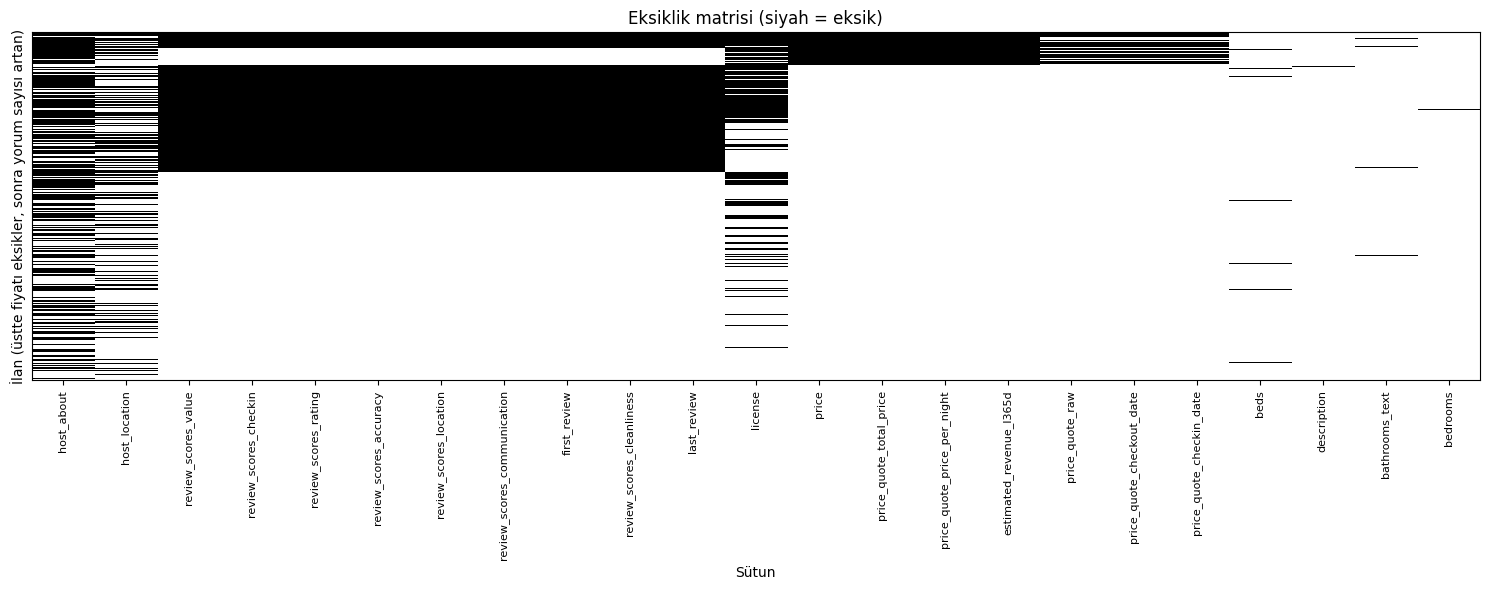

Grafik 1: her satır bir ilan, siyah hücreler eksik değer. Satırlar sıralandığı için birlikte eksik olan sütunlar bloklar hâlinde görünüyor: üstte fiyat sütunları, ortada yorum puanları ve lisans.


In [29]:
# Grafik 1 · Eksiklik matrisi: her satır bir ilan, siyah hücre eksik değer
fig, ax = plt.subplots(figsize=(15, 6))
ax.imshow(ornek[kismi].isna().to_numpy(), aspect="auto", interpolation="nearest", cmap="Greys")
ax.set_xticks(range(len(kismi))); ax.set_xticklabels(kismi, rotation=90, fontsize=8)
ax.set_yticks([])
ax.set(xlabel="Sütun", ylabel="İlan (üstte fiyatı eksikler, sonra yorum sayısı artan)",
       title="Eksiklik matrisi (siyah = eksik)")
plt.tight_layout(); plt.show()
print("Grafik 1: her satır bir ilan, siyah hücreler eksik değer. Satırlar sıralandığı için birlikte eksik olan "
      "sütunlar bloklar hâlinde görünüyor: üstte fiyat sütunları, ortada yorum puanları ve lisans.")


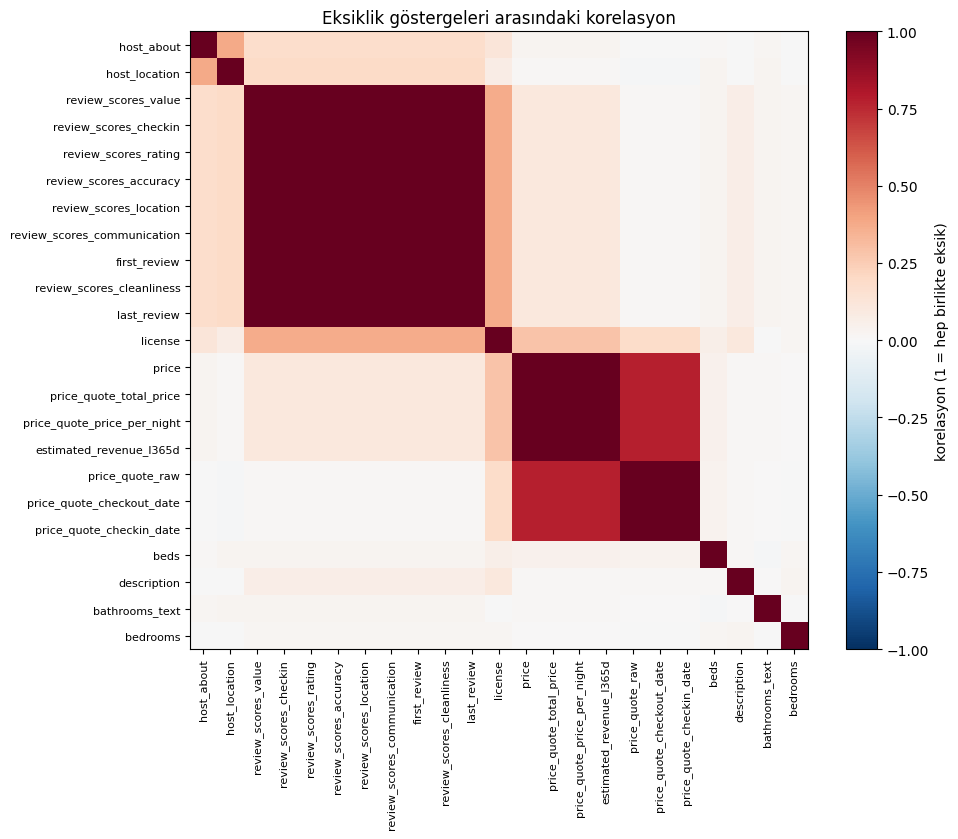

Grafik 2: koyu kırmızı kareler birlikte eksik olan sütun bloklarını gösteriyor: yorum puanları, fiyat sütunları ve fiyat teklifi tarihleri. Lisansın eksikliği iki blokla da orta düzeyde ilişkili.


In [30]:
# Grafik 2 · Eksiklik korelasyonu: iki sütunun eksikliği ne kadar birlikte görülüyor?
birlikte = df[kismi].isna().astype(int).corr()              # her sütun için "eksik mi?" (0/1) göstergeleri arasındaki korelasyon
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(birlikte.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(kismi))); ax.set_xticklabels(kismi, rotation=90, fontsize=8)
ax.set_yticks(range(len(kismi))); ax.set_yticklabels(kismi, fontsize=8)
ax.set_title("Eksiklik göstergeleri arasındaki korelasyon")
plt.colorbar(im, ax=ax, fraction=0.046, label="korelasyon (1 = hep birlikte eksik)")
plt.tight_layout(); plt.show()
print("Grafik 2: koyu kırmızı kareler birlikte eksik olan sütun bloklarını gösteriyor: yorum puanları, fiyat sütunları "
      "ve fiyat teklifi tarihleri. Lisansın eksikliği iki blokla da orta düzeyde ilişkili.")

In [31]:
# Grafikte gördüğümüzü sayıyla doğrulama: blokları açıklayan değişken ne?
def eksik_orani_gruba_gore(sutun, grup, grup_adi):
    tablo = (df[sutun].isna().groupby(grup, observed=True).mean() * 100).round(1)
    print(f"  {sutun:<22} eksik % | {grup_adi:<24}: {tablo.to_dict()}")

yorum_grubu = pd.cut(df["number_of_reviews"], [-1, 0, 5, 30, np.inf], labels=["0", "1-5", "6-30", "30+"])
print("\nBlok 1 · yorum puanları:");   eksik_orani_gruba_gore("review_scores_rating", yorum_grubu, "yorum sayısı")
print("Blok 2 · fiyat sütunları:");    eksik_orani_gruba_gore("price", df["availability_365"] == 0, "takvim tamamen kapalı mı")
print("Blok 3 · lisans:");             eksik_orani_gruba_gore("license", df["minimum_nights"] >= 100, "en az 100 gece mi")
print("Dağınık görünenler:")
eksik_orani_gruba_gore("host_about", yorum_grubu, "yorum sayısı")
eksik_orani_gruba_gore("host_location", yorum_grubu, "yorum sayısı")


Blok 1 · yorum puanları:
  review_scores_rating   eksik % | yorum sayısı            : {'0': 100.0, '1-5': 0.0, '6-30': 0.0, '30+': 0.0}
Blok 2 · fiyat sütunları:
  price                  eksik % | takvim tamamen kapalı mı: {False: 7.1, True: 99.8}
Blok 3 · lisans:
  license                eksik % | en az 100 gece mi       : {False: 1.1, True: 95.3}
Dağınık görünenler:
  host_about             eksik % | yorum sayısı            : {'0': 70.4, '1-5': 62.2, '6-30': 50.8, '30+': 42.5}
  host_location          eksik % | yorum sayısı            : {'0': 48.2, '1-5': 39.5, '6-30': 28.4, '30+': 18.5}


#### En çok eksiği olan iki sütun: MCAR / MAR / MNAR

In [32]:
assert "fiyat_dilimi" in df.columns, "df'te fiyat_dilimi yok: önce 1.2 (hedef) hücresini, sonra 1.3 (a)'yı çalıştırın."
# En çok eksiği olan iki sütun: eksik olanlar ile dolu olanlar farklı mı?
from scipy.stats import chi2_contingency, mannwhitneyu

# Tamamen boşlar hariç en eksik iki sütun (5b'deki sıralamadan)
en_eksik_iki = list(kismi[:2])
print("En çok eksiği olan iki sütun:", {c: round(eksik_oran[c], 3) for c in en_eksik_iki})

SAYISAL_KARSILASTIRMA = {"number_of_reviews": "yorum sayısı",
                         "calculated_host_listings_count": "ev sahibinin ilan sayısı",
                         "hosts_time_as_host_years": "ev sahipliği süresi (yıl)",
                         "accommodates": "kapasite",
                         "fiyat": "gecelik fiyat (TL)"}
KATEGORIK_KARSILASTIRMA = {"host_is_superhost": ("süper ev sahibi oranı", "t"),
                           "room_type": ("tüm ev oranı", "Entire home/apt"),
                           "source": ("önceki kazımadan gelme oranı", "onceki")}

def eksiklik_mekanizmasi(sutun):
    eksik = df[sutun].isna()
    satirlar = []
    for c, ad in SAYISAL_KARSILASTIRMA.items():          # sayısal: medyanlar + Mann-Whitney U testi
        a, b = df.loc[eksik, c].dropna(), df.loc[~eksik, c].dropna()
        satirlar.append((ad, f"{a.median():,.1f}", f"{b.median():,.1f}", "Mann-Whitney", mannwhitneyu(a, b).pvalue))
    for c, (ad, deger) in KATEGORIK_KARSILASTIRMA.items():  # kategorik: oranlar + ki-kare testi
        p = chi2_contingency(pd.crosstab(eksik, df[c]))[1]
        oran = (df[c] == deger).groupby(eksik).mean() * 100
        satirlar.append((ad, f"%{oran[True]:.1f}", f"%{oran[False]:.1f}", "ki-kare", p))
    t = pd.DataFrame(satirlar, columns=["değişken", "EKSİK grupta", "DOLU grupta", "test", "p-değeri"])
    t["p-değeri"] = t["p-değeri"].map(lambda p: "< 0,001" if p < 0.001 else f"{p:.3f}")
    return t.set_index("değişken")

for sutun in en_eksik_iki:
    print(f"\n=== {sutun} · eksik %{eksik_oran[sutun]*100:.1f} · eksik {df[sutun].isna().sum():,} / dolu {df[sutun].notna().sum():,} ilan")
    display(eksiklik_mekanizmasi(sutun))

# Hedefle ilişki: eksiklik fiyat dilimine göre değişiyor mu?
print("\nFiyat dilimine göre eksik oranı (%):")
display(pd.DataFrame({s: (df[s].isna().groupby(df["fiyat_dilimi"], observed=True).mean() * 100).round(1)
                      for s in en_eksik_iki}))

# Modelde kullanılabilecek en eksik sütun: yorum puanları — eksiklik yorumsuzlukla mı açıklanıyor?
yorumsuz = df["number_of_reviews"] == 0
puan_eksik = df["review_scores_rating"].isna()
display(pd.crosstab(puan_eksik.rename("puan eksik"), yorumsuz.rename("yorum yok"), margins=True, margins_name="toplam"))
print(f"Yorumu olup puanı eksik ilan: {int((puan_eksik & ~yorumsuz).sum())} (1.3 (a)'da 0 puanı NaN yapılan)")
print(f"Yorumsuz olup puanı dolu ilan: {int((~puan_eksik & yorumsuz).sum())}")
print("Fiyat dilimine göre puanı eksik ilan oranı:",
      df.groupby("fiyat_dilimi", observed=True)["review_scores_rating"].apply(lambda s: s.isna().mean()).round(3).to_dict())

En çok eksiği olan iki sütun: {'host_about': np.float64(0.586), 'host_location': np.float64(0.359)}

=== host_about · eksik %58.6 · eksik 15,958 / dolu 11,274 ilan


,EKSİK grupta,DOLU grupta,test,p-değeri
değişken,,,,
yorum sayısı,1.0,8.0,Mann-Whitney,"< 0,001"
ev sahibinin ilan sayısı,4.0,8.0,Mann-Whitney,"< 0,001"
ev sahipliği süresi (yıl),3.0,5.0,Mann-Whitney,"< 0,001"
kapasite,3.0,3.0,Mann-Whitney,"< 0,001"
gecelik fiyat (TL),"3,445.7","4,180.0",Mann-Whitney,"< 0,001"
süper ev sahibi oranı,%17.7,%28.0,ki-kare,"< 0,001"
tüm ev oranı,%63.3,%73.3,ki-kare,"< 0,001"
önceki kazımadan gelme oranı,%43.5,%33.1,ki-kare,"< 0,001"



=== host_location · eksik %35.9 · eksik 9,770 / dolu 17,462 ilan


,EKSİK grupta,DOLU grupta,test,p-değeri
değişken,,,,
yorum sayısı,1.0,6.0,Mann-Whitney,"< 0,001"
ev sahibinin ilan sayısı,4.0,6.0,Mann-Whitney,"< 0,001"
ev sahipliği süresi (yıl),3.0,4.0,Mann-Whitney,"< 0,001"
kapasite,3.0,3.0,Mann-Whitney,"< 0,001"
gecelik fiyat (TL),"3,468.9","3,885.0",Mann-Whitney,"< 0,001"
süper ev sahibi oranı,%13.7,%26.5,ki-kare,"< 0,001"
tüm ev oranı,%59.9,%71.6,ki-kare,"< 0,001"
önceki kazımadan gelme oranı,%43.1,%37.0,ki-kare,"< 0,001"



Fiyat dilimine göre eksik oranı (%):


,host_about,host_location
fiyat_dilimi,,
ucuz,65.2,39.1
orta,58.5,36.0
pahalı,50.5,31.9


yorum yok,False,True,toplam
puan eksik,,,
False,17570,0,17570
True,1,9661,9662
toplam,17571,9661,27232


Yorumu olup puanı eksik ilan: 1 (1.3 (a)'da 0 puanı NaN yapılan)
Yorumsuz olup puanı dolu ilan: 0
Fiyat dilimine göre puanı eksik ilan oranı: {'ucuz': 0.433, 'orta': 0.273, 'pahalı': 0.307}


**Yorum** · Eksiklik analizi

**Ne bulduk:**

1. **Kodlanmış eksikler:** Beş düzeltme yapılmıştır. İki gizli eksik ortaya çıkarılmıştır: sahte lisans numaraları (`12-3456`, `123456`; +104 hücre) ve 1–5 ölçeğinde imkânsız olan 0 puan (+1). Buna karşılık boş görünen bazı değerlerin aslında bir anlamı olduğu görülmüştür: yorumsuz ilanların aylık yorum sayısı 0'dır (−9.661), `has_availability` boşu "müsait değil" (−457), `source` boşu ise "güncel kazıma" anlamına gelmektedir (−16.563). Sıfır olup eksik olmayan değerlere dokunulmamıştır: örneğin stüdyo dairelerde 0 yatak odası (1.039 ilan) gerçek bir değerdir.
2. **Eksiklik deseni:** Düzeltmelerden sonra 23 sütun kısmen eksiktir. Eksik değerlerin rastgele dağılmadığı, bloklar hâlinde geldiği görülmüştür:
   * **Yorum puanları:** Yorumu olmayan ilanlarda puan %100, yorumu olanlarda %0 eksiktir.
   * **Fiyat:** Takvimi tamamen kapalı ilanların %99,8'inde fiyat eksik iken, takvimi açık olanlarda bu oran %7,1'dir.
   * **Lisans:** En az konaklaması 100 gece ve üzeri olan ilanların %95,3'ünde, diğerlerinin %1,1'inde lisans eksiktir.
   * **Profil alanları:** `host_about` ve `host_location` belirgin bir blok oluşturmamaktadır; ancak yorum sayısı arttıkça eksiklikleri düzenli olarak azalmaktadır.
3. **En çok eksiği olan iki sütun:** `host_about` (%58,6) ve `host_location` (%35,9). Her iki sütun için ilanlar, sütunu eksik ve dolu olanlar olarak iki gruba ayrılmış ve bu gruplar başka değişkenlerde karşılaştırılmıştır. Eksiklik tamamen rastgele (MCAR) olsaydı iki grubun her açıdan benzer olması beklenirdi.
   * **Yöntem:** Sayısal değişkenler (yorum sayısı, ilan sayısı, ev sahipliği süresi, kapasite, fiyat) çok çarpıktır ve birkaç uç değer ortalamayı kaydırmaktadır. Bu nedenle ortalama yerine uç değerlerden etkilenmeyen medyan, t-testi yerine değerlerin kendisine değil sıralarına bakan Mann-Whitney U testi kullanılmıştır (korelasyonda Spearman'ın seçilme nedeniyle aynı). Kategorik değişkenlerin (süper ev sahibi, oda tipi, kaynak) ortalaması ya da medyanı olmadığı için oranlar karşılaştırılmış, eksiklik ile kategori arasındaki bağımsızlık ki-kare testiyle sınanmıştır. Ki-kare testi bütün kategorilere bakmaktadır; tabloda okunabilirlik için yalnız bir kategorinin oranı gösterilmiştir.
   * **Sonuç:** Profili boş ev sahiplerinin ilanlarının daha az yorum aldığı (medyan 1'e karşı 8), bu ev sahiplerinin daha az ilanı olduğu (4'e karşı 8), daha yeni oldukları (3'e karşı 5 yıl) ve süper ev sahibi oranlarının belirgin biçimde düşük olduğu görülmüştür (`host_about`: %17,7'ye karşı %28,0; `host_location`: %13,7'ye karşı %26,5). Bütün farklar p < 0,001 düzeyindedir. Eksiklik hedefle de ilişkilidir: `host_about` ucuz dilimde %65,2, pahalı dilimde %50,5 eksiktir.
4. **Yorum puanları:** 9.661 yorumsuz ilanın hepsinde puan eksiktir; yorumu olduğu hâlde puanı eksik olan yalnız 1 ilan vardır (0 puanı `NaN`'a çevrilen ilan).

**Ne anlama geliyor:**

1. Kodlanmış eksik düzeltmeleri her satıra yalnız o satırın değerine bakarak uygulanır ve hedefi kullanmaz; bu nedenle bütün veride, çapraz doğrulamadan önce yapılması sızıntı yaratmaz. Medyanla doldurma ise veriden öğrenen bir adım olduğu için Pipeline içinde, yalnız eğitim katıyla yapılmaktadır.
2. Her eksiklik bloğu başka bir değişkenle neredeyse tamamen açıklanmaktadır. Lisans eksikliği 7464 sayılı Kanun'un 100 günden uzun kiralamaları izin şartından muaf tutmasıyla tutarlıdır. Fiyattan türeyen sütunların fiyatla aynı satırlarda eksik olması, bu sütunların fiyattan hesaplandığının bir başka göstergesidir.
3. `host_about` ve `host_location` MCAR değildir; eksiklik gözlenen değişkenlerle (deneyim, ölçek, aktiflik) tutarlı biçimde açıklandığı için MAR olduğu tahmin edilmektedir. Bu iki sütun modelde kullanılmamaktadır.
4. Yorum puanlarının eksikliği yapısal bir MAR'dır: yorumsuz bir ilanın bilinmeyen bir "gerçek puanı" yoktur. Bu sütunlar modelde kullanıldığı için eksikliğin modele nasıl verileceği `add_indicator` ile ayrıca sınanmıştır (bkz. 1.3 sonu).

**Neyi söyleyemeyiz:**

* MAR ile MNAR ayrımını veriyle kanıtlayamayız; testler yalnız MCAR'ı reddetmemizi sağlar. MNAR'ı görmek için eksik değerin kendisini bilmek gerekir (ör. yurt dışında yaşayan ev sahipleri konumlarını bilerek gizliyor olabilir).
* Büyük örneklem nedeniyle çok küçük farklar bile anlamlı çıkmaktadır: kapasitenin medyanı iki grupta da 3 olduğu hâlde p < 0,001'dir. Mann-Whitney testi yalnız medyanları değil, dağılımların bütününü karşılaştırdığı için medyanlar aynıyken de fark bulabilir. Bu nedenle p-değerleriyle yetinilmemiş, farkların büyüklüğüne bakılmıştır.
* Her iki test de gözlemlerin bağımsız olduğunu varsaymaktadır; ancak profil alanları ev sahibi düzeyindedir ve çok ilanlı bir ev sahibinin boş profili tabloya ilan sayısı kadar girer. Bu nedenle p-değerleri olduğundan küçük görünmektedir.
* Eksiklik matrisi her 10 ilandan birini gösterdiği için seyrek eksikler grafikte görünmeyebilir.

#### Model tablosu ve ortak değerlendirme hattı
Bu alt başlık eksiklik analizinin bir görevi değildir: `add_indicator`'ın etkisini ölçmek için bir model gerektiğinden, Bölüm 1'in geri kalanında ve sonraki bölümlerde kullanılan ortak model tablosu ve değerlendirme hattı burada tanımlanmaktadır. Tablodaki dönüşümler satır içidir (bir satırı dönüştürmek için başka satıra bakılmaz), bu yüzden çapraz doğrulamadan önce yapılmaları sızıntı yaratmaz. Doldurma, ölçekleme ve kodlama gibi veriden öğrenen adımlar `Pipeline` içindedir.

**Grup kararı:** Kodun başındaki iki değişken grubun iki kararını belirler:
* `KAPSAM = "hepsi"`: Fiyatı olan bütün ilanlar kullanılır. Alternatif `"kisa_donem"`, yalnız en az konaklaması 30 geceden kısa ilanları kullanır.
* `SENARYO = "mevcut_ilan"`: Model platformda zaten bulunan ilanlar için kurulur; bu nedenle yorum sayısı ve puanlar modele girer. Alternatif `"yeni_ilan"`, yalnız ilan açılırken bilinen bilgileri kullanır.

Kod dört kombinasyonun hepsiyle çalışacak şekilde yazılmıştır. Kararların sonuca etkisini görmek için (duyarlılık analizi) bu iki satır değiştirilip defter yeniden çalıştırılmış, sonuçlar Varsayım defterine yazılmıştır. Bu iki satır sonraki bütün bölümlerin sonuçlarını değiştirdiği için yalnız bu amaçla değiştirilmelidir.

In [36]:
# Model tablosu: grup kararlarına bağlı iki ayar + yalnız satır içi dönüşümler
import json

# GRUP KARARI: bütün fiyatlı ilanlar + mevcut ilan senaryosu (diğer seçenekler duyarlılık analizi için)
KAPSAM  = "hepsi"          # "hepsi" (bütün fiyatlı ilanlar) | "kisa_donem" (minimum_nights < 30)
SENARYO = "mevcut_ilan"    # "mevcut_ilan" (yorum ve puanlar kullanılır) | "yeni_ilan" (yalnız ilan açılırken bilinenler)

# 1) Kapsam ve hedef
veri = df[df["fiyat"].notna()].copy()
if KAPSAM == "kisa_donem":
    veri = veri[veri["minimum_nights"] < 30].copy()
# Eşikler seçilen kapsamın tercillerinden hesaplanır
ESIKLER_MODEL = (veri["fiyat"].quantile([1/3, 2/3]) / YUVARLAMA).round().mul(YUVARLAMA).astype(int).tolist()
veri["fiyat_dilimi"] = pd.cut(veri["fiyat"], [-np.inf, *ESIKLER_MODEL, np.inf], labels=SINIFLAR, right=False)
veri = veri.reset_index(drop=True)

# 2) Öznitelikler: her biri tek satıra bakarak hesaplanır → çapraz doğrulamadan önce yapılması sızıntı değildir
def model_tablosu(d, senaryo):
    t = pd.DataFrame(index=d.index)
    banyo = d["bathrooms_text"].fillna("").str.lower()
    # ilan açılırken bilinenler (her iki senaryoda)
    t["kapasite"] = d["accommodates"]
    t["yatak_odasi"] = d["bedrooms"]
    t["yatak"] = d["beds"]
    t["banyo_sayisi"] = np.where(banyo.str.contains("half"), 0.5,
                                 pd.to_numeric(banyo.str.extract(r"([\d.]+)")[0], errors="coerce"))
    t.loc[banyo == "", "banyo_sayisi"] = np.nan
    t["enlem"], t["boylam"] = d["latitude"], d["longitude"]
    t["log_min_gece"] = np.log1p(d["minimum_nights"])
    t["olanak_sayisi"] = d["amenities"].fillna("[]").map(lambda s: len(json.loads(s)))
    t["log_aciklama_uzunlugu"] = np.log1p(d["description"].fillna("").str.len())
    t["oda_tipi"] = d["room_type"]
    t["mulk_tipi"] = d["property_type"]
    t["ilce"] = d["neighbourhood_cleansed"]
    t["banyo_tipi"] = np.select([banyo.str.contains("shared"), banyo.str.contains("private"), banyo == ""],
                                ["paylasimli", "ozel", "bilinmiyor"], "standart")
    lis = d["license"].fillna("")
    t["lisans_durumu"] = np.select([lis == "", lis.str.contains("Non-real", case=False),
                                    lis.str.contains("Exempt", case=False)],
                                   ["yok", "gayrimenkul_degil", "muaf"], "numara")
    # ev sahibine ait (yeni ilan da olsa ev sahibi platformda olabilir)
    t["ev_sahipligi_yil"] = d["hosts_time_as_host_years"] + d["hosts_time_as_host_months"] / 12
    t["log_ev_sahibi_ilan"] = np.log1p(d["calculated_host_listings_count"])
    t["superhost"] = d["host_is_superhost"]
    t["kimlik_dogrulandi"] = d["host_identity_verified"]
    t["profil_fotografi"] = d["host_has_profile_pic"]
    # yalnız mevcut ilan senaryosunda: ilanın geçmiş performansı
    if senaryo == "mevcut_ilan":
        t["log_yorum_sayisi"] = np.log1p(d["number_of_reviews"])
        t["aylik_yorum"] = d["reviews_per_month"]
        for ing, tr in [("rating", "genel"), ("location", "konum"), ("cleanliness", "temizlik")]:
            t[f"puan_{tr}"] = d[f"review_scores_{ing}"]
    return t

X = model_tablosu(veri, SENARYO)
y = veri["fiyat_dilimi"].cat.codes.to_numpy().astype(int)      # 0 = ucuz, 1 = orta, 2 = pahalı
gruplar = veri["host_id"].to_numpy()                           # bölme grubu, öznitelik DEĞİL

SAYISAL = X.select_dtypes("number").columns.tolist()
YUKSEK_KARD = "mulk_tipi"
KATEGORIK = [c for c in X.columns if c not in SAYISAL + [YUKSEK_KARD]]

print(f"Kapsam: {KAPSAM} · Senaryo: {SENARYO}")
print(f"Model tablosu: {X.shape[0]:,} ilan × {X.shape[1]} öznitelik ({len(SAYISAL)} sayısal, {len(KATEGORIK) + 1} kategorik)")
print(f"Hedef eşikleri: {ESIKLER_MODEL} TL · sınıflar: {dict(zip(SINIFLAR, np.bincount(y).tolist()))}")
print(f"Farklı ev sahibi (grup): {len(np.unique(gruplar)):,}")
print("Eksik içeren öznitelikler:", X.isna().mean()[lambda s: s > 0].round(3).to_dict())

Kapsam: hepsi · Senaryo: mevcut_ilan
Model tablosu: 24,553 ilan × 24 öznitelik (16 sayısal, 8 kategorik)
Hedef eşikleri: [2750, 5100] TL · sınıflar: {'ucuz': 8311, 'orta': 8061, 'pahalı': 8181}
Farklı ev sahibi (grup): 8,550
Eksik içeren öznitelikler: {'yatak_odasi': 0.001, 'yatak': 0.014, 'banyo_sayisi': 0.004, 'puan_genel': 0.339, 'puan_konum': 0.339, 'puan_temizlik': 0.338}


In [37]:
# Ortak değerlendirme hattı: bütün bölümlerde aynı ön işleme, aynı bölme, aynı ölçüt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, RepeatedStratifiedKFold, cross_validate

NADIR_ESIK = 30          # 30'dan az ilanı olan mülk tipleri 'diğer' olarak birleşir (1.4'te sınanacak)

# 1) Ön işleme: veriden ÖĞRENEN bütün adımlar burada → Pipeline içinde, her katta yalnız eğitim verisiyle fit edilir
def on_isleme(kodlama="nadir", add_indicator=True, sayisal=None, kategorik=None, yuksek_kard=YUKSEK_KARD):
    sayisal = SAYISAL if sayisal is None else sayisal
    kategorik = KATEGORIK if kategorik is None else kategorik
    kodlayicilar = {
        "birebir": OneHotEncoder(handle_unknown="ignore"),
        "nadir":   OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=NADIR_ESIK),
        # TargetEncoder.fit_transform eğitim katının içinde kendi iç çapraz doğrulamasıyla (kat dışı) kodlar
        "hedef":   Pipeline([("te", TargetEncoder(target_type="multiclass", random_state=SEED)),
                             ("olcek", StandardScaler())]),
    }
    parcalar = [
        ("sayisal", Pipeline([("doldur", SimpleImputer(strategy="median", add_indicator=add_indicator)),
                              ("olcek", StandardScaler())]), sayisal),
        ("kategorik", OneHotEncoder(handle_unknown="ignore"), kategorik),
    ]
    if yuksek_kard is not None:
        parcalar.append(("yuksek_kard", kodlayicilar[kodlama], [yuksek_kard]))
    return ColumnTransformer(parcalar)

def lojistik():
    return LogisticRegression(max_iter=3000, random_state=SEED)

# 2) Bölme: tekrarlı, katmanlı ve EV SAHİBİNE GÖRE gruplu çapraz doğrulama (5 kat × 5 tekrar = 25 skor)
def grup_cv(y, gruplar, n_splits=5, n_repeats=5, seed=SEED):
    bolmeler = []
    for r in range(n_repeats):
        sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed + r)
        bolmeler += list(sgkf.split(np.zeros(len(y)), y, gruplar))
    return bolmeler

CV_GRUP = grup_cv(y, gruplar)                                                                     # doğru bölme
CV_SATIR = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED).split(X, y))  # yalnız karşılaştırma için (1.5)

# Kontroller: aynı ev sahibi hiçbir bölmede hem eğitimde hem testte değil; sınıf oranları katlarda korunuyor
assert all(len(set(gruplar[tr]) & set(gruplar[te])) == 0 for tr, te in CV_GRUP)
test_oranlari = np.array([np.bincount(y[te], minlength=3) / len(te) for _, te in CV_GRUP])
print(f"{len(CV_GRUP)} bölme · ev sahibi kesişimi yok ✓ · test katı ≈ {np.mean([len(te) for _, te in CV_GRUP]):.0f} ilan")
print("Test katlarında sınıf oranları (ort ± std):",
      {s: f"{m:.3f} ± {d:.3f}" for s, m, d in zip(SINIFLAR, test_oranlari.mean(0), test_oranlari.std(0))})

# 3) Değerlendirme: ortalama ± std (yönerge 3.4)
OLCUT = "f1_macro"
def degerlendir(model, X_, cv=CV_GRUP, ad="", olcutler=(OLCUT,)):
    s = cross_validate(model, X_, y, cv=cv, scoring=list(olcutler), n_jobs=-1)
    sonuc = {"kurulum": ad}
    for o in olcutler:
        sonuc[f"{o}_ort"], sonuc[f"{o}_std"] = s[f"test_{o}"].mean(), s[f"test_{o}"].std()
    sonuc["_skorlar"] = s[f"test_{olcutler[0]}"]        # aynı bölmelerde eşleştirilmiş karşılaştırma için
    print(f"{ad:<55s} {olcutler[0]} = {sonuc[f'{olcutler[0]}_ort']:.3f} ± {sonuc[f'{olcutler[0]}_std']:.3f}")
    return sonuc

def tablo(sonuclar):
    return pd.DataFrame(sonuclar).drop(columns="_skorlar").set_index("kurulum").round(3)

# 4) Hattın çalıştığını gösteren tek bir deneme
# Yalnız oluşan sütun sayısını görmek için bütün veride fit ediliyor; Xt hiçbir modelde kullanılmaz
# (değerlendirmede ön işleme her katta, yalnız eğitim verisiyle yeniden fit edilir).
Xt = on_isleme().fit_transform(X, y)
print(f"\nÖn işleme sonrası sütun sayısı: {X.shape[1]} öznitelik → {Xt.shape[1]} sütun (bire-bir kodlama ve eksiklik göstergeleriyle)")

25 bölme · ev sahibi kesişimi yok ✓ · test katı ≈ 4911 ilan
Test katlarında sınıf oranları (ort ± std): {'ucuz': '0.339 ± 0.020', 'orta': '0.328 ± 0.014', 'pahalı': '0.333 ± 0.021'}

Ön işleme sonrası sütun sayısı: 24 öznitelik → 103 sütun (bire-bir kodlama ve eksiklik göstergeleriyle)


#### `add_indicator` ile eksikliğin öznitelik olarak etkisi

A · medyan doldurma, gösterge yok                       f1_macro = 0.626 ± 0.012
B · medyan doldurma + add_indicator                     f1_macro = 0.628 ± 0.013
C · yorum sayısı yok, gösterge yok                      f1_macro = 0.617 ± 0.015
D · yorum sayısı yok, add_indicator                     f1_macro = 0.625 ± 0.014
E · B + host_about / host_location göstergeleri         f1_macro = 0.630 ± 0.013


,f1_macro_ort,f1_macro_std
kurulum,,
"A · medyan doldurma, gösterge yok",0.626,0.012
B · medyan doldurma + add_indicator,0.628,0.013
"C · yorum sayısı yok, gösterge yok",0.617,0.015
"D · yorum sayısı yok, add_indicator",0.625,0.014
E · B + host_about / host_location göstergeleri,0.630,0.013



Aynı bölmelerde farklar:
B − A: add_indicator (yorum sayısı varken)    fark = +0.0028 ± 0.0027 · artış olan bölme: 21 / 25
D − C: add_indicator (yorum sayısı yokken)    fark = +0.0084 ± 0.0062 · artış olan bölme: 22 / 25
E − B: profil göstergeleri                    fark = +0.0012 ± 0.0029 · artış olan bölme: 14 / 25


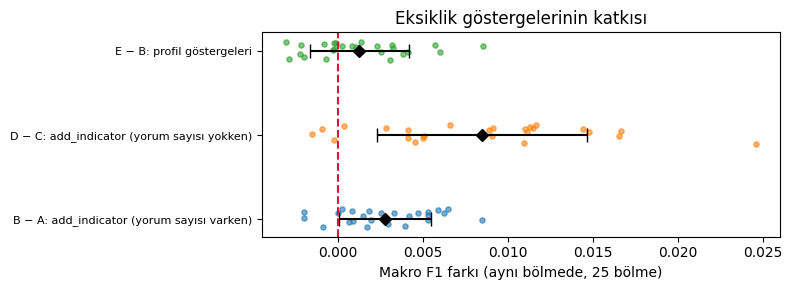

Grafik: her nokta bir bölmedeki fark, siyah elmas ortalama ± std; kırmızı çizgi 'fark yok'. Noktaların çoğu çizginin sağındaysa katkı tutarlıdır.


In [38]:
# add_indicator: "bu değer eksikti" bilgisini modele vermek bir şey katıyor mu?
def lr_hatti(**on_isleme_ayarlari):
    return Pipeline([("on", on_isleme(**on_isleme_ayarlari)), ("model", lojistik())])

yorum_sutunlari = [c for c in ["log_yorum_sayisi", "aylik_yorum"] if c in SAYISAL]
sayisal_yorumsuz = [c for c in SAYISAL if c not in yorum_sutunlari]
X_profil = X.assign(host_about_var=veri["host_about"].notna().astype(int),
                    host_location_var=veri["host_location"].notna().astype(int))

sonuc_13 = [
    degerlendir(lr_hatti(add_indicator=False), X, ad="A · medyan doldurma, gösterge yok"),
    degerlendir(lr_hatti(add_indicator=True),  X, ad="B · medyan doldurma + add_indicator"),
    degerlendir(lr_hatti(add_indicator=False, sayisal=sayisal_yorumsuz), X, ad="C · yorum sayısı yok, gösterge yok"),
    degerlendir(lr_hatti(add_indicator=True,  sayisal=sayisal_yorumsuz), X, ad="D · yorum sayısı yok, add_indicator"),
    degerlendir(lr_hatti(add_indicator=True, sayisal=SAYISAL + ["host_about_var", "host_location_var"]),
                X_profil, ad="E · B + host_about / host_location göstergeleri"),
]
display(tablo(sonuc_13))

# Eşleştirilmiş karşılaştırma: aynı 25 bölmede iki kurulumun skor farkı
def eslesmis_fark(i, j, ad):
    fark = sonuc_13[j]["_skorlar"] - sonuc_13[i]["_skorlar"]
    print(f"{ad:<45s} fark = {fark.mean():+.4f} ± {fark.std():.4f} · artış olan bölme: {int((fark > 0).sum())} / {len(fark)}")
    return fark

print("\nAynı bölmelerde farklar:")
farklar = {"B − A: add_indicator (yorum sayısı varken)": eslesmis_fark(0, 1, "B − A: add_indicator (yorum sayısı varken)"),
           "D − C: add_indicator (yorum sayısı yokken)": eslesmis_fark(2, 3, "D − C: add_indicator (yorum sayısı yokken)"),
           "E − B: profil göstergeleri":                 eslesmis_fark(1, 4, "E − B: profil göstergeleri")}

fig, ax = plt.subplots(figsize=(8, 3))
for i, (ad, f_) in enumerate(farklar.items()):
    ax.scatter(f_, np.full(len(f_), i) + np.random.default_rng(SEED).uniform(-0.12, 0.12, len(f_)), s=14, alpha=0.6)
    ax.errorbar(f_.mean(), i, xerr=f_.std(), fmt="D", color="black", capsize=5)
ax.set_yticks(range(len(farklar))); ax.set_yticklabels(list(farklar.keys()), fontsize=8)
ax.axvline(0, color="crimson", ls="--")
ax.set(xlabel="Makro F1 farkı (aynı bölmede, 25 bölme)", title="Eksiklik göstergelerinin katkısı")
plt.tight_layout(); plt.show()
print("Grafik: her nokta bir bölmedeki fark, siyah elmas ortalama ± std; kırmızı çizgi 'fark yok'. Noktaların çoğu çizginin sağındaysa katkı tutarlıdır.")

**Yorum** · `add_indicator`

**Ne bulduk:** Eksiklik göstergelerinin katkısı beş kurulumla ve aynı 25 bölmede eşleştirilmiş karşılaştırmayla ölçülmüştür:

1. **Yorum sayısı modeldeyken (B − A):** Göstergelerin katkısı küçük ve belirsizdir: +0,003 ± 0,003; 25 bölmenin 21'inde artış görülmüştür.
2. **Yorum sayısı modelden çıkarıldığında (D − C):** Katkı belirginleşmektedir: +0,008 ± 0,006; 25 bölmenin 22'sinde artış görülmüştür.
3. **Ne yorum sayısı ne gösterge varken (C):** Skor 0,617'ye düşmektedir; göstergeli kurulumlarda skor 0,625–0,630 arasındadır.
4. **Profil göstergeleri (E − B):** `host_about` ve `host_location` için eklenen göstergeler katkı yapmamaktadır: +0,001 ± 0,003; 25 bölmenin 14'ünde artış görülmüştür.

**Ne anlama geliyor:**

1. "Puan eksik" bilgisi değerlidir, ancak model bu bilgiyi yorum sayısından da alabilmektedir: yorum sayısı 0 olan ilanlar ile puanı eksik olan ilanlar aynı ilanlardır (bkz. Eksiklik analizi yorumu). İki bilgi birlikteyken gösterge tekrar eden bilgi hâline gelmektedir.
2. İkisi birden olmadığında yorumsuz ilanlar medyan puanla doldurulmakta ve model bu ilanları "ortalama puanlı ilan" gibi görmektedir; skordaki düşüş bundan kaynaklanmaktadır.
3. Gösterge zarar vermediği ve yorum sayısının bulunmadığı durumda belirgin katkı yaptığı için `add_indicator=True` ile devam edilmiştir. Bu ayar `on_isleme` fonksiyonunun varsayılanıdır ve sonraki bütün deneylerde kullanılmaktadır.
4. Profil göstergeleri katkı yapmadığı için modele eklenmemiştir.

**Neyi söyleyemeyiz:**

* Farklar çok küçüktür (0,001–0,008). Standart sapmanın altında kalan bir fark (B − A) ortalama skorlara bakılarak değil, ancak aynı bölmelerdeki eşleştirilmiş karşılaştırmayla değerlendirilebilmektedir; bu fark da tam tutarlı değildir (25 bölmenin 4'ünde azalma).
* Sonuç lojistik regresyon için geçerlidir; ağaç modelleri eksikliği farklı biçimde kullanabilir (ör. eksik değerleri ayrı bir dala gönderebilir).

### 1.4 Kategorik kodlama
Yüksek kardinaliteli bir sütunda bire-bir, nadir kategorileri birleştiren bire-bir ve kat dışı hedef kodlama; hedef kodlamanın bir kez yanlış uygulanması. Sütun olarak modelde kullanılan en çok kategorili öznitelik, `mulk_tipi` (81 kategori) seçilmiştir. Ek olarak aynı yanlış uygulama, modelde kullanılmayan iki daha yüksek kardinaliteli sütunda (ham lisans numarası ve ev sahibi kimliği) gösterilmiştir.

In [39]:
# Kategorik kodlama: yüksek kardinaliteli sütunda üç doğru yöntem + bir yanlış uygulama
sayim = X[YUKSEK_KARD].value_counts()
print(f"{YUKSEK_KARD}: {sayim.size} kategori · {int((sayim < NADIR_ESIK).sum())} kategoride {NADIR_ESIK}'dan az ilan "
      f"(toplam {int(sayim[sayim < NADIR_ESIK].sum())} ilan, %{100 * sayim[sayim < NADIR_ESIK].sum() / len(X):.1f}) · "
      f"{int((sayim == 1).sum())} kategoride yalnız 1 ilan")
print("En kalabalık 3 kategori:", (sayim.head(3) / len(X)).round(3).to_dict())

# Her yöntemin mülk tipini kaç sütuna çevirdiği (yalnız saymak için bütün veride fit; değerlendirmede kullanılmıyor)
for k in ["birebir", "nadir", "hedef"]:
    n = on_isleme(kodlama=k).fit(X, y).named_transformers_["yuksek_kard"].transform(X[[YUKSEK_KARD]]).shape[1]
    print(f"  {k:<8s}: {YUKSEK_KARD} → {n} sütun")

# (1)–(3) Doğru kurulumlar: kodlama Pipeline içinde, her katta yalnız eğitim verisinden öğrenilir
sonuc_14 = [degerlendir(lr_hatti(kodlama="birebir"), X, ad=f"(1) Bire-bir ({sayim.size} kategori)"),
            degerlendir(lr_hatti(kodlama="nadir"),   X, ad=f"(2) Bire-bir + nadirleri birleştir (<{NADIR_ESIK})"),
            degerlendir(lr_hatti(kodlama="hedef"),   X, ad="(3) Kat dışı hedef kodlama")]

# (4) YANLIŞ: hedef kodlama çapraz doğrulamadan ÖNCE, bütün veride (test katlarının etiketleri dahil) hesaplanır
def yanlis_hedef_kodla(X_, sutun):
    oranlar = pd.crosstab(X_[sutun], y, normalize="index")       # her kategoride ucuz/orta/pahalı oranı — BÜTÜN veriden
    yeni = oranlar.reindex(X_[sutun]).set_axis(X_.index)
    yeni.columns = [f"te_{sutun}_{s}" for s in SINIFLAR]
    return pd.concat([X_.drop(columns=sutun), yeni], axis=1), yeni.columns.tolist()

X_yanlis, te_sutunlari = yanlis_hedef_kodla(X, YUKSEK_KARD)
sonuc_14.append(degerlendir(lr_hatti(sayisal=SAYISAL + te_sutunlari, yuksek_kard=None), X_yanlis,
                            ad="(4) YANLIŞ: hedef kodlama bütün veride"))
display(tablo(sonuc_14))

mulk_tipi: 81 kategori · 58 kategoride 30'dan az ilan (toplam 430 ilan, %1.8) · 17 kategoride yalnız 1 ilan
En kalabalık 3 kategori: {'Entire rental unit': 0.507, 'Room in hotel': 0.137, 'Private room in rental unit': 0.083}
  birebir : mulk_tipi → 81 sütun
  nadir   : mulk_tipi → 24 sütun
  hedef   : mulk_tipi → 3 sütun
(1) Bire-bir (81 kategori)                              f1_macro = 0.628 ± 0.013
(2) Bire-bir + nadirleri birleştir (<30)                f1_macro = 0.628 ± 0.013
(3) Kat dışı hedef kodlama                              f1_macro = 0.629 ± 0.012
(4) YANLIŞ: hedef kodlama bütün veride                  f1_macro = 0.630 ± 0.012


,f1_macro_ort,f1_macro_std
kurulum,,
(1) Bire-bir (81 kategori),0.628,0.013
(2) Bire-bir + nadirleri birleştir (<30),0.628,0.013
(3) Kat dışı hedef kodlama,0.629,0.012
(4) YANLIŞ: hedef kodlama bütün veride,0.630,0.012


#### Ek gösterim: aynı hata daha yüksek kardinaliteli sütunlarda
Ham lisans numarası ve ev sahibi kimliği modelde kullanılmıyor; yalnız sızıntının büyüklüğünün kardinaliteyle ilişkisini göstermek için deneniyor.

In [40]:
# Aynı hata daha yüksek kardinaliteli sütunlarda: ham lisans numarası ve ev sahibi kimliği
from sklearn.preprocessing import TargetEncoder

def ek_sutunla_hat(sutun):
    """Temel hat + tek bir ek sütun, kat dışı hedef kodlamayla (Pipeline içinde)."""
    on = ColumnTransformer([("temel", on_isleme(), X.columns.tolist()),
                            ("ek", Pipeline([("te", TargetEncoder(target_type="multiclass", random_state=SEED)),
                                             ("olcek", StandardScaler())]), [sutun])])
    return Pipeline([("on", on), ("model", lojistik())])

ek_sutunlar = {"lisans_no": veri["license"].fillna("YOK").astype(str),   # ham lisans numarası (modelde yok; yalnız gösterim)
               "ev_sahibi": veri["host_id"].astype(str)}                # bölme grubu (modelde yok; yalnız gösterim)

sonuc_14b = [sonuc_14[1]]                                              # karşılaştırma için: (2) nadir birleştirme
for ad, deger in ek_sutunlar.items():
    s = deger.value_counts()
    print(f"\n{ad}: {s.size:,} kategori · tek ilanlık: {int((s == 1).sum()):,} · en büyük kategori: {s.iloc[0]:,} ilan ('{s.index[0]}')")
    X_ek = X.assign(**{ad: deger})
    sonuc_14b.append(degerlendir(ek_sutunla_hat(ad), X_ek, ad=f"+ {ad} · kat dışı hedef kodlama"))
    X_ek_yanlis, te = yanlis_hedef_kodla(X_ek, ad)
    sonuc_14b.append(degerlendir(lr_hatti(sayisal=SAYISAL + te), X_ek_yanlis, ad=f"+ {ad} · YANLIŞ: bütün veride"))
display(tablo(sonuc_14b))


lisans_no: 4,914 kategori · tek ilanlık: 2,709 · en büyük kategori: 7,584 ilan ('YOK')
+ lisans_no · kat dışı hedef kodlama                    f1_macro = 0.624 ± 0.012
+ lisans_no · YANLIŞ: bütün veride                      f1_macro = 0.764 ± 0.013

ev_sahibi: 8,550 kategori · tek ilanlık: 5,399 · en büyük kategori: 334 ilan ('96460850')
+ ev_sahibi · kat dışı hedef kodlama                    f1_macro = 0.617 ± 0.011
+ ev_sahibi · YANLIŞ: bütün veride                      f1_macro = 0.863 ± 0.010


,f1_macro_ort,f1_macro_std
kurulum,,
(2) Bire-bir + nadirleri birleştir (<30),0.628,0.013
+ lisans_no · kat dışı hedef kodlama,0.624,0.012
+ lisans_no · YANLIŞ: bütün veride,0.764,0.013
+ ev_sahibi · kat dışı hedef kodlama,0.617,0.011
+ ev_sahibi · YANLIŞ: bütün veride,0.863,0.010


**Yorum** · Kategorik kodlama

**Ne bulduk:**

1. **Sütun:** `mulk_tipi` (property_type) fiyatlı ilanlarda 81 kategoriye sahiptir. Bu kategorilerin 58'inde 30'dan az ilan bulunmaktadır; ancak bu nadir kategoriler toplam yalnız 430 ilanı (%1,8) kapsamaktadır. İlanların %51'i tek bir kategoridedir ("Entire rental unit").
2. **Doğru kodlamaların karşılaştırması:** Bire-bir kodlama 81, nadirleri birleştiren bire-bir kodlama 24, kat dışı hedef kodlama 3 sütun üretmektedir. Makro F1 sırasıyla 0,628 / 0,628 / 0,629 olarak hesaplanmıştır (std ≈ 0,012–0,013); üç yöntem arasında fark görülmemiştir.
3. **Yanlış hedef kodlama (`mulk_tipi`):** Oranlar bütün veride hesaplandığında skor 0,630'dur; yani şişme görülmemiştir.
4. **Yanlış hedef kodlama (daha yüksek kardinaliteli sütunlar):** Aynı hata daha yüksek kardinaliteli sütunlarda yapıldığında sonuç değişmektedir:
   * **Ham lisans numarası** (4.914 kategori, 2.709'u tek ilanlık): kat dışı kodlamayla 0,624, bütün veride kodlamayla **0,764** (+0,14).
   * **Ev sahibi kimliği** (8.550 kategori, 5.399'u tek ilanlık): kat dışı kodlamayla 0,617, bütün veride kodlamayla **0,863** (+0,25).

**Ne anlama geliyor:**

1. Sızıntının büyüklüğü kategori başına düşen ilan sayısına bağlıdır. Kalabalık bir kategoride tek bir test ilanının etiketi kategori oranını neredeyse hiç değiştirmez; bu nedenle `mulk_tipi`'nde şişme görülmemiştir. Tek ilanlık bir kategoride ise yanlış kodlama ilana doğrudan kendi etiketini verir; kardinalite ve tek ilanlık kategori sayısı arttıkça sızıntı büyümektedir.
2. Doğru kurulumda lisans numarası ve ev sahibi kimliği skoru düşürmektedir. Ev sahibine göre bölmede test katındaki ev sahipleri eğitimde hiç görülmediği için kat dışı kodlama onlara yalnız genel ortalamayı verebilmektedir. Doğru değerlendirme bu sütunların işe yaramadığını gösterirken, yanlış değerlendirme onları en değerli öznitelik gibi göstermektedir: sızıntı yalnız skoru şişirmekle kalmaz, özniteliklerin önemi hakkında da yanıltır.
3. **Karar:** Nadirleri birleştiren bire-bir kodlamayla devam edilmiştir. Başarım diğer yöntemlerle aynıdır; sütun sayısı azdır, katsayılar yorumlanabilir ve Weka'nın nominal öznitelikleriyle uyumludur.

**Neyi söyleyemeyiz:**

* `mulk_tipi`'ndeki sıfır fark, "hedef kodlama sızıntısı zararsızdır" anlamına gelmez; şişmenin büyüklüğü kategori başına düşen örnek sayısına bağlıdır.
* `TargetEncoder` eğitim katının içindeki kat dışı kodlamayı satıra göre yapmaktadır ve ev sahibini bilmemektedir. Ev sahibi düzeyindeki sütunlarda (lisans numarası, ev sahibi kimliği) aynı ev sahibinin ilanları bu iç parçalara dağıldığında eğitim kodlamaları olduğundan iyimser olur. Dış bölme ev sahibine göre yapıldığı için bu durum raporlanan test skorunu şişirmez; tersine, model eğitimde bu özniteliğe güvenmeyi öğrenip testte bilgi bulamadığı için skor düşer (0,628 → 0,624 ve 0,617). İç parçaların da ev sahibine göre ayrılması bu kötümser etkiyi azaltabilirdi; modelde kullanılan `mulk_tipi` ev sahibine özgü bir sütun olmadığı için bu etki önemsizdir.

### 1.5 Sızıntı deneyi
Ön işlemenin bütün veride yapıldığı kurulum (yanlış) ile `Pipeline` içinde yapıldığı kurulum (doğru); hata çubuklarıyla.

Lojistik regresyon · ön işleme bütün veride · satıra göre f1_macro = 0.640 ± 0.007
Lojistik regresyon · ön işleme Pipeline içinde · satıra göre f1_macro = 0.640 ± 0.007
Lojistik regresyon · ön işleme bütün veride · ev sahibine göre f1_macro = 0.630 ± 0.012
Lojistik regresyon · ön işleme Pipeline içinde · ev sahibine göre f1_macro = 0.629 ± 0.012
Karar ağacı · ön işleme bütün veride · satıra göre      f1_macro = 0.658 ± 0.006
Karar ağacı · ön işleme Pipeline içinde · satıra göre   f1_macro = 0.656 ± 0.007
Karar ağacı · ön işleme bütün veride · ev sahibine göre f1_macro = 0.582 ± 0.012
Karar ağacı · ön işleme Pipeline içinde · ev sahibine göre f1_macro = 0.577 ± 0.014


f1_macro_ort  f1_macro_std
model              on_isleme               bolme                                       
Lojistik regresyon bütün veride (yanlış)   satıra göre              0.640         0.007
                   Pipeline içinde (doğru) satıra göre              0.640         0.007
                   bütün veride (yanlış)   ev sahibine göre         0.630         0.012
                   Pipeline içinde (doğru) ev sahibine göre         0.629         0.012
Karar ağacı        bütün veride (yanlış)   satıra göre              0.658         0.006
                   Pipeline içinde (doğru) satıra göre              0.656         0.007
                   bütün veride (yanlış)   ev sahibine göre         0.582         0.012
                   Pipeline içinde (doğru) ev sahibine göre         0.577         0.014

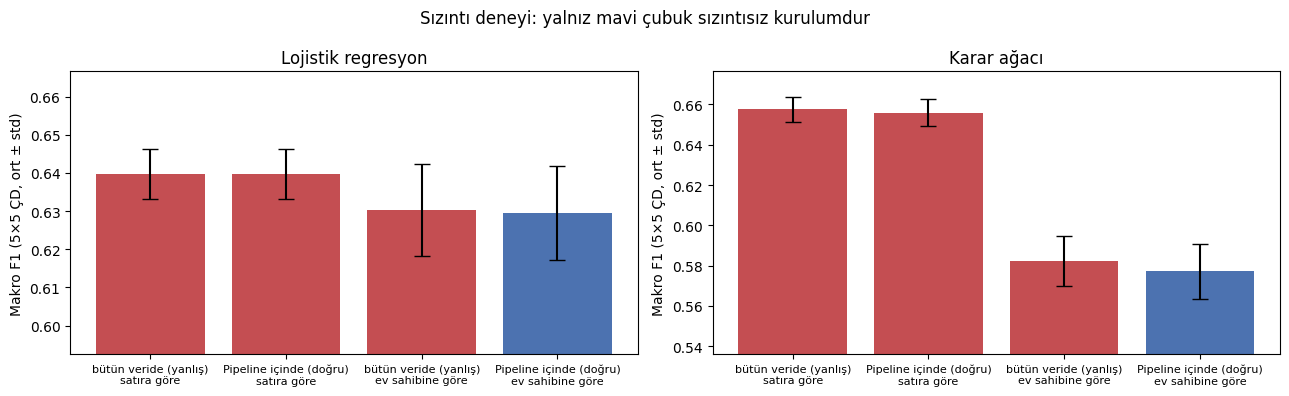

Grafik: dört kurulumun makro F1 ortalaması ve standart sapması; kırmızılar en az bir sızıntı kaynağı içeriyor. y ekseni sıfırdan başlamıyor, farkları görünür kılmak için kesildi.

Şişme (doğru kuruluma göre):
  Lojistik regresyon   doğru = 0.629 · ön işleme sızıntısı: +0.001 · bölme sızıntısı: +0.011
  Karar ağacı          doğru = 0.577 · ön işleme sızıntısı: +0.005 · bölme sızıntısı: +0.079


In [41]:
# Sızıntı deneyi: iki sızıntı kaynağı × iki model
from sklearn.tree import DecisionTreeClassifier

# Bu deneyde hatta hedefi kullanan bir adım (mülk tipi için hedef kodlama) BİLEREK var; doldurma ve ölçekleme de var.
#  · Ön işleme  YANLIŞ: bütün veride fit → sonra çapraz doğrulama   |  DOĞRU: Pipeline içinde, her katta yalnız eğitimde fit
#  · Bölme      YANLIŞ: satıra göre (ev sahibi yok sayılır)          |  DOĞRU: ev sahibine göre gruplu
modeller = {"Lojistik regresyon": lojistik,
            "Karar ağacı": lambda: DecisionTreeClassifier(min_samples_leaf=5, random_state=SEED)}

on_yanlis = on_isleme(kodlama="hedef")
Xt_yanlis = on_yanlis.fit(X, y).transform(X)     # DİKKAT: fit(X, y).transform(X) — kat dışı değil, bütün veride öğrenilmiş kodlama

sonuc_15 = []
for m_ad, m in modeller.items():
    for b_ad, cv_ in [("satıra göre", CV_SATIR), ("ev sahibine göre", CV_GRUP)]:
        r = degerlendir(m(), Xt_yanlis, cv=cv_, ad=f"{m_ad} · ön işleme bütün veride · {b_ad}")
        sonuc_15.append({**r, "model": m_ad, "on_isleme": "bütün veride (yanlış)", "bolme": b_ad})
        r = degerlendir(Pipeline([("on", on_isleme(kodlama="hedef")), ("model", m())]), X, cv=cv_,
                        ad=f"{m_ad} · ön işleme Pipeline içinde · {b_ad}")
        sonuc_15.append({**r, "model": m_ad, "on_isleme": "Pipeline içinde (doğru)", "bolme": b_ad})

s15 = pd.DataFrame(sonuc_15)
ozet15 = s15.set_index(["model", "on_isleme", "bolme"])[["f1_macro_ort", "f1_macro_std"]].round(3)
display(ozet15)

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, (m_ad, g) in zip(axs, s15.groupby("model", sort=False)):
    etiketler = [f"{r.on_isleme}\n{r.bolme}" for r in g.itertuples()]
    renk = ["#4C72B0" if (r.on_isleme.startswith("Pipeline") and r.bolme == "ev sahibine göre") else "#C44E52"
            for r in g.itertuples()]
    ax.bar(range(len(g)), g["f1_macro_ort"], yerr=g["f1_macro_std"], capsize=6, color=renk)
    ax.set_xticks(range(len(g))); ax.set_xticklabels(etiketler, fontsize=8)
    alt, ust = (g["f1_macro_ort"] - 3 * g["f1_macro_std"]).min(), (g["f1_macro_ort"] + 3 * g["f1_macro_std"]).max()
    ax.set_ylim(alt, ust); ax.set(ylabel="Makro F1 (5×5 ÇD, ort ± std)", title=m_ad)
plt.suptitle("Sızıntı deneyi: yalnız mavi çubuk sızıntısız kurulumdur"); plt.tight_layout(); plt.show()
print("Grafik: dört kurulumun makro F1 ortalaması ve standart sapması; kırmızılar en az bir sızıntı kaynağı içeriyor. "
      "y ekseni sıfırdan başlamıyor, farkları görünür kılmak için kesildi.")

# Etkileri ayrıştırma: her sızıntı kaynağı skoru ne kadar şişiriyor?
print("\nŞişme (doğru kuruluma göre):")
for m_ad in modeller:
    dogru = ozet15.loc[(m_ad, "Pipeline içinde (doğru)", "ev sahibine göre"), "f1_macro_ort"]
    on_isleme_etkisi = ozet15.loc[(m_ad, "bütün veride (yanlış)", "ev sahibine göre"), "f1_macro_ort"] - dogru
    bolme_etkisi = ozet15.loc[(m_ad, "Pipeline içinde (doğru)", "satıra göre"), "f1_macro_ort"] - dogru
    print(f"  {m_ad:<20s} doğru = {dogru:.3f} · ön işleme sızıntısı: {on_isleme_etkisi:+.3f} · bölme sızıntısı: {bolme_etkisi:+.3f}")

**Yorum** · Sızıntı deneyi

**Ne bulduk:** İki sızıntı kaynağı (ön işleme ve bölme), iki modelde (lojistik regresyon ve karar ağacı) ayrı ayrı ölçülmüştür:

1. **Ön işleme sızıntısı küçüktür:** Ön işlemeyi bütün veride yapmak ile `Pipeline` içinde yapmak arasındaki fark lojistik regresyonda +0,001, karar ağacında +0,002 ile +0,005 arasındadır; bu farklar standart sapmanın altındadır.
2. **Asıl sızıntı bölmededir:** Karar ağacı satıra göre bölmede 0,656, ev sahibine göre bölmede 0,577 skor almaktadır. Bu yaklaşık 8 puanlık bir şişmedir (≈6 standart sapma). Lojistik regresyonda şişme yalnız 1 puandır (0,640'a karşı 0,629).
3. **Sızıntı model seçimini tersine çevirmektedir:** Satıra göre bölmede karar ağacı lojistik regresyondan iyi görünmektedir (0,656'ya karşı 0,640); ev sahibine göre bölmede ise sıralama tersine dönmektedir (0,577'ye karşı 0,629).
4. **Standart sapma:** Ev sahibine göre bölmede standart sapma yaklaşık iki kattır (0,012–0,014'e karşı 0,006–0,007).

**Ne anlama geliyor:**

1. Ön işleme adımlarının çoğu (medyan doldurma, ölçekleme) hedefi kullanmamaktadır ve 24 bin ilanlık veride kararlıdır. Hedefi kullanan tek adım, kalabalık kategorili bir sütundaki hedef kodlamadır (1.4). Bu, `Pipeline`'ın gereksiz olduğu anlamına gelmez: 1.4'te aynı hata yüksek kardinaliteli sütunlarda +0,14 ve +0,25 şişme yaratmıştır.
2. Bölme sızıntısı, Kaufman vd.'nin tanımladığı eğitim örneği sızıntısıdır. Esnek bir model olan karar ağacı, aynı ev sahibinin neredeyse aynı ilanlarını eğitimde ezberleyip test katında tanımaktadır; doğrusal bir model olan lojistik regresyon ise bu ilanları ezberleyememektedir.
3. Yanlış bölmeyle model seçilseydi, daha önce görmediği ev sahiplerinde 5 puan daha kötü olan model seçilirdi. Sızıntı yalnız skoru şişirmez, yanlış kararlara da yol açar.
4. Ev sahibine göre bölmede standart sapmanın daha yüksek olması, katların ev sahibi bileşiminin daha değişken olmasından kaynaklanmaktadır.
5. **Karar:** Bundan sonraki bütün deneyler `CV_GRUP` (5 kat × 5 tekrar, ev sahibine göre katmanlı ve gruplu bölme) ile yapılacaktır. Bu bölme, "daha önce görülmemiş bir ev sahibinin ilanı" durumunu taklit etmektedir.

**Neyi söyleyemeyiz:**

* Hangi bölmenin "doğru" olduğu kullanım senaryosuna bağlıdır. Örneğin platformda zaten çok ilanı olan bir ev sahibinin yeni ilanı tahmin edilecek olsaydı, satıra göre bölme kısmen meşru olabilirdi.
* Ev sahibine göre bölme, ev sahibi dışındaki bağımlılıkları dışlamaz; örneğin aynı binada farklı ev sahiplerine ait ilanlar hâlâ eğitim ve test katlarına dağılabilir.
* "Mevcut ilan" senaryosu ile bu bölme birbiriyle çelişmez: ilan platformda bulunduğu için yorum ve puanları bilinmektedir, ancak model eğitimde o ilanın ev sahibini hiç görmemiş olarak değerlendirilmektedir.

#### Kontrol: eşikleri bütün veriden hesaplamak sızıntı yaratıyor mu?
Hedef eşikleri bütün veriden hesaplanıyor; bu, test katlarının fiyat dağılımının hedef tanımına girmesi demek. Etkisini ölçmek için eşikler her bölmede yalnız eğitim ilanlarından yeniden hesaplanıyor.

In [42]:
# Kontrol: hedef eşikleri yalnız eğitim katından hesaplansaydı değişir miydi?
# Eşikler bütün veriden hesaplanıyor (hedefin tanımı). Test katının fiyatlarının etkisini ölçmek için
# her bölmede tercilleri YALNIZ eğitim ilanlarından yeniden hesaplayıp test ilanlarının etiketlerini karşılaştırıyoruz.
kat_esikleri, degisen = [], []
for tr, te in CV_GRUP:
    e = (veri["fiyat"].iloc[tr].quantile([1/3, 2/3]) / YUVARLAMA).round().mul(YUVARLAMA).astype(int).tolist()
    kat_esikleri.append(e)
    yeni_etiket = pd.cut(veri["fiyat"].iloc[te], [-np.inf, *e, np.inf], labels=False, right=False).to_numpy()
    degisen.append((yeni_etiket != y[te]).mean())
kat_esikleri = np.array(kat_esikleri)
print(f"Bütün veriden eşikler: {ESIKLER_MODEL} TL")
print(f"Yalnız eğitim katından eşikler (25 bölme): alt sınır {sorted({int(v) for v in kat_esikleri[:, 0]})}, üst sınır {sorted({int(v) for v in kat_esikleri[:, 1]})}")
print(f"Test ilanlarında etiketi değişen oran: ortalama %{100 * np.mean(degisen):.2f}, en fazla %{100 * np.max(degisen):.2f}")

Bütün veriden eşikler: [2750, 5100] TL
Yalnız eğitim katından eşikler (25 bölme): alt sınır [2650, 2700, 2750], üst sınır [5000, 5050, 5100, 5150, 5200]
Test ilanlarında etiketi değişen oran: ortalama %0.98, en fazla %4.18


**Yorum** · Eşik kontrolü

**Ne bulduk:** Eşikler 25 bölmenin her birinde yalnız eğitim ilanlarından yeniden hesaplandığında alt sınır 2.650–2.750 TL, üst sınır 5.000–5.200 TL arasında çıkmaktadır. Test ilanlarının ortalama %0,98'inin (en fazla %4,18'inin) etiketi değişmektedir.

**Ne anlama geliyor:** Eşiklerin bütün veriden hesaplanması teorik olarak test ilanlarının fiyat bilgisini hedef tanımına taşır; ancak bu veride etkisi küçüktür. Her eğitim katında yaklaşık 19.600 ilan bulunduğu için terciller en fazla 100–150 TL oynamakta ve yalnız sınıra çok yakın ilanların etiketi değişmektedir (ortalama yüzde 1'in altında). Bu nedenle eşikler hedefin tanımı olarak bütün veriden bir kez hesaplanmış ve bütün katlarda aynı hedef kullanılmıştır.

**Neyi söyleyemeyiz:** Sonuç bu veri büyüklüğüne ve yuvarlama kuralına bağlıdır; daha küçük bir veri kümesinde ya da yuvarlama yapılmadan eşikler katlar arasında değişebilir ve sınıra yakın ilanların etiketleri farklılaşabilir.

### 1.6 Baseline ve ilk model

`DummyClassifier` ve tek bir basit model (lojistik regresyon), sızıntısız hat içinde ve ev sahibine göre tekrarlı çapraz doğrulamayla (5 kat × 5 tekrar).

Baseline · en sık sınıf (ZeroR)                         f1_macro = 0.163 ± 0.007
Baseline · sınıf oranlarıyla rastgele                   f1_macro = 0.334 ± 0.006
Lojistik regresyon (sızıntısız hat)                     f1_macro = 0.628 ± 0.013


,f1_macro_ort,f1_macro_std,balanced_accuracy_ort,balanced_accuracy_std,accuracy_ort,accuracy_std
kurulum,,,,,,
Baseline · en sık sınıf (ZeroR),0.163,0.007,0.333,0.000,0.324,0.018
Baseline · sınıf oranlarıyla rastgele,0.334,0.006,0.335,0.006,0.335,0.006
Lojistik regresyon (sızıntısız hat),0.628,0.013,0.628,0.013,0.629,0.013


Lojistik regresyon − rastgele baseline: +0.294 ± 0.015 (25 bölmenin 25'inde üstün)


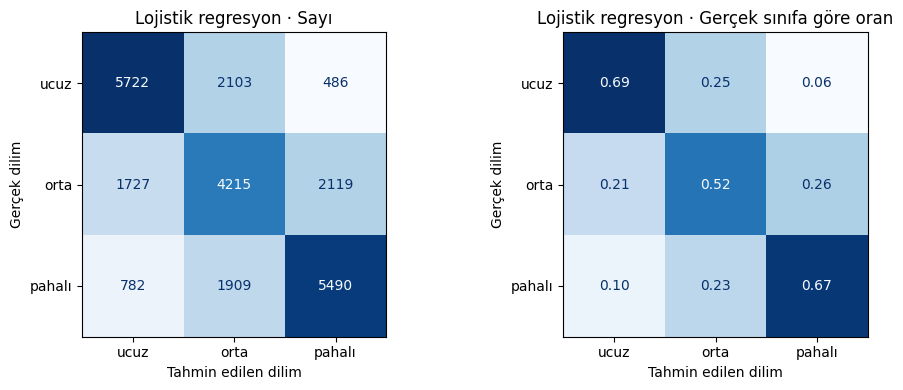

Grafik: satırlar gerçek, sütunlar tahmin edilen dilim; köşegen doğru tahminler.
Hataların %14'i 'ucuz ↔ pahalı' atlaması; geri kalanı komşu dilimler arasında.

'Pahalı' ile 'ucuz' arasındaki farkı en çok belirleyen öznitelikler
(log[P(pahalı) / P(ucuz)] üzerindeki etki · sayısallar ölçekli, kategorikler 0/1 → ölçekler farklı; yalnız yön olarak okunmalı):
kategorik__ilce_Silivri                     2.21
kategorik__ilce_Adalar                      2.01
kategorik__ilce_Zeytinburnu                 1.73
sayisal__kapasite                           1.56
kategorik__ilce_Catalca                     1.50
kategorik__oda_tipi_Hotel room              1.37
kategorik__ilce_Sariyer                     1.12
kategorik__ilce_Buyukcekmece                0.91
kategorik__ilce_Sultanbeyli                -1.69
yuksek_kard__mulk_tipi_Boat                -1.51
yuksek_kard__mulk_tipi_Entire guesthouse   -1.49
kategorik__ilce_Sancaktepe                 -1.44
kategorik__ilce_Sile                       -1.39
katego

In [43]:
# Baseline ve ilk model (sızıntısız hat, ev sahibine göre 5×5 ÇD)
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

OLCUTLER = ("f1_macro", "balanced_accuracy", "accuracy")
ILK_MODEL = lr_hatti()                                 # medyan + add_indicator, nadirleri birleştiren bire-bir

sonuc_16 = [
    degerlendir(DummyClassifier(strategy="most_frequent"), X, ad="Baseline · en sık sınıf (ZeroR)", olcutler=OLCUTLER),
    degerlendir(DummyClassifier(strategy="stratified", random_state=SEED), X, ad="Baseline · sınıf oranlarıyla rastgele", olcutler=OLCUTLER),
    degerlendir(ILK_MODEL, X, ad="Lojistik regresyon (sızıntısız hat)", olcutler=OLCUTLER),
]
display(tablo(sonuc_16))
fark = sonuc_16[2]["_skorlar"] - sonuc_16[1]["_skorlar"]
print(f"Lojistik regresyon − rastgele baseline: {fark.mean():+.3f} ± {fark.std():.3f} (25 bölmenin {int((fark > 0).sum())}'inde üstün)")

# Karışıklık matrisi: ilk 5 bölme (= bir tam 5 katlı tur) — her ilan tam bir kez test ediliyor
tahmin = cross_val_predict(ILK_MODEL, X, y, cv=CV_GRUP[:5], n_jobs=-1)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, norm, baslik, bicim in [(ax[0], None, "Sayı", "d"), (ax[1], "true", "Gerçek sınıfa göre oran", ".2f")]:
    ConfusionMatrixDisplay(confusion_matrix(y, tahmin, normalize=norm), display_labels=SINIFLAR).plot(
        ax=a, cmap="Blues", values_format=bicim, colorbar=False)
    a.set(xlabel="Tahmin edilen dilim", ylabel="Gerçek dilim", title=f"Lojistik regresyon · {baslik}")
plt.tight_layout(); plt.show()
cm = confusion_matrix(y, tahmin)
print("Grafik: satırlar gerçek, sütunlar tahmin edilen dilim; köşegen doğru tahminler.")
print(f"Hataların %{100 * (cm[0, 2] + cm[2, 0]) / (cm.sum() - np.trace(cm)):.0f}'i 'ucuz ↔ pahalı' atlaması; geri kalanı komşu dilimler arasında.")

# Model neye bakıyor? (bütün veride fit — yalnız yorum için; skor raporunda kullanılmıyor)
ILK_MODEL.fit(X, y)
adlar = ILK_MODEL.named_steps["on"].get_feature_names_out()
katsayi = pd.Series(ILK_MODEL.named_steps["model"].coef_[2] - ILK_MODEL.named_steps["model"].coef_[0], index=adlar)
print("\n'Pahalı' ile 'ucuz' arasındaki farkı en çok belirleyen öznitelikler")
print("(log[P(pahalı) / P(ucuz)] üzerindeki etki · sayısallar ölçekli, kategorikler 0/1 → ölçekler farklı; yalnız yön olarak okunmalı):")
print(pd.concat([katsayi.nlargest(8), katsayi.nsmallest(8)]).round(2).to_string())

**Yorum** · Baseline ve ilk model

**Ne bulduk:**

1. **Ölçüt:** Ana ölçüt makro F1'dir; her fiyat dilimine eşit ağırlık verir. En sık sınıf baseline'ı (ZeroR) bu seçimin neden gerekli olduğunu göstermektedir: ev sahibine göre bölmede doğruluğu 0,324'tür, ancak "orta" ve "pahalı" sınıflarını hiç bulamadığı için makro F1'i 0,163'tür.
2. **Sonuç:** Sınıf oranlarıyla rastgele tahmin 0,334 skor almaktadır. Lojistik regresyon sızıntısız hatta **0,628 ± 0,013** skor almaktadır (dengeli doğruluk 0,628 ± 0,013). Lojistik regresyon rastgele baseline'dan 25 bölmenin 25'inde daha iyidir (fark +0,294 ± 0,015).
3. **Hatalar:** Ucuz ilanların %69'u, pahalı ilanların %67'si doğru dilimde tahmin edilmektedir; orta dilim en zor sınıftır (%52). Hataların yalnız %14'ü "ucuz ↔ pahalı" atlamasıdır; geri kalanı komşu dilimler arasındadır.
4. **Öznitelikler:** "Pahalı" yönünde en güçlü katsayılar bazı ilçeler (Silivri, Adalar, Zeytinburnu, Çatalca, Sarıyer), kapasite ve otel odasıdır. "Ucuz" yönünde ise bazı çevre ilçeler (Sultanbeyli, Sancaktepe, Şile, Tuzla), tekne ve misafirhane, paylaşımlı oda ve uzun en az konaklama (`log_min_gece`) yer almaktadır.

**Ne anlama geliyor:**

1. Doğruluk, bir sınıfı tamamen görmezden gelen modeli gizlemektedir; makro F1 ise bu modeli cezalandırmaktadır. Sınıflar dengeli olduğu için lojistik regresyonda üç ölçüt neredeyse aynıdır; ölçütler ancak model bir sınıfı ihmal ettiğinde birbirinden ayrılır.
2. Model şanstan belirgin biçimde iyidir, ancak ilanların yaklaşık üçte biri hâlâ yanlış dilimde tahmin edilmektedir.
3. Hataların çoğunun komşu dilimler arasında olması, modelin fiyat sırasını büyük ölçüde öğrendiğini, ancak sınırlarda kararsız kaldığını göstermektedir. Orta dilimin en zor sınıf olmasının nedeni, iki komşusuyla da sınır paylaşmasıdır.
4. Katsayılar şöyle okunmalıdır: çok sınıflı lojistik regresyonda her sınıfın katsayısı tek başına yorumlanamaz; yorumlanabilen, iki sınıf arasındaki farktır. Burada kullanılan fark (`pahalı − ucuz`), bir özniteliğin bir ilanı ucuzdan pahalıya ne kadar ittiğini gösterir.
5. `log_min_gece`'nin "ucuz" yönünde çıkması büyük olasılıkla bir ölçüm etkisidir: 100 gecelik tekliflerin gece başı fiyatı düşüktür (1.1). Ancak bu öznitelik en güçlü 16 katsayının sonuncusudur; ilçe ve oda tipi daha belirleyicidir.
6. Silivri ve Çatalca'nın "pahalı" yönünde çıkması, bu ilçelerdeki az sayıdaki ilanın büyük ve müstakil evlerden oluşmasından kaynaklanıyor olabilir.

**Neyi söyleyemeyiz:**

* Katsayılar nedensel değildir: "ev Silivri'de olduğu için pahalıdır" sonucu çıkarılamaz. Sayısal öznitelikler ölçekli, kategorik öznitelikler 0/1 olduğu için katsayıların büyüklükleri birbiriyle karşılaştırılamaz; ayrıca modelin düzenlileştirme cezası (L2) ve birbiriyle ilişkili öznitelikler büyüklükleri etkiler. Bu nedenle katsayılar yalnız yön olarak okunmuştur.
* Silivri ve Çatalca için önerilen açıklama bir tahmindir; bu ilçelerdeki ilanların türü ayrıca incelenmemiştir.
* 0,628 gerçekleşen kira için değil, Eylül 2026 teklif fiyatının dilimi için ve daha önce görülmemiş ev sahiplerinin ilanları için geçerlidir.

### 1.7 Weka ile bağımsız kontrol
Aynı veride Weka'nın ZeroR ve J48 sınıflandırıcıları 10 katlı çapraz doğrulamayla çalıştırılmış ve sonuçların Python ile tutarlı olup olmadığı karşılaştırılmıştır.

**Yöntem:** Model tablosu Weka'nın veri biçimi olan ARFF dosyasına yazılmıştır (eksikler `?`, kategorik öznitelikler nominal). Weka'nın kendi programı (`weka.jar`, sürüm 3.9.7) Java ile komut satırından çalıştırılmıştır; bu, Explorer'da *Classify → Cross-validation, Folds = 10* seçeneğiyle aynı sonucu verir ve defterin baştan sona otomatik çalışmasını sağlar. J48 varsayılan ayarlarıyla kullanılmıştır (`-C 0.25 -M 2`).

In [45]:
from pathlib import Path
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold

# Weka için ARFF: model tablosunun aynısı (dönüşümler satır içi; eksikler '?'), sınıf en sonda
def arff_yaz(X_, y_, yol, ad="airbnb_istanbul_fiyat_dilimi"):
    tirnak = lambda v: "'" + str(v).replace("\\", "\\\\").replace("'", "\\'") + "'"
    sinif_adlari = ["ucuz", "orta", "pahali"]                       # ASCII: Weka'da karakter kodlaması sorunu çıkmasın
    satirlar = [f"@relation {ad}", ""]
    for c in X_.columns:
        if c in SAYISAL:
            satirlar.append(f"@attribute {c} numeric")
        else:
            satirlar.append(f"@attribute {c} {{{','.join(tirnak(v) for v in sorted(X_[c].dropna().unique()))}}}")
    satirlar += [f"@attribute fiyat_dilimi {{{','.join(sinif_adlari)}}}", "", "@data"]
    for r, hedef in zip(X_.itertuples(index=False), y_):
        degerler = ["?" if pd.isna(v) else (f"{v:.6g}" if c in SAYISAL else tirnak(v)) for c, v in zip(X_.columns, r)]
        satirlar.append(",".join(degerler + [sinif_adlari[hedef]]))
    Path(yol).write_text("\n".join(satirlar), encoding="utf-8")

ARFF_YOLU = "weka_airbnb_istanbul.arff"       # veri dosyasıdır: GitHub'a konmaz (.gitignore)
arff_yaz(X, y, ARFF_YOLU)
print(f"{ARFF_YOLU} yazıldı: {X.shape[0]:,} satır, {X.shape[1]} öznitelik + sınıf")

# Weka'nın yaptığının Python karşılığı: 10 katlı, satıra göre katmanlı ÇD (Weka ev sahibi grubunu bilmez)
cv10_satir = list(StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED).split(X, y))
cv10_grup = list(StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED).split(X, y, gruplar))
agac = Pipeline([("on", ColumnTransformer([("sayisal", "passthrough", SAYISAL),           # ağaç NaN'ı kendisi işler
                                            ("kategorik", OneHotEncoder(handle_unknown="ignore", sparse_output=False), KATEGORIK + [YUKSEK_KARD])])),
                 ("model", DecisionTreeClassifier(min_samples_leaf=2, random_state=SEED))])   # J48 varsayılanı -M 2
sonuc_17 = []
for ad, m in [("ZeroR karşılığı: Dummy en sık sınıf", DummyClassifier(strategy="most_frequent")), ("J48 karşılığı: karar ağacı", agac)]:
    for b_ad, cv_ in [("10 kat, satıra göre", cv10_satir), ("10 kat, ev sahibine göre", cv10_grup)]:
        sonuc_17.append(degerlendir(m, X, cv=cv_, ad=f"{ad} · {b_ad}", olcutler=("accuracy", "f1_macro")))
display(tablo(sonuc_17))

weka_airbnb_istanbul.arff yazıldı: 24,553 satır, 24 öznitelik + sınıf
ZeroR karşılığı: Dummy en sık sınıf · 10 kat, satıra göre accuracy = 0.338 ± 0.000
ZeroR karşılığı: Dummy en sık sınıf · 10 kat, ev sahibine göre accuracy = 0.326 ± 0.021
J48 karşılığı: karar ağacı · 10 kat, satıra göre        accuracy = 0.657 ± 0.006
J48 karşılığı: karar ağacı · 10 kat, ev sahibine göre   accuracy = 0.581 ± 0.016


,accuracy_ort,accuracy_std,f1_macro_ort,f1_macro_std
kurulum,,,,
"ZeroR karşılığı: Dummy en sık sınıf · 10 kat, satıra göre",0.338,0.000,0.169,0.000
"ZeroR karşılığı: Dummy en sık sınıf · 10 kat, ev sahibine göre",0.326,0.021,0.164,0.008
"J48 karşılığı: karar ağacı · 10 kat, satıra göre",0.657,0.006,0.656,0.007
"J48 karşılığı: karar ağacı · 10 kat, ev sahibine göre",0.581,0.016,0.579,0.016


In [46]:
# Weka: ZeroR ve J48, 10 katlı çapraz doğrulama (Explorer → Classify → Cross-validation, Folds = 10 ile aynı).
#  Masaüstü Weka gerekmez: 3.4'teki gibi Weka 3.8'in kendi weka.jar'ı Java ile komut satırından çalıştırılır.
#  -x 10: 10 kat · -s 1: Weka'nın varsayılan tohumu (Explorer'daki "Random seed = 1") · J48 varsayılanları: -C 0.25 -M 2
#  weka.jar ve _weka/ klasörü GitHub'a konmaz (.gitignore)
import glob, os, re, shutil, subprocess, sys, tarfile

def weka_jar():
    """python-weka-wrapper3 kaynak paketinin içindeki weka.jar'ı (Weka 3.8) çıkarır; paket KURULMAZ, yalnız indirilir."""
    if os.path.exists("weka.jar"):
        return "weka.jar"
    subprocess.run([sys.executable, "-m", "pip", "download", "-q", "python-weka-wrapper3==0.3.3",
                    "--no-deps", "--no-binary", ":all:", "-d", "_weka"], check=True)
    with tarfile.open(glob.glob("_weka/*.tar.gz")[0]) as t:
        uye = next(m for m in t.getmembers() if m.name.endswith("/weka/lib/weka.jar"))
        with open("weka.jar", "wb") as f:
            f.write(t.extractfile(uye).read())
    return "weka.jar"

if shutil.which("java") is None:                      # Colab'da genelde Java vardır; yoksa kur
    subprocess.run("apt-get -qq install -y default-jre-headless > /dev/null", shell=True)

def weka_cv(sinif, *secenek):
    komut = ["java", "--add-opens", "java.base/java.lang=ALL-UNNAMED", "-Xmx2g", "-cp", weka_jar(),
             sinif, "-t", ARFF_YOLU, "-x", "10", "-s", "1", "-o", "-v", *secenek]
    cikti = subprocess.run(komut, capture_output=True, text=True).stdout
    return cikti[cikti.find("=== Stratified cross-validation ==="):].strip()

weka_cikti = {"ZeroR": weka_cv("weka.classifiers.rules.ZeroR"),
              "J48":   weka_cv("weka.classifiers.trees.J48", "-C", "0.25", "-M", "2")}

def weka_karisiklik_oku(metin):
    """'=== Confusion Matrix ===' bölümündeki 3×3 tabloyu okur (satır = gerçek sınıf: ucuz, orta, pahali)."""
    tablo = metin.split("=== Confusion Matrix ===")[1]
    return [[int(v) for v in satir.split("|")[0].split()] for satir in tablo.splitlines() if "|" in satir and "=" in satir]

weka_karisiklik = {ad: weka_karisiklik_oku(m) for ad, m in weka_cikti.items()}

def karisikliktan_olcut(cm):
    cm = np.asarray(cm, dtype=float)
    dogru = np.diag(cm)
    kesinlik = np.divide(dogru, cm.sum(0), out=np.zeros(3), where=cm.sum(0) > 0)
    duyarlilik = dogru / cm.sum(1)
    f1 = np.divide(2 * kesinlik * duyarlilik, kesinlik + duyarlilik, out=np.zeros(3), where=(kesinlik + duyarlilik) > 0)
    return {"accuracy": dogru.sum() / cm.sum(), "f1_macro": f1.mean()}

for ad, metin in weka_cikti.items():
    print(f"=== {ad} ===")
    print(metin, "\n")
for ad, cm in weka_karisiklik.items():
    print(f"Weka {ad:<6s}", {k: round(float(v), 3) for k, v in karisikliktan_olcut(cm).items()})


=== ZeroR ===
=== Stratified cross-validation ===

Correctly Classified Instances        8311               33.8492 %
Incorrectly Classified Instances     16242               66.1508 %
Kappa statistic                          0     
Mean absolute error                      0.4444
Root mean squared error                  0.4714
Relative absolute error                100      %
Root relative squared error            100      %
Total Number of Instances            24553     


=== Detailed Accuracy By Class ===

                 TP Rate  FP Rate  Precision  Recall   F-Measure  MCC      ROC Area  PRC Area  Class
                 1.000    1.000    0.338      1.000    0.506      ?        0.500     0.338     ucuz
                 0.000    0.000    ?          0.000    ?          ?        0.500     0.328     orta
                 0.000    0.000    ?          0.000    ?          ?        0.500     0.333     pahali
Weighted Avg.    0.338    0.338    ?          0.338    ?          ?        0.500  

**Yorum** · Weka ile bağımsız kontrol

**Ne bulduk:**

1. **ZeroR:** Weka'nın ZeroR doğruluğu 0,338'dir (8.311 / 24.553); Python'daki karşılığı (en sık sınıf baseline'ı) ile **tam olarak** aynıdır. Karışıklık matrisi de ZeroR'ın bütün ilanlara "ucuz" dediğini göstermektedir.
2. **J48:** Weka'nın J48 doğruluğu 0,698, makro F1'i 0,696'dır. Python'daki karar ağacı aynı türden (satıra göre, 10 katlı) çapraz doğrulamada 0,657 doğruluk almaktadır; fark yaklaşık 4 puandır.
3. **Sınıf bazında:** J48 ucuz ilanların %79'unu, pahalı ilanların %72'sini, orta ilanların ise %58'ini doğru bulmaktadır.
4. **Bölme etkisi:** Python ağacı ev sahibine göre bölmede 0,581 doğruluk almaktadır; satıra göre bölmedeki 0,657'den yaklaşık 8 puan düşüktür.

**Ne anlama geliyor:**

1. ZeroR'ın iki araçta birebir aynı sonucu vermesi, Weka ile Python'un veriyi ve sınıfları aynı biçimde okuduğunu göstermektedir. ARFF dosyası model tablosunun aynısından yazıldığı için iki araç aynı veri üzerinde çalışmıştır.
2. J48 ile Python ağacı arasındaki 4 puanlık fark beklenen yöndedir. J48 budamalıdır (C = 0,25) ve kategorik özniteliklerde her kategori için ayrı dal açar; scikit-learn ağacı ise budamasızdır, her düğümde ikiye böler ve eksik değerleri farklı işler. Budamalı ağacın yeni verilere daha iyi genelleme yapması beklenir. Budamanın etkisi Ek paket 1'de ayrıca incelenmektedir.
3. Orta dilimin iki araçta da en zor sınıf olması, 1.6'daki bulguyu doğrulamaktadır: orta dilim iki komşusuyla da sınır paylaşmaktadır.
4. Weka'nın 10 katlı çapraz doğrulaması satıra göre katmanlıdır ve ev sahibi bilgisini kullanamaz. Bu nedenle Weka ile karşılaştırılacak Python sonuçları "satıra göre" sonuçlardır. Weka'nın 0,698'lik skoru da Python ağacının ev sahibine göre bölmedeki skorundan (0,581) yüksektir; bu fark büyük ölçüde 1.5'te ölçülen bölme şişmesinden kaynaklanmaktadır.

**Neyi söyleyemeyiz:**

* Weka kontrolü hesaplamaların doğru yapıldığını gösterir, kurulumun sızıntısız olduğunu göstermez: iki araç aynı satır bölme hatasını yaptığında sonuçlar "tutarlı" görünür, ancak ikisi birlikte şişmiş olur.
* J48'in ev sahibine göre bölmedeki skoru ölçülmemiştir; Weka'nın grafik arayüzü ve komut satırı grup bilgisiyle bölme yapamamaktadır. Bu nedenle J48 ile Python ağacı arasındaki 4 puanlık farkın ev sahibine göre bölmede de aynı kalıp kalmadığını söyleyemeyiz.

# Bölüm 2 · Sınıflandırma ve dürüst model değerlendirme *(ağırlık 30)*
**Makale:** Dietterich (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation*, 10(7).

**Okuma notu (3–4 cümle):** Dietterich bu makalede iki modeli karşılaştırırken hangi istatistiksel testin güvenilir olduğunu araştırıyor. Aynı veriden üretilen bölmeler birbirine çok benzediği için bazı yaygın testler gerçekte fark yokken "fark var" diyebiliyor. Makale, model bir kez eğitilebiliyorsa McNemar testini, on kez eğitilebiliyorsa 5×2 çapraz doğrulama testini öneriyor. Biz 2.4'te ikisini de kullandık ve bölmeleri ev sahibine göre yaptık.

### 2.1 Model karşılaştırması
Baseline, karar ağacı, k-NN, rastgele orman, gradyan artırma; tekrarlı katmanlı ÇD; ortalama ± std tablosu ve kutu grafiği; ölçüt seçiminin gerekçesi.

Dummy · en sık sınıf           makro F1 = 0.163 ± 0.007   (    5 sn)
Dummy · sınıf oranlarıyla      makro F1 = 0.334 ± 0.006   (    5 sn)
Lojistik regresyon (1.6)       makro F1 = 0.628 ± 0.013   (   41 sn)
Karar ağacı · sınırsız         makro F1 = 0.564 ± 0.011   (   21 sn)
Karar ağacı · yaprak ≥ 20      makro F1 = 0.599 ± 0.013   (   14 sn)
k-NN · k = 15 (ölçekli)        makro F1 = 0.602 ± 0.012   (  239 sn)


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Rastgele orman · 300 ağaç      makro F1 = 0.663 ± 0.014   (  419 sn)
Gradyan artırma (HistGB)       makro F1 = 0.667 ± 0.015   (  152 sn)


,makro_F1_ort,makro_F1_std,dengeli_dogruluk_ort,egitim_makro_F1,fark_egitim_test,sure_sn
model,,,,,,
Dummy · en sık sınıf,0.163,0.007,0.333,0.169,0.006,5.247
Dummy · sınıf oranlarıyla,0.334,0.006,0.335,0.333,-0.001,4.957
Lojistik regresyon (1.6),0.628,0.013,0.628,0.646,0.017,41.325
Karar ağacı · sınırsız,0.564,0.011,0.563,1.000,0.436,20.540
Karar ağacı · yaprak ≥ 20,0.599,0.013,0.600,0.744,0.145,13.523
k-NN · k = 15 (ölçekli),0.602,0.012,0.603,0.724,0.122,238.876
Rastgele orman · 300 ağaç,0.663,0.014,0.663,0.953,0.290,418.732
Gradyan artırma (HistGB),0.667,0.015,0.667,0.855,0.188,151.973


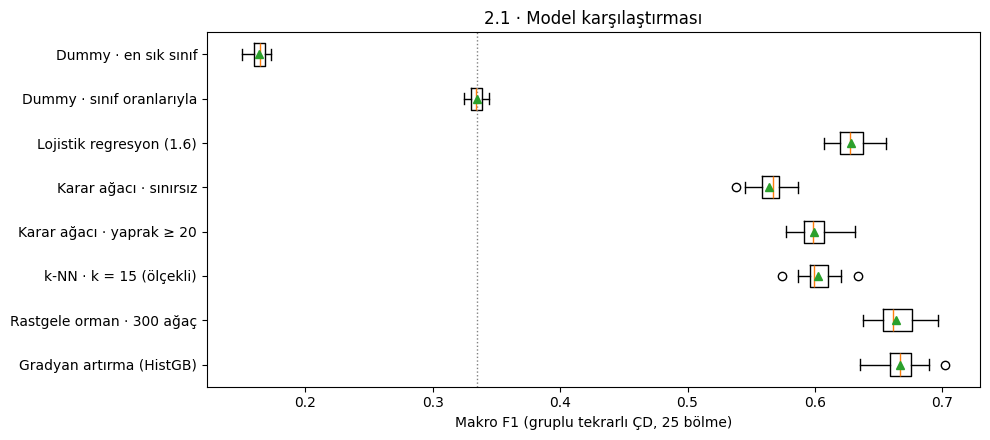

Grafik: kutu = çeyrekler arası aralık, çizgi = medyan, üçgen = ortalama; noktalı çizgi rastgele tahmin düzeyi.
Rastgele orman · 300 ağaç − Lojistik regresyon (1.6): +0.035 ± 0.008 (25 bölmenin 25'inde önde)
Gradyan artırma (HistGB) − Rastgele orman · 300 ağaç: +0.003 ± 0.008 (25 bölmenin 17'inde önde)
k-NN · k = 15 (ölçekli) − Karar ağacı · yaprak ≥ 20: +0.003 ± 0.010 (25 bölmenin 17'inde önde)
Not: bölmeler aynı veriden üretildiği için bu 25 fark bağımsız değil; anlamlılık testi 2.4'te (gruplu 5×2 ÇD).


In [22]:
# =====================================================================
# 2.1 Model karşılaştırması
# Önkoşul: defterdeki "Model tablosu ve ortak değerlendirme hattı" hücreleri
# çalışmış olmalı (X, y, CV_GRUP, on_isleme, lojistik, SEED, SINIFLAR).
# Bütün modeller AYNI 25 bölmede (CV_GRUP) ve AYNI ön işleme hattında koşar;
# böylece farklar yalnız modelden gelir.
# =====================================================================
import time
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

OLCUTLER_21 = ["f1_macro", "balanced_accuracy"]   # ana ölçüt + ikincil ölçüt

def hat_kur(model, yogun=False):
    """Ortak ön işleme (1.3 ve 1.4 kararları) + model.
    yogun=True: HistGradientBoosting seyrek (sparse) matris kabul etmediği için çıktı yoğun yapılır."""
    on = on_isleme(kodlama="nadir", add_indicator=True)
    if yogun:
        on.set_params(sparse_threshold=0)
    return Pipeline([("on", on), ("model", model)])

# Hiperparametreler bilerek SABİT ve önceden seçildi (ayar yok): aynı ÇD'de hem ayar yapıp
# hem skor raporlamak optimist yanlılık üretir; ayar işi 2.3'te iç içe ÇD ile yapılacak.
MODELLER_21 = {
    "Dummy · en sık sınıf":        hat_kur(DummyClassifier(strategy="most_frequent")),
    "Dummy · sınıf oranlarıyla":    hat_kur(DummyClassifier(strategy="stratified", random_state=SEED)),
    "Lojistik regresyon (1.6)":     hat_kur(lojistik()),
    "Karar ağacı · sınırsız":       hat_kur(DecisionTreeClassifier(random_state=SEED)),
    "Karar ağacı · yaprak ≥ 20":    hat_kur(DecisionTreeClassifier(min_samples_leaf=20, random_state=SEED)),
    "k-NN · k = 15 (ölçekli)":      hat_kur(KNeighborsClassifier(n_neighbors=15)),
    "Rastgele orman · 300 ağaç":    hat_kur(RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                                                   n_jobs=-1, random_state=SEED)),
    "Gradyan artırma (HistGB)":     hat_kur(HistGradientBoostingClassifier(random_state=SEED), yogun=True),
}

sonuc_21, skorlar_21 = [], {}
for ad, hat in MODELLER_21.items():
    t0 = time.time()
    s = cross_validate(hat, X, y, cv=CV_GRUP, scoring=OLCUTLER_21,
                       return_train_score=True, n_jobs=-1)
    skorlar_21[ad] = s["test_f1_macro"]                     # 25 değer → kutu grafiği ve 2.4
    sonuc_21.append({
        "model": ad,
        "makro_F1_ort": s["test_f1_macro"].mean(),
        "makro_F1_std": s["test_f1_macro"].std(),
        "dengeli_dogruluk_ort": s["test_balanced_accuracy"].mean(),
        "egitim_makro_F1": s["train_f1_macro"].mean(),       # eğitim–test farkı = ezberleme göstergesi
        "fark_egitim_test": s["train_f1_macro"].mean() - s["test_f1_macro"].mean(),
        "sure_sn": time.time() - t0,
    })
    print(f"{ad:<30s} makro F1 = {s['test_f1_macro'].mean():.3f} ± {s['test_f1_macro'].std():.3f}"
          f"   ({time.time() - t0:5.0f} sn)")

tablo_21 = pd.DataFrame(sonuc_21).set_index("model")
display(tablo_21.round(3))

# Kutu grafiği: her kutu 25 bölmenin makro F1 değerleri (5 kat × 5 tekrar)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot(list(skorlar_21.values()), vert=False, tick_labels=list(skorlar_21.keys()), showmeans=True)
ax.axvline(tablo_21.loc["Dummy · sınıf oranlarıyla", "makro_F1_ort"], color="grey", ls=":", lw=1)
ax.invert_yaxis()
ax.set(xlabel="Makro F1 (gruplu tekrarlı ÇD, 25 bölme)", title="2.1 · Model karşılaştırması")
plt.tight_layout(); plt.show()
print("Grafik: kutu = çeyrekler arası aralık, çizgi = medyan, üçgen = ortalama; noktalı çizgi rastgele tahmin düzeyi.")

# Eşli karşılaştırma: aynı 25 bölmede iki modelin farkı (bölmeler ortak olduğu için farka bakmak daha adil)
for a_, b_ in [("Rastgele orman · 300 ağaç", "Lojistik regresyon (1.6)"),
               ("Gradyan artırma (HistGB)", "Rastgele orman · 300 ağaç"),
               ("k-NN · k = 15 (ölçekli)", "Karar ağacı · yaprak ≥ 20")]:
    d = skorlar_21[a_] - skorlar_21[b_]
    print(f"{a_} − {b_}: {d.mean():+.3f} ± {d.std():.3f} (25 bölmenin {int((d > 0).sum())}'inde önde)")
print("Not: bölmeler aynı veriden üretildiği için bu 25 fark bağımsız değil; anlamlılık testi 2.4'te (gruplu 5×2 ÇD).")


**Yorum**

Altı modeli ve iki basit referansı aynı koşullarda, ev sahibine göre ayrılmış aynı 25 bölmede karşılaştırdık. Ölçüt olarak makro F1 kullandık, çünkü üç dilimi de eşit önemsiyor.

En iyi sonuçları ağaç toplulukları verdi: gradyan artırma 0,667, rastgele orman 0,663. Lojistik regresyon 0,628'de kaldı. Hepsi rastgele tahminin (0,334) çok üstünde. Rastgele orman lojistik regresyonu 25 bölmenin hepsinde geçti; ama gradyan artırma ile orman arasındaki fark (0,003) bölmeden bölmeye yön değiştirdi.

Sınırsız karar ağacı eğitimde kusursuz (1,000), testte ise en kötü (0,564): veriyi ezberledi. Yaprağa en az 20 ilan şartı koymak bir tür budama; budamanın ayrıntılı etkisi Ek paket 1'de (E1.1). Ormanda da eğitim skoru yüksek, ama test skoru iyi; çünkü 300 ağacın ortak kararı tek ağacın hatalarını dengeliyor. Gradyan artırma ise ağaçları sırayla kuruyor; her yeni ağaç bir öncekinin hata yaptığı ilanlara odaklanıyor.

**Neyi söyleyemeyiz:** Modellerin ayarlarını değiştirmedik; bu yüzden bu sıralama her modelin en iyi hâli değil, özellikle k-NN ve karar ağacı ayarla iyileşebilir. Kutu grafiğindeki 25 skor birbirinden bağımsız değil, çünkü aynı ilanlar farklı tekrarlarda yine eğitime giriyor. Bu yüzden kutuların üst üste binmesine bakarak "fark var" ya da "yok" diyemeyiz; bunu 2.4'te test ettik.

### 2.2 Karar ağacının yorumu
`export_text` ile kök ve ilk iki düzeyin alan bilgisiyle yorumu.

Karar ağacı · yaprak ≥ 20 · ölçeksiz hat (2.1 ile aynı olmalı) f1_macro = 0.599 ± 0.013

Bütün veride ağaç: derinlik 22, yaprak 857
|--- log_min_gece <= 3.07
|   |--- yatak_odasi <= 1.50
|   |   |--- kapasite <= 2.50
|   |   |   |--- truncated branch of depth 20
|   |   |--- kapasite >  2.50
|   |   |   |--- truncated branch of depth 16
|   |--- yatak_odasi >  1.50
|   |   |--- banyo_sayisi <= 1.25
|   |   |   |--- truncated branch of depth 15
|   |   |--- banyo_sayisi >  1.25
|   |   |   |--- truncated branch of depth 12
|--- log_min_gece >  3.07
|   |--- kapasite <= 3.50
|   |   |--- mulk_tipi_Private room in rental unit <= 0.50
|   |   |   |--- truncated branch of depth 20
|   |   |--- mulk_tipi_Private room in rental unit >  0.50
|   |   |   |--- truncated branch of depth 10
|   |--- kapasite >  3.50
|   |   |--- banyo_sayisi <= 1.75
|   |   |   |--- truncated branch of depth 13
|   |   |--- banyo_sayisi >  1.75
|   |   |   |--- truncated branch of depth 11



,düzey,kural,ilan,% ucuz,% orta,% pahalı,çoğunluk,sonraki soru
0,0,(kök: bütün ilanlar),24553,33.8,32.8,33.3,ucuz,min_gece ≤ 20.5 gece
1,1,min_gece ≤ 20.5 gece,16488,19.5,38.5,42.1,pahalı,yatak_odasi ≤ 1.50
2,2,min_gece ≤ 20.5 gece ∧ yatak_odasi ≤ 1.50,11389,27.3,46.3,26.4,orta,
3,2,min_gece ≤ 20.5 gece ∧ yatak_odasi > 1.50,5099,2.0,21.0,77.0,pahalı,
4,1,min_gece > 20.5 gece,8065,63.2,21.3,15.5,ucuz,kapasite ≤ 3.50
5,2,min_gece > 20.5 gece ∧ kapasite ≤ 3.50,4968,75.7,15.8,8.5,ucuz,
6,2,min_gece > 20.5 gece ∧ kapasite > 3.50,3097,43.1,30.2,26.7,ucuz,


Kök ve birinci düzey, 25 eğitim katında (kaç kez seçildi):
  kök        {'log_min_gece': 25}
  sol çocuk  {'yatak_odasi': 25}
  sağ çocuk  {'kapasite': 13, 'oda_tipi_Entire home/apt': 8, 'oda_tipi_Private room': 4}
  Kök eşiği (en az konaklama, gece): 14.5 – 24.0

Kökün sağı (en az konaklama > 20 gece): 32.8% ilan; medyan gecelik fiyat 2,096 TL (sol: 4,483 TL)
En az konaklamanın en sık değerleri (sağ taraf): {100: 7335, 101: 280, 30: 103, 365: 58}
Kök eşiklerinin düştüğü 15–99 gece aralığındaki ilan: 298 (1.2%) → eşik bu boşlukta nereye konsa da ayrım pratikte aynı: '≤ 14 gece' ile '≥ 100 gece'


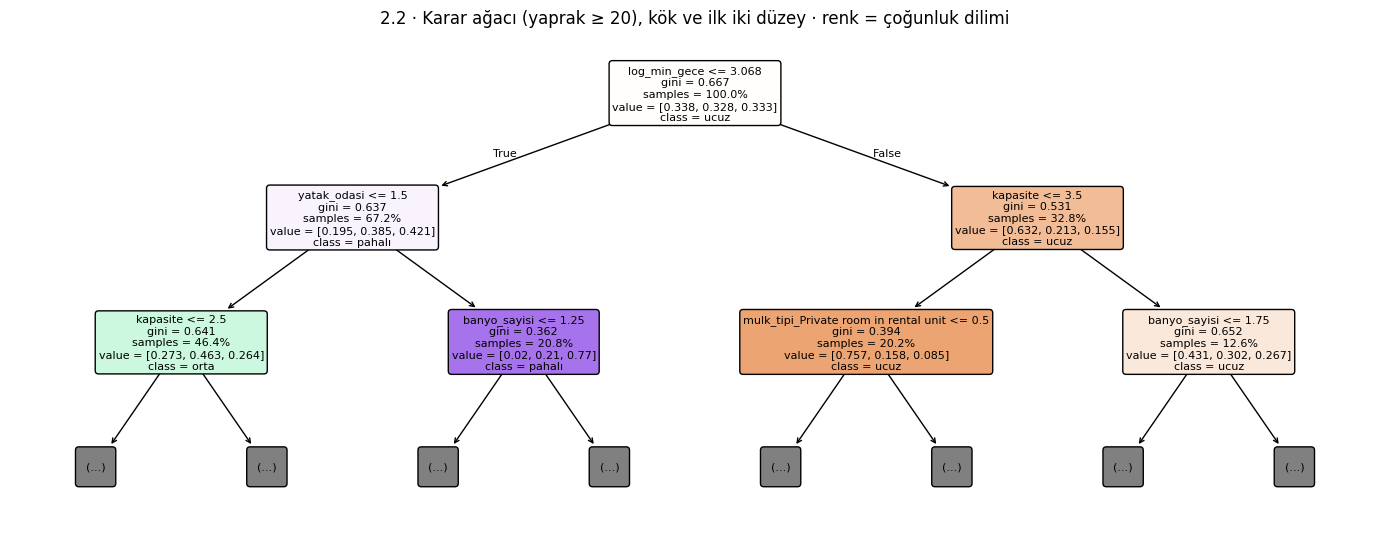

Grafik: her kutuda soru, Gini safsızlığı, ilan oranı ve dilim oranları (ucuz, orta, pahalı). log_min_gece eşiği log ölçekte; okunur karşılığı yukarıdaki tabloda.


In [23]:
# =====================================================================
# 2.2 Karar ağacının yorumu: kök ve ilk iki düzey
# Önkoşul: ortak hat hücreleri (X, y, veri, CV_GRUP, SAYISAL, KATEGORIK, YUKSEK_KARD, NADIR_ESIK, SEED, SINIFLAR)
# =====================================================================
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

# 1) Ağaç için ÖLÇEKSİZ ön işleme. Ağaç "kapasite > 3,5?" gibi eşik soruları sorar; ölçekleme soruların
#    cevabını değiştirmez ama eşikleri okunamaz yapar (ör. "kapasite ≤ 0,37"). Doldurma ve kodlama aynı.
def agac_on_isleme():
    return ColumnTransformer([
        ("sayisal", SimpleImputer(strategy="median", add_indicator=True), SAYISAL),
        ("kategorik", OneHotEncoder(handle_unknown="ignore"), KATEGORIK),
        ("yuksek_kard", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=NADIR_ESIK), [YUKSEK_KARD]),
    ], verbose_feature_names_out=False)          # sütun adları önek almasın: "kapasite", "oda_tipi_Private room"

def agac_hatti():
    # 2.1'deki "yaprak ≥ 20" ağacı: her yaprakta en az 20 ilan
    return Pipeline([("on", agac_on_isleme()),
                     ("model", DecisionTreeClassifier(min_samples_leaf=20, random_state=SEED))])

# Kontrol: ölçeksiz hat 2.1'deki ölçekli ağaçla aynı skoru vermeli (ağaç ölçekten etkilenmez)
_ = degerlendir(agac_hatti(), X, ad="Karar ağacı · yaprak ≥ 20 · ölçeksiz hat (2.1 ile aynı olmalı)")

# 2) Yorum için bütün veride bir ağaç. Bu ağaç YALNIZ yapıyı okumak için; skor raporunda kullanılmıyor.
agac = agac_hatti().fit(X, y)
ad = list(agac.named_steps["on"].get_feature_names_out())
t = agac.named_steps["model"].tree_
print(f"\nBütün veride ağaç: derinlik {agac.named_steps['model'].get_depth()}, yaprak {agac.named_steps['model'].get_n_leaves()}")
print(export_text(agac.named_steps["model"], feature_names=ad, class_names=SINIFLAR, max_depth=2, decimals=2))

# 3) Eşikleri okunur hâle getirme: log1p ile dönüştürülmüş sütunlarda eşiği geri çevir (expm1)
def okunur_kural(sutun, esik, sol):
    if sutun.startswith("log_"):
        ham = np.expm1(esik)
        birim = {"log_min_gece": "gece", "log_ev_sahibi_ilan": "ilan", "log_aciklama_uzunlugu": "karakter"}.get(sutun, "")
        return f"{sutun[4:]} {'≤' if sol else '>'} {ham:.1f} {birim}".strip()
    if sutun.startswith("missingindicator_"):
        return f"{sutun[17:]} {'dolu' if sol else 'EKSİK'}"
    if sutun not in SAYISAL:                       # bire-bir kodlanmış kategori (0/1), eşik hep 0,5
        return f"{sutun} {'DEĞİL' if sol else 'EVET'}"
    return f"{sutun} {'≤' if sol else '>'} {esik:.2f}"

def soru(dugum):                                   # düğümün sorduğu soru, okunur biçimde
    return okunur_kural(ad[t.feature[dugum]], t.threshold[dugum], True)

# 4) Kök ve ilk iki düzeydeki her düğüm: kaç ilan, dilim dağılımı, çoğunluk
satirlar = []
def gez(dugum, derinlik, yol):
    oran = t.value[dugum][0] / t.value[dugum][0].sum()          # düğümdeki sınıf oranları
    satirlar.append({"düzey": derinlik, "kural": " ∧ ".join(yol) if yol else "(kök: bütün ilanlar)",
                     "ilan": int(t.n_node_samples[dugum]),
                     **{f"% {s}": round(100 * o, 1) for s, o in zip(SINIFLAR, oran)},
                     "çoğunluk": SINIFLAR[int(np.argmax(oran))],
                     "sonraki soru": soru(dugum) if derinlik < 2 else ""})
    if derinlik < 2:
        s, e = ad[t.feature[dugum]], t.threshold[dugum]
        gez(t.children_left[dugum], derinlik + 1, yol + [okunur_kural(s, e, True)])
        gez(t.children_right[dugum], derinlik + 1, yol + [okunur_kural(s, e, False)])
gez(0, 0, [])
dugum_tablosu = pd.DataFrame(satirlar)
display(dugum_tablosu)

# 5) Kararlılık: aynı soruları her eğitim katında da soruyor mu? (25 bölmenin eğitim katları)
kararlilik = []
for tr, _te in CV_GRUP:
    m = agac_hatti().fit(X.iloc[tr], y[tr])
    tt, aa = m.named_steps["model"].tree_, m.named_steps["on"].get_feature_names_out()
    L, R = tt.children_left[0], tt.children_right[0]
    kararlilik.append({"kök": aa[tt.feature[0]], "kök eşiği": tt.threshold[0],
                       "sol çocuk": aa[tt.feature[L]], "sağ çocuk": aa[tt.feature[R]]})
kararlilik = pd.DataFrame(kararlilik)
print("Kök ve birinci düzey, 25 eğitim katında (kaç kez seçildi):")
for k in ["kök", "sol çocuk", "sağ çocuk"]:
    print(f"  {k:<10s}", kararlilik[k].value_counts().to_dict())
kok = kararlilik.loc[kararlilik["kök"] == "log_min_gece", "kök eşiği"]
if len(kok):
    print(f"  Kök eşiği (en az konaklama, gece): {np.expm1(kok.min()):.1f} – {np.expm1(kok.max()):.1f}")

# 6) Alan bilgisi için bağlam: kök sorusunun iki tarafında fiyat
uzun = veri["minimum_nights"] > np.expm1(t.threshold[0])
print(f"\nKökün sağı (en az konaklama > {np.expm1(t.threshold[0]):.0f} gece): {uzun.mean():.1%} ilan; "
      f"medyan gecelik fiyat {veri.loc[uzun, 'fiyat'].median():,.0f} TL (sol: {veri.loc[~uzun, 'fiyat'].median():,.0f} TL)")
print("En az konaklamanın en sık değerleri (sağ taraf):", veri.loc[uzun, "minimum_nights"].value_counts().head(4).to_dict())
bosluk = veri["minimum_nights"].between(15, 99)
print(f"Kök eşiklerinin düştüğü 15–99 gece aralığındaki ilan: {bosluk.sum()} ({bosluk.mean():.1%}) → "
      "eşik bu boşlukta nereye konsa da ayrım pratikte aynı: '≤ 14 gece' ile '≥ 100 gece'")

# 7) Görsel: ilk iki düzey
fig, ax = plt.subplots(figsize=(14, 5.5))
plot_tree(agac.named_steps["model"], max_depth=2, feature_names=ad, class_names=SINIFLAR,
          filled=True, impurity=True, proportion=True, rounded=True, fontsize=8, ax=ax)
ax.set_title("2.2 · Karar ağacı (yaprak ≥ 20), kök ve ilk iki düzey · renk = çoğunluk dilimi")
plt.tight_layout(); plt.show()
print("Grafik: her kutuda soru, Gini safsızlığı, ilan oranı ve dilim oranları (ucuz, orta, pahalı). "
      "log_min_gece eşiği log ölçekte; okunur karşılığı yukarıdaki tabloda.")


**Yorum**

Ağacı okuyabilmek için ölçekleme yapmadan kurduk; skor değişmedi.

Ağacın ilk sorusu evin büyüklüğü ya da ilçesi değil, "en az konaklama 20 geceden fazla mı?" oldu. Bu soru 25 denemenin hepsinde en üstte çıktı. Uzun dönem tarafındaki ilanlar neredeyse tamamen 100 gecelik teklifler ve gecelik fiyatları çok daha düşük (medyan 2.096 TL, kısa dönemde 4.483 TL). Yani modelin en güçlü ipucu, teklifin aylık kiralama olup olmaması.

İkinci sırada evin büyüklüğü geliyor: kısa dönem ilanlarda 2 ve daha fazla yatak odalı evlerin %77'si pahalı. Uzun dönem tarafında ise büyük evler bile çoğunlukla ucuz.

Ağacın üst kısmı her denemede aynı, ama alt dallar değişiyor. Bu yüzden ağacın yalnızca ilk birkaç sorusunu yorumlamak anlamlı.

**Neyi söyleyemeyiz:** Bu kurallar neden–sonuç ilişkisi göstermiyor; "en az konaklamayı artırırsan fiyat düşer" demiyor, yalnızca grupların farklı olduğunu gösteriyor. 100 gecelik ilanların gerçekte uzun dönem kiralanıp kiralanmadığını veriyle doğrulayamıyoruz. Ayrıca bu tek bir ağacın yorumu; en iyi modelimiz olan ormanın hangi özelliklere dayandığını göstermiyor.

### 2.3 Optimist yanlılık
`GridSearchCV.best_score_` ile iç içe ÇD skorunun karşılaştırması.

A) GridSearchCV (gruplu 5 kat, 24 aday) best_score_ = 0.614 · seçilen: {'model__max_depth': 8, 'model__min_samples_leaf': 5}  (54 sn)
   dış kat 1: iç en iyi 0.612 → dış test 0.620 · seçilen {'model__max_depth': 6, 'model__min_samples_leaf': 50}  (47 sn)
   dış kat 2: iç en iyi 0.604 → dış test 0.632 · seçilen {'model__max_depth': 6, 'model__min_samples_leaf': 50}  (45 sn)
   dış kat 3: iç en iyi 0.622 → dış test 0.588 · seçilen {'model__max_depth': 8, 'model__min_samples_leaf': 5}  (47 sn)
   dış kat 4: iç en iyi 0.615 → dış test 0.601 · seçilen {'model__max_depth': 6, 'model__min_samples_leaf': 50}  (47 sn)
   dış kat 5: iç en iyi 0.609 → dış test 0.620 · seçilen {'model__max_depth': 8, 'model__min_samples_leaf': 20}  (56 sn)
B) İç içe ÇD skoru = 0.612 ± 0.016  (iç ÇD'deki en iyi skorların ortalaması 0.612; her katta şişme +0.000)
Satıra göre seçilen ağaç {'model__max_depth': 12, 'model__min_samples_leaf': 1} · gruplu ÇD f1_macro = 0.600 ± 0.013
Gruplu seçilen ağaç {'model__max_depth

,rapor edilen,gerçekçi (iç içe / gruplu),şişme
kaynak,,,
"Ayar + rapor aynı ÇD'de (best_score_, gruplu iç ÇD)",0.614,0.612,0.002
Ayar satıra göre ÇD'de (best_score_),0.666,0.600,0.066
Rastgele orman OOB skoru (satıra göre),0.742,0.658,0.084


Satıra göre seçilen ağaç, gruplu seçilen ağaca göre gruplu ÇD'de -0.014 (daha kötü olduğu bölme: 24/25)


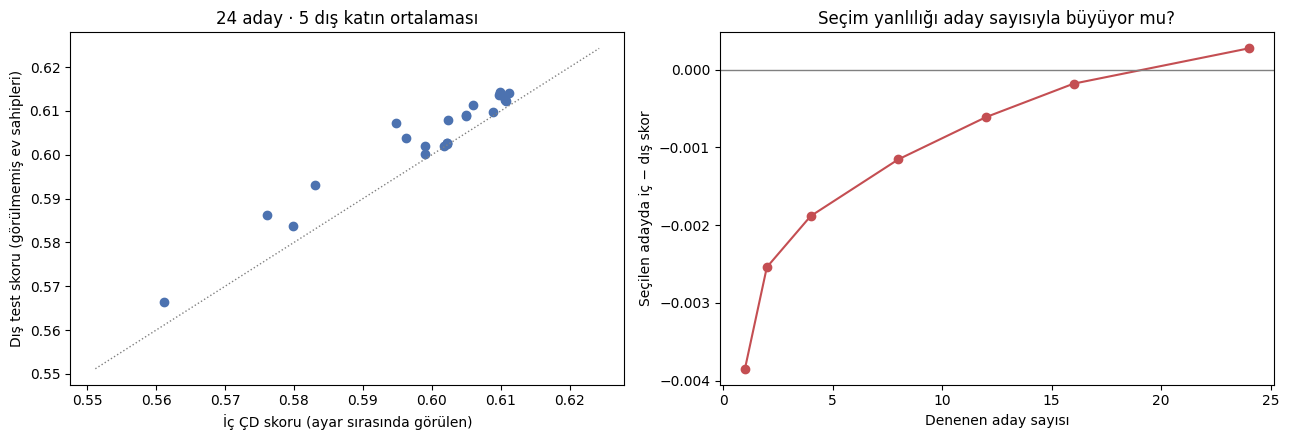

Grafik: solda noktalı çizgi iç = dış; altında kalan aday ayar sırasında olduğundan iyi görünmüş. Sağda her aday sayısı için 300 rastgele alt küme × 5 dış kat ortalaması.


aday sayısı,1,2,4,8,12,16,24
şişme (iç − dış),-0.0038,-0.0025,-0.0019,-0.0012,-0.0006,-0.0002,0.0003


In [24]:
from sklearn.model_selection import GridSearchCV
# =====================================================================
# 2.3 Optimist yanlılık: GridSearchCV.best_score_ ile iç içe ÇD skorunun karşılaştırması
# Önkoşul: ortak hat + 2.2 (agac_on_isleme). Ayarlanan model: karar ağacı (hızlı ve ayara duyarlı).
# İç ÇD de EV SAHİBİNE GÖRE gruplu: ayar aşamasında da aynı ev sahibi hem eğitimde hem doğrulamada olmamalı.
# =====================================================================
import time
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

IZGARA = {"model__max_depth": [4, 6, 8, 12, 16, None],
          "model__min_samples_leaf": [1, 5, 20, 50]}              # 6 × 4 = 24 aday
ADAYLAR = [dict(zip(IZGARA, d)) for d in
           [(a, b) for a in IZGARA["model__max_depth"] for b in IZGARA["model__min_samples_leaf"]]]

def agac_ayar_hatti():
    return Pipeline([("on", agac_on_isleme()), ("model", DecisionTreeClassifier(random_state=SEED))])

def ic_cv(tohum=SEED):
    return StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=tohum)

# ---- A) Yanlış ama yaygın: bütün veride ayar yap, best_score_'u rapor et
t0 = time.time()
gs = GridSearchCV(agac_ayar_hatti(), IZGARA, cv=ic_cv(), scoring="f1_macro", n_jobs=-1)
gs.fit(X, y, groups=gruplar)
print(f"A) GridSearchCV (gruplu 5 kat, 24 aday) best_score_ = {gs.best_score_:.3f} · seçilen: {gs.best_params_}  ({time.time()-t0:.0f} sn)")

# ---- B) Doğru: iç içe ÇD. Dış kat yalnız SKOR için; ayar her dış eğitim katının İÇİNDE yapılır.
#      Dış bölme = CV_GRUP'un ilk turu (5 kat, her ilan bir kez test edilir).
#      Analiz için her dış katta 24 adayın hepsinin dış test skorunu da saklıyoruz (C bölümü).
ic_skor, dis_skor, secilen, ic_en_iyi, dis_secilen = [], [], [], [], []
for k, (tr, te) in enumerate(CV_GRUP[:5]):
    t0 = time.time()
    g = GridSearchCV(agac_ayar_hatti(), IZGARA, cv=ic_cv(SEED + 100 + k), scoring="f1_macro", n_jobs=-1)
    g.fit(X.iloc[tr], y[tr], groups=gruplar[tr])                  # ayar: yalnız dış eğitim katı
    ic_skor.append(g.cv_results_["mean_test_score"])               # 24 adayın iç ÇD skoru
    # 24 adayın her birini dış eğitim katında eğitip dış testte ölç (yalnız analiz için; seçimde kullanılmıyor)
    dis_skor.append(np.array([f1_score(y[te], agac_ayar_hatti().set_params(**p).fit(X.iloc[tr], y[tr]).predict(X.iloc[te]),
                                       average="macro") for p in ADAYLAR]))
    j = int(np.argmax(ic_skor[-1]))
    secilen.append(ADAYLAR[j]); ic_en_iyi.append(ic_skor[-1][j]); dis_secilen.append(dis_skor[-1][j])
    print(f"   dış kat {k+1}: iç en iyi {ic_en_iyi[-1]:.3f} → dış test {dis_secilen[-1]:.3f} · seçilen {secilen[-1]}  ({time.time()-t0:.0f} sn)")
ic_skor, dis_skor = np.array(ic_skor), np.array(dis_skor)
ic_en_iyi, dis_secilen = np.array(ic_en_iyi), np.array(dis_secilen)
print(f"B) İç içe ÇD skoru = {dis_secilen.mean():.3f} ± {dis_secilen.std():.3f}  "
      f"(iç ÇD'deki en iyi skorların ortalaması {ic_en_iyi.mean():.3f}; her katta şişme {np.mean(ic_en_iyi - dis_secilen):+.3f})")

# ---- C) Şişme aday sayısıyla büyür mü? Izgaradan rastgele k aday seç; iç ÇD'ye göre en iyiyi al;
#      "iç skor − aynı adayın dış test skoru" farkını k'ya göre ortala (her k için 300 rastgele alt küme × 5 dış kat).
rng = np.random.default_rng(SEED)
egri = []
for kk in [1, 2, 4, 8, 12, 16, 24]:
    farklar = []
    for _ in range(300 if kk < 24 else 1):
        alt = rng.choice(len(ADAYLAR), kk, replace=False)
        for f in range(5):
            j = alt[np.argmax(ic_skor[f, alt])]
            farklar.append(ic_skor[f, j] - dis_skor[f, j])
    egri.append({"aday sayısı": kk, "şişme (iç − dış)": np.mean(farklar)})
egri = pd.DataFrame(egri)

# ---- D) Bölme yanlışsa ayar da yanlış: iç ÇD SATIRA göre (ev sahibini bilmeden) yapılırsa
from sklearn.model_selection import StratifiedKFold
gs_satir = GridSearchCV(agac_ayar_hatti(), IZGARA, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                        scoring="f1_macro", n_jobs=-1).fit(X, y)
gercek_satir = degerlendir(agac_ayar_hatti().set_params(**gs_satir.best_params_), X,
                           ad=f"Satıra göre seçilen ağaç {gs_satir.best_params_} · gruplu ÇD")
gercek_grup = degerlendir(agac_ayar_hatti().set_params(**gs.best_params_), X,
                          ad=f"Gruplu seçilen ağaç {gs.best_params_} · gruplu ÇD")

# ---- E) Rastgele ormanın OOB skoru: satıra göre "iç" tahmin (yerine koyarak örneklemede dışarıda kalan ilanlar)
oob, test_rf = [], []
for tr, te in CV_GRUP[:5]:
    rf = Pipeline([("on", on_isleme()), ("model", RandomForestClassifier(n_estimators=100, min_samples_leaf=2, oob_score=True,
                                                                        n_jobs=-1, random_state=SEED))]).fit(X.iloc[tr], y[tr])
    oob.append(f1_score(y[tr], rf.named_steps["model"].oob_decision_function_.argmax(1), average="macro"))
    test_rf.append(f1_score(y[te], rf.predict(X.iloc[te]), average="macro"))
oob, test_rf = np.array(oob), np.array(test_rf)

# ---- Özet tablo: "rapor edilen" skor ile "gerçekçi" skor
ozet = pd.DataFrame([
    {"kaynak": "Ayar + rapor aynı ÇD'de (best_score_, gruplu iç ÇD)", "rapor edilen": gs.best_score_,
     "gerçekçi (iç içe / gruplu)": dis_secilen.mean()},
    {"kaynak": "Ayar satıra göre ÇD'de (best_score_)", "rapor edilen": gs_satir.best_score_,
     "gerçekçi (iç içe / gruplu)": gercek_satir["f1_macro_ort"]},
    {"kaynak": "Rastgele orman OOB skoru (satıra göre)", "rapor edilen": oob.mean(),
     "gerçekçi (iç içe / gruplu)": test_rf.mean()},
]).set_index("kaynak")
ozet["şişme"] = ozet["rapor edilen"] - ozet["gerçekçi (iç içe / gruplu)"]
display(ozet.round(3))
print(f"Satıra göre seçilen ağaç, gruplu seçilen ağaca göre gruplu ÇD'de {gercek_satir['f1_macro_ort'] - gercek_grup['f1_macro_ort']:+.3f} "
      f"(daha kötü olduğu bölme: {int((gercek_satir['_skorlar'] < gercek_grup['_skorlar']).sum())}/25)")

# ---- Grafik: (sol) 24 adayın iç ve dış skoru · (sağ) şişme ~ aday sayısı
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(ic_skor.mean(0), dis_skor.mean(0), color="#4C72B0")
lim = [min(ic_skor.mean(0).min(), dis_skor.mean(0).min()) - 0.01, max(ic_skor.mean(0).max(), dis_skor.mean(0).max()) + 0.01]
ax[0].plot(lim, lim, color="grey", ls=":", lw=1)
ax[0].set(xlabel="İç ÇD skoru (ayar sırasında görülen)", ylabel="Dış test skoru (görülmemiş ev sahipleri)",
          title="24 aday · 5 dış katın ortalaması")
ax[1].plot(egri["aday sayısı"], egri["şişme (iç − dış)"], marker="o", color="#C44E52")
ax[1].axhline(0, color="grey", lw=1)
ax[1].set(xlabel="Denenen aday sayısı", ylabel="Seçilen adayda iç − dış skor", title="Seçim yanlılığı aday sayısıyla büyüyor mu?")
plt.tight_layout(); plt.show()
print("Grafik: solda noktalı çizgi iç = dış; altında kalan aday ayar sırasında olduğundan iyi görünmüş. "
      "Sağda her aday sayısı için 300 rastgele alt küme × 5 dış kat ortalaması.")
display(egri.round(4).set_index("aday sayısı").T)


**Yorum**

Bir modelin ayarlarını birçok seçenek arasından seçip aynı skoru rapor edersek sonuç olduğundan iyi görünebilir. Bunu karar ağacında 24 farklı ayarla test ettik.

Bu kurulumda fark çok küçük çıktı: ayar seçiminin skoru 0,614, iç içe çapraz doğrulamayla ölçülen gerçek skor 0,612.

Asıl büyük şişmeyi yanlış bölmede gördük. Ayarı ev sahibine bakmadan, satıra göre yapınca skor 0,666 görünüyor; ama seçilen ağacın gerçek skoru 0,600. Üstelik daha kötü bir ağaç seçiliyor. Rastgele ormanın kendi iç skoru (OOB) da aynı nedenle iyimser: 0,742'ye karşı gerçek 0,658.

Buradan öğrendiğimiz: veriyi doğru bölmek, ayar seçiminden çok daha önemli.

**Neyi söyleyemeyiz:** Sonuç küçük bir ayar listesi (24 seçenek) ve tek bir model için geçerli; daha çok ayarı olan modellerde şişme daha büyük olabilir. Dış döngüyü bir kez çalıştırdık, bu yüzden standart sapma kaba bir tahmin.

### 2.4 İstatistiksel test
En iyi iki modelin farkı: McNemar ya da 5×2 ÇD t-testi. "Fark anlamlı çıkmadı" tam puanlık bir sonuçtur.

5×2 ÇD tekrar 1/5 tamam
5×2 ÇD tekrar 2/5 tamam
5×2 ÇD tekrar 3/5 tamam
5×2 ÇD tekrar 4/5 tamam
5×2 ÇD tekrar 5/5 tamam


,fark (25 bölme),fark (5×2),"p · saf t (25, YANLIŞ)",p · düzeltilmiş t (25),p · 5×2 t (Dietterich),p · 5×2 F (Alpaydın),McNemar: yalnız A doğru,McNemar: yalnız B doğru,p · McNemar
karşılaştırma (A − B),,,,,,,,,
Gradyan artırma (HistGB) − Rastgele orman · 300 ağaç,0.0033,0.0028,0.0443,0.4383,0.4523,0.6550,672,580,0.0101
Rastgele orman · 300 ağaç − Lojistik regresyon (1.6),0.0350,0.0327,0.0000,0.0000,0.0080,0.0007,937,693,0.0000
k-NN · k = 15 (ölçekli) − Karar ağacı · yaprak ≥ 20,0.0028,0.0012,0.1727,0.6065,0.2747,0.2495,1205,1232,0.5984


McNemar ayırması: eğitim 16,097 · test 8,456 ilan (ev sahibi kesişimi yok: True). McNemar doğruluk üzerinden çalışır (doğru/yanlış), makro F1 değil.
Not: 3 çift × 5 test = çoklu karşılaştırma; tek bir p < 0,05 tek başına kanıt sayılmamalı. Karar için önceden seçilen test: gruplu 5×2 ÇD t (Dietterich), destek: 5×2 F.


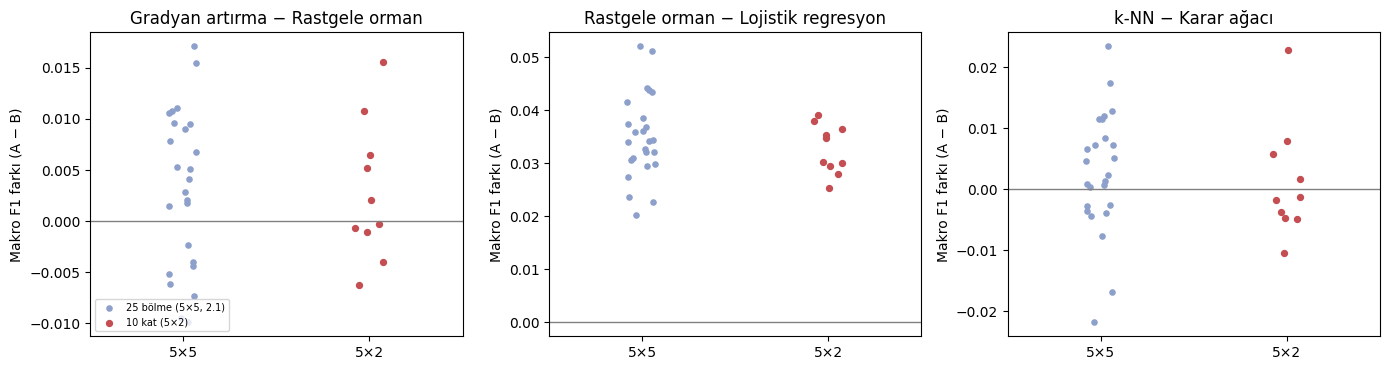

Grafik: her nokta bir katta A ile B'nin makro F1 farkı; sıfır çizgisinin iki yanına dağılım farkın tutarlılığını gösterir.


In [25]:
from statsmodels.stats.contingency_tables import mcnemar
# =====================================================================
# 2.4 İstatistiksel test: iki modelin farkı tesadüf olabilir mi?
# Önkoşul: ortak hat + 2.1 (MODELLER_21, skorlar_21).
# Dietterich (1998): aynı veriden üretilmiş bölmelerin skorları bağımsız değildir; 25 skora sıradan
# t-testi uygulamak "fark yokken var" deme (I. tür hata) oranını şişirir. Önerileri: 5×2 ÇD t-testi
# (model 10 kez eğitilebiliyorsa) ya da McNemar (yalnız bir kez eğitilebiliyorsa).
# Bizde ek koşul: bütün bölmeler EV SAHİBİNE GÖRE gruplu (1.5).
# =====================================================================
from scipy import stats
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score

KARSILASTIRMALAR = [   # (A, B): en iyi iki model + iki kontrol çifti
    ("Gradyan artırma (HistGB)", "Rastgele orman · 300 ağaç"),     # en iyi iki model (2.1'de fark +0,005)
    ("Rastgele orman · 300 ağaç", "Lojistik regresyon (1.6)"),     # açık fark beklenen çift (+0,035)
    ("k-NN · k = 15 (ölçekli)", "Karar ağacı · yaprak ≥ 20"),      # farklı aileler, skorlar neredeyse aynı
]
MODELLER_24 = sorted({m for cift in KARSILASTIRMALAR for m in cift})

# ---- 1) Gruplu 5×2 ÇD: 5 tekrar × 2 kat; her katta bütün modeller AYNI bölmede eğitilir (eşleştirilmiş)
BOLME_5x2 = []
for r in range(5):
    sgkf = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=SEED + r)
    BOLME_5x2.append(list(sgkf.split(np.zeros(len(y)), y, gruplar)))
assert all(len(set(gruplar[a]) & set(gruplar[b])) == 0 for (a, b), _ in BOLME_5x2)

skor_5x2 = {m: np.zeros((5, 2)) for m in MODELLER_24}
for r, katlar in enumerate(BOLME_5x2):
    for j, (tr, te) in enumerate(katlar):
        for m in MODELLER_24:
            tahmin = clone(MODELLER_21[m]).fit(X.iloc[tr], y[tr]).predict(X.iloc[te])
            skor_5x2[m][r, j] = f1_score(y[te], tahmin, average="macro")
    print(f"5×2 ÇD tekrar {r + 1}/5 tamam")

def t_5x2(p):                                    # Dietterich (1998), serbestlik derecesi 5
    s2 = ((p - p.mean(1, keepdims=True)) ** 2).sum(1)
    t = p[0, 0] / np.sqrt(s2.mean())
    return t, 2 * stats.t.sf(abs(t), df=5)

def f_5x2(p):                                    # Alpaydın (1999): 10 farkın hepsini kullanan birleşik F testi
    s2 = ((p - p.mean(1, keepdims=True)) ** 2).sum(1)
    f = (p ** 2).sum() / (2 * s2.sum())
    return f, stats.f.sf(f, 10, 5)

def t_saf(d):                                    # YANLIŞ: 25 skoru bağımsız sayan eşli t-testi (karşılaştırma için)
    t = d.mean() / (d.std(ddof=1) / np.sqrt(len(d)))
    return t, 2 * stats.t.sf(abs(t), df=len(d) - 1)

def t_duzeltilmis(d, test_orani=1 / 4):          # Nadeau & Bengio (2003): örtüşen eğitim kümeleri için düzeltme
    t = d.mean() / np.sqrt((1 / len(d) + test_orani) * d.var(ddof=1))
    return t, 2 * stats.t.sf(abs(t), df=len(d) - 1)

# ---- 2) McNemar: tek bir gruplu ayırma (eğitim 2/3, test 1/3), modeller bir kez eğitilir
tr_h, te_h = next(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED).split(np.zeros(len(y)), y, gruplar))
dogru_h = {m: clone(MODELLER_21[m]).fit(X.iloc[tr_h], y[tr_h]).predict(X.iloc[te_h]) == y[te_h] for m in MODELLER_24}

# ---- 3) Bütün testler, her çift için
satirlar = []
for a_, b_ in KARSILASTIRMALAR:
    p = skor_5x2[a_] - skor_5x2[b_]                     # 5 × 2 fark matrisi
    d25 = skorlar_21[a_] - skorlar_21[b_]               # 2.1'deki 25 gruplu bölmenin farkları
    ia, ib = dogru_h[a_], dogru_h[b_]
    tablo2x2 = [[int(( ia &  ib).sum()), int(( ia & ~ib).sum())],
                [int((~ia &  ib).sum()), int((~ia & ~ib).sum())]]
    mc = mcnemar(tablo2x2, exact=False, correction=True)
    satirlar.append({
        "karşılaştırma (A − B)": f"{a_}  −  {b_}",
        "fark (25 bölme)": d25.mean(), "fark (5×2)": p.mean(),
        "p · saf t (25, YANLIŞ)": t_saf(d25)[1],
        "p · düzeltilmiş t (25)": t_duzeltilmis(d25)[1],
        "p · 5×2 t (Dietterich)": t_5x2(p)[1],
        "p · 5×2 F (Alpaydın)": f_5x2(p)[1],
        "McNemar: yalnız A doğru": tablo2x2[0][1], "McNemar: yalnız B doğru": tablo2x2[1][0],
        "p · McNemar": mc.pvalue,
    })
test_tablosu = pd.DataFrame(satirlar).set_index("karşılaştırma (A − B)")
display(test_tablosu.round(4))
print(f"McNemar ayırması: eğitim {len(tr_h):,} · test {len(te_h):,} ilan (ev sahibi kesişimi yok: "
      f"{len(set(gruplar[tr_h]) & set(gruplar[te_h])) == 0}). McNemar doğruluk üzerinden çalışır (doğru/yanlış), makro F1 değil.")
print("Not: 3 çift × 5 test = çoklu karşılaştırma; tek bir p < 0,05 tek başına kanıt sayılmamalı. "
      "Karar için önceden seçilen test: gruplu 5×2 ÇD t (Dietterich), destek: 5×2 F.")

# ---- 4) Grafik: her çiftin 10 farkı (5×2) ve 25 farkı (2.1)
fig, ax = plt.subplots(1, len(KARSILASTIRMALAR), figsize=(14, 3.8), sharey=False)
for a, (a_, b_) in zip(ax, KARSILASTIRMALAR):
    a.scatter(np.zeros(25) + np.random.default_rng(0).uniform(-0.08, 0.08, 25), skorlar_21[a_] - skorlar_21[b_],
              s=14, color="#8da0cb", label="25 bölme (5×5, 2.1)")
    a.scatter(np.ones(10) + np.random.default_rng(1).uniform(-0.08, 0.08, 10), (skor_5x2[a_] - skor_5x2[b_]).ravel(),
              s=18, color="#C44E52", label="10 kat (5×2)")
    a.axhline(0, color="grey", lw=1)
    a.set(xticks=[0, 1], xticklabels=["5×5", "5×2"], xlim=(-0.5, 1.5), ylabel="Makro F1 farkı (A − B)",
          title=f"{a_.split(' ·')[0].split(' (')[0]} − {b_.split(' ·')[0].split(' (')[0]}")
ax[0].legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()
print("Grafik: her nokta bir katta A ile B'nin makro F1 farkı; sıfır çizgisinin iki yanına dağılım farkın tutarlılığını gösterir.")


In [26]:
# =====================================================================
# 2.4 (devam) Sonuç ne kadar sağlam? Önkoşul: önceki hücre (skor_5x2, dogru_h, tr_h, te_h, KARSILASTIRMALAR)
# (a) Dietterich'in 5×2 t testi payda 10 farkın hepsini, payda ise YALNIZ ilk farkı p_1^(1) kullanır.
#     Hangi tekrarın "ilk" sayılacağı keyfidir: payı 10 farkın her biriyle değiştirip p'nin oynamasına bakıyoruz.
# (b) McNemar ilanları bağımsız sayar; aynı ev sahibinin ilanları test kümesinde birlikte doğru/yanlış olur.
#     Ev sahibine göre bootstrap (ev sahiplerini yerine koyarak çek) farkın gerçek belirsizliğini verir.
# (c) Üç çift test edildi: ana test için Holm düzeltmesi.
# DÜRÜSTLÜK NOTU: Bu kontroller ilk sonuçlar görüldükten sonra eklendi: ilk denemede (scikit-learn 1.9.1)
# 5×2 t (p = 0,038) ile 5×2 F (p = 0,14) çelişmişti. Sonradan yapılmış (post hoc) sağlamlık analizidir.
# Bu defterin sürümünde (1.6.1) bölmeler farklı; çelişki yok, sonuç aynı: fark anlamlı değil.
# =====================================================================
rng = np.random.default_rng(SEED)
grup_te = gruplar[te_h]
ev_sahipleri, ters = np.unique(grup_te, return_inverse=True)

duyarlilik = []
for a_, b_ in KARSILASTIRMALAR:
    p = skor_5x2[a_] - skor_5x2[b_]
    s2 = ((p - p.mean(1, keepdims=True)) ** 2).sum(1)
    p_degerleri = np.array([2 * stats.t.sf(abs(pay / np.sqrt(s2.mean())), df=5) for pay in p.ravel()])
    # ev sahibine göre bootstrap: her ev sahibinin ilanlarındaki "A doğru − B doğru" toplamı ve ilan sayısı
    fark_ilan = dogru_h[a_].astype(int) - dogru_h[b_].astype(int)
    toplam = np.bincount(ters, weights=fark_ilan); adet = np.bincount(ters)
    boot = []
    for _ in range(2000):
        sec = rng.integers(0, len(ev_sahipleri), len(ev_sahipleri))
        boot.append(toplam[sec].sum() / adet[sec].sum())
    boot = np.array(boot)
    gozlenen = fark_ilan.mean()
    duyarlilik.append({
        "karşılaştırma (A − B)": f"{a_}  −  {b_}",
        "5×2 t · p (Dietterich, ilk fark)": t_5x2(p)[1],
        "5×2 t · p en küçük": p_degerleri.min(), "5×2 t · p en büyük": p_degerleri.max(),
        "5×2 t · 10 seçimden p<0,05": int((p_degerleri < 0.05).sum()),
        "doğruluk farkı (ayırma)": gozlenen,
        "ev sahibi bootstrap %95 GA alt": np.percentile(boot, 2.5), "üst": np.percentile(boot, 97.5),
        "bootstrap p (iki yönlü)": min(1.0, 2 * min((boot <= 0).mean(), (boot >= 0).mean())),
        "McNemar p (ilan bağımsız)": test_tablosu.loc[f"{a_}  −  {b_}", "p · McNemar"],
    })
duyarlilik = pd.DataFrame(duyarlilik).set_index("karşılaştırma (A − B)")

# (c) Holm: ana test (5×2 t) için üç çiftin p değerleri birlikte düzeltilir
p_ana = duyarlilik["5×2 t · p (Dietterich, ilk fark)"].to_numpy()
sira = np.argsort(p_ana); holm = np.empty(3)
holm[sira] = np.maximum.accumulate(np.minimum(1, (3 - np.arange(3)) * p_ana[sira]))
duyarlilik["5×2 t · p (Holm, 3 çift)"] = holm
display(duyarlilik.round(4))
print(f"Ev sahibi bootstrap: test kümesinde {len(ev_sahipleri):,} ev sahibi, {len(te_h):,} ilan; 2.000 tekrar.")

# ---- Karar özeti: bütün kanıtlar yan yana
ozet_24 = pd.DataFrame({
    "fark (makro F1, 25 bölme)": test_tablosu["fark (25 bölme)"],
    "düzeltilmiş t (25)": test_tablosu["p · düzeltilmiş t (25)"],
    "5×2 F": test_tablosu["p · 5×2 F (Alpaydın)"],
    "5×2 t (Holm)": duyarlilik["5×2 t · p (Holm, 3 çift)"],
    "ev sahibi bootstrap": duyarlilik["bootstrap p (iki yönlü)"],
})
ozet_24["sonuç"] = np.where((ozet_24.iloc[:, 1:] < 0.05).all(axis=1), "fark anlamlı (bütün sağlam testler)",
                     np.where((ozet_24.iloc[:, 1:] < 0.05).any(axis=1), "kanıt zayıf / tutarsız", "fark anlamlı değil"))
display(ozet_24.round(4))


,"5×2 t · p (Dietterich, ilk fark)",5×2 t · p en küçük,5×2 t · p en büyük,"5×2 t · 10 seçimden p<0,05",doğruluk farkı (ayırma),ev sahibi bootstrap %95 GA alt,üst,bootstrap p (iki yönlü),McNemar p (ilan bağımsız),"5×2 t · p (Holm, 3 çift)"
karşılaştırma (A − B),,,,,,,,,,
Gradyan artırma (HistGB) − Rastgele orman · 300 ağaç,0.4523,0.1064,0.9738,0,0.0109,-0.0016,0.0237,0.076,0.0101,0.5495
Rastgele orman · 300 ağaç − Lojistik regresyon (1.6),0.0080,0.0012,0.0080,10,0.0289,0.0147,0.0430,0.000,0.0000,0.0239
k-NN · k = 15 (ölçekli) − Karar ağacı · yaprak ≥ 20,0.2747,0.0168,0.8625,1,-0.0032,-0.0194,0.0134,0.705,0.5984,0.5495


Ev sahibi bootstrap: test kümesinde 2,894 ev sahibi, 8,456 ilan; 2.000 tekrar.


,"fark (makro F1, 25 bölme)",düzeltilmiş t (25),5×2 F,5×2 t (Holm),ev sahibi bootstrap,sonuç
karşılaştırma (A − B),,,,,,
Gradyan artırma (HistGB) − Rastgele orman · 300 ağaç,0.0033,0.4383,0.6550,0.5495,0.076,fark anlamlı değil
Rastgele orman · 300 ağaç − Lojistik regresyon (1.6),0.0350,0.0000,0.0007,0.0239,0.000,fark anlamlı (bütün sağlam testler)
k-NN · k = 15 (ölçekli) − Karar ağacı · yaprak ≥ 20,0.0028,0.6065,0.2495,0.5495,0.705,fark anlamlı değil


**Yorum**

Gradyan artırma ormandan biraz önde çıkmıştı. Bu farkın gerçek mi yoksa tesadüf mü olduğunu test ettik. Dietterich'in önerdiği 5×2 çapraz doğrulama testini ana test olarak önceden seçtik ve bölmeleri ev sahibine göre yaptık. Testlerin doğru çalıştığını görmek için iki kontrol çifti de ekledik.

Sonuç: gradyan artırma ile orman arasındaki fark anlamlı değil (p = 0,45). Kontrol olarak baktığımız orman ile lojistik regresyon arasındaki fark ise bütün testlerde anlamlı. Yani testler gerçek farkı yakalıyor, olmayan farkı uydurmuyor.

İlginç bir şey gördük: ilanları birbirinden bağımsız sayan testler (saf t-testi ve McNemar) yanlışlıkla "fark var" diyor. Aynı ev sahibinin ilanları birlikte doğru ya da birlikte yanlış tahmin edildiği için bu testler kanıtı olduğundan güçlü gösteriyor.

**Neyi söyleyemeyiz:** "Fark anlamlı değil", iki modelin aynı olduğu anlamına gelmiyor; yalnızca bu veriyle farkı tesadüften ayıramadığımızı gösteriyor. McNemar doğruluk üzerinden, diğer testler makro F1 üzerinden çalışıyor; yani tam olarak aynı soruyu sormuyorlar.

### 2.5 Proje 2'ye aktarılacak model ve çıktılar
En iyi modeli ve protokolü gerekçesiyle seçin; temizlenmiş veriyi ve hattı kaydedin.

In [27]:
import joblib
# =====================================================================
# 2.5 Proje 2'ye aktarılacak model ve çıktılar
# Önkoşul: ortak hat + 2.1 (MODELLER_21, tablo_21) + 2.3 (ozet) + 2.4 (test_tablosu)
# Proje 2 defteri şunları okuyor: pd.read_csv("p1_temiz_veri.csv"), joblib.load("p1_hat.joblib")
# Veri dosyaları GitHub'a konmaz (.gitignore: *.csv, *.joblib); küçük protokol dosyası (JSON) konabilir.
# =====================================================================
import json, os
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score

# ---- 1) Seçim: rastgele orman, 2.1'deki SABİT ayarlarla (300 ağaç, yaprak ≥ 2)
# Gerekçe: 2.4'te HistGB − RF farkı (+0,005) sağlam testlerin hiçbirinde anlamlı değil → skor seçimi belirlemiyor.
# RF: ayarsız kararlı, iyi bilinen, E1.3 ve Proje 2 açıklanabilirlik (permütasyon önemi) için doğal aday.
# Ayar yapılmadı: 2.3'te ayarın kazancı ve seçim yanlılığı çok küçüktü; sabit ayar 2.1 skorunu yanlılıksız bırakır.
SECILEN = "Rastgele orman · 300 ağaç"
hat = clone(MODELLER_21[SECILEN])

# ---- 2) Kat dışı tahminler: her ilan, kendi ev sahibini HİÇ görmemiş bir modelle tahmin edilir (CV_GRUP'un ilk turu)
# Proje 2'de alt grup / küme / aykırı gözlem hata analizleri BUNLARLA yapılmalı, bütün veride eğitilmiş modelin
# kendi eğitim ilanlarına tahminiyle değil (o tahminler ezber içerir).
oof_olasilik = cross_val_predict(clone(hat), X, y, cv=CV_GRUP[:5], method="predict_proba", n_jobs=-1)
oof_tahmin = oof_olasilik.argmax(1)
print(f"Kat dışı tahmin (CV_GRUP ilk tur, 5 kat): makro F1 = {f1_score(y, oof_tahmin, average='macro'):.3f} "
      f"(2.1, 25 bölme: {tablo_21.loc[SECILEN, 'makro_F1_ort']:.3f} ± {tablo_21.loc[SECILEN, 'makro_F1_std']:.3f})")

# ---- 3) Son model: bütün 24.553 ilanla eğitilir (yeni veriye uygulanacak model budur; skoru 2.1'deki ÇD skorudur)
hat.fit(X, y)
egitim_ici = f1_score(y, hat.predict(X), average="macro")
print(f"Son model bütün veride eğitildi · kendi eğitim verisindeki makro F1 = {egitim_ici:.3f} (RAPOR EDİLMEZ: ezber içerir)")
joblib.dump(hat, "p1_hat.joblib", compress=3)

# ---- 4) Temizlenmiş veri: model girdileri (X'in sütunları, aynı adlar) + hedef + bölme grubu + bağlam + kat dışı tahminler
df_temiz = pd.concat([
    veri[["id", "host_id", "fiyat", "minimum_nights", "neighbourhood_cleansed"]].rename(
        columns={"neighbourhood_cleansed": "ilce_ham"}),
    X,
    pd.DataFrame({"fiyat_dilimi": veri["fiyat_dilimi"].astype(str), "y": y,
                  "p1_oof_tahmin": oof_tahmin,
                  **{f"p1_oof_olasilik_{s}": oof_olasilik[:, k] for k, s in enumerate(SINIFLAR)},
                  "p1_oof_dogru": (oof_tahmin == y).astype(int)}, index=X.index),
], axis=1)
df_temiz.to_csv("p1_temiz_veri.csv", index=False)

# ---- 5) Protokol: Proje 2'nin aynı kurulumu yeniden üretebilmesi için her şey tek dosyada
protokol = {
    "veri": {"kaynak": VERI_URL, "anlik_goruntu": "2026-09-25", "ilan": int(len(X)), "ev_sahibi": int(len(np.unique(gruplar))),
             "kapsam": KAPSAM, "senaryo": SENARYO},
    "hedef": {"sinirlar_TL": ESIKLER_MODEL, "siniflar": SINIFLAR, "kodlar": {s: k for k, s in enumerate(SINIFLAR)},
              "aralik": "sol kapalı: [alt, üst)"},
    "oznitelikler": {"sayisal": SAYISAL, "kategorik": KATEGORIK, "yuksek_kardinalite": YUKSEK_KARD,
                     "on_isleme": "medyan doldurma + add_indicator + StandardScaler; bire-bir kodlama; mulk_tipi nadir (<30) birleşik"},
    "model": {"ad": SECILEN, "parametreler": {k: v for k, v in hat.named_steps["model"].get_params().items()
                                               if k in ("n_estimators", "min_samples_leaf", "max_features", "random_state")}},
    "degerlendirme": {"bolme": "StratifiedGroupKFold(groups=host_id), 5 kat × 5 tekrar, tohum 42–46 (CV_GRUP)",
                      "olcut": "f1_macro (ikincil: balanced_accuracy)",
                      "makro_F1_ort": round(float(tablo_21.loc[SECILEN, "makro_F1_ort"]), 4),
                      "makro_F1_std": round(float(tablo_21.loc[SECILEN, "makro_F1_std"]), 4),
                      "dengeli_dogruluk_ort": round(float(tablo_21.loc[SECILEN, "dengeli_dogruluk_ort"]), 4),
                      "baseline_stratified": round(float(tablo_21.loc["Dummy · sınıf oranlarıyla", "makro_F1_ort"]), 4),
                      "oof_makro_F1_ilk_tur": round(float(f1_score(y, oof_tahmin, average="macro")), 4)},
    "surumler": {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__, "pandas": pd.__version__,
                 "numpy": np.__version__},
    "uyarilar": ["Hata analizleri p1_oof_* sütunlarıyla yapılmalı; p1_hat.joblib'in eğitim ilanlarına tahmini ezber içerir.",
                 "Yeni bölmelerde host_id gruplaması korunmalı (1.5: satıra göre bölme ağaç/ormanda +0,08–0,10 şişirir).",
                 "Kök ayrım 'en az konaklama ≤ 20 gece' (2.2): 100 gecelik teklifler ayrı bir alt grup olarak incelenmeli.",
                 "HistGB − RF farkı anlamlı değil (2.4); model seçimi skora dayanmıyor.",
                 "CV_GRUP bölmeleri scikit-learn sürümüne bağlı; 1.9.1 dışında sayılar ~0,005 oynayabilir."]}
with open("p1_protokol.json", "w", encoding="utf-8") as f:
    json.dump(protokol, f, ensure_ascii=False, indent=2)

# ---- 6) Kontrol: kaydedilenler geri okunduğunda aynı sonucu veriyor mu? (Proje 2'nin yapacağı gibi)
hat2 = joblib.load("p1_hat.joblib")
df2 = pd.read_csv("p1_temiz_veri.csv", low_memory=False)
ayni = (hat2.predict(df2[X.columns]) == hat.predict(X)).mean()
print(f"Geri okuma kontrolü: tahminlerin {ayni:.1%}'i aynı · CSV {df2.shape[0]:,} × {df2.shape[1]} · "
      f"kat dışı makro F1 (CSV'den) = {f1_score(df2['y'], df2['p1_oof_tahmin'], average='macro'):.3f}")
assert ayni == 1.0

dosyalar = pd.DataFrame([{"dosya": d, "boyut (MB)": round(os.path.getsize(d) / 1e6, 1), "GitHub'a": g, "içerik": i}
    for d, g, i in [("p1_hat.joblib", "hayır (.gitignore)", "ön işleme + RF, bütün veride eğitilmiş Pipeline"),
                    ("p1_temiz_veri.csv", "hayır (.gitignore)", "24 girdi + hedef + host_id + bağlam + kat dışı tahminler"),
                    ("p1_protokol.json", "evet", "sınırlar, öznitelikler, bölme, skorlar, sürümler, uyarılar")]]).set_index("dosya")
display(dosyalar)

# ---- 7) Kat dışı hata: Proje 2'ye ilk ipucu (alt gruplarda doğruluk)
alt = pd.DataFrame({"oda tipi": X["oda_tipi"], "en az konaklama": np.where(veri["minimum_nights"] >= 100, "≥ 100 gece", "< 100 gece"),
                    "doğru": oof_tahmin == y})
display(pd.concat([alt.groupby(k)["doğru"].agg(["size", "mean"]).rename(columns={"size": "ilan", "mean": "doğruluk"})
                   .assign(alt_grup=k).set_index("alt_grup", append=True).swaplevel() for k in ["oda tipi", "en az konaklama"]]).round(3))
print("Bu tablo yalnız bir ön bakış; alt grup analizi Proje 2 Bölüm 3'ün konusu.")


Kat dışı tahmin (CV_GRUP ilk tur, 5 kat): makro F1 = 0.664 (2.1, 25 bölme: 0.663 ± 0.014)
Son model bütün veride eğitildi · kendi eğitim verisindeki makro F1 = 0.954 (RAPOR EDİLMEZ: ezber içerir)
Geri okuma kontrolü: tahminlerin 100.0%'i aynı · CSV 24,553 × 36 · kat dışı makro F1 (CSV'den) = 0.664


,boyut (MB),GitHub'a,içerik
dosya,,,
p1_hat.joblib,37.7,hayır (.gitignore),"ön işleme + RF, bütün veride eğitilmiş Pipeline"
p1_temiz_veri.csv,7.8,hayır (.gitignore),24 girdi + hedef + host_id + bağlam + kat dışı...
p1_protokol.json,0.0,evet,"sınırlar, öznitelikler, bölme, skorlar, sürüml..."


ilan  doğruluk
alt_grup                                        
oda tipi        Entire home/apt  16753     0.656
                Hotel room         264     0.735
                Private room      7387     0.682
                Shared room        149     0.591
en az konaklama < 100 gece       16738     0.660
                ≥ 100 gece        7815     0.673

Bu tablo yalnız bir ön bakış; alt grup analizi Proje 2 Bölüm 3'ün konusu.


**Yorum**

İki en iyi model arasındaki fark anlamlı çıkmadığı için seçimi skora göre yapmadık. Rastgele ormanı seçtik, çünkü ayar gerektirmeden kararlı çalışıyor ve iyi bilinen bir yöntem. Raporladığımız başarım 0,663 ± 0,014 makro F1.

Proje 2'ye üç dosya aktardık: bütün veriyle eğitilmiş model, temizlenmiş veri ve kararlarımızı özetleyen protokol dosyası.

Son model kendi eğitim verisinde 0,954 alıyor, ama bu sayı ezber içerdiği için raporlanmamalı. Bu yüzden veriye, her ilanın kendi ev sahibini hiç görmemiş bir modelle yapılmış tahminini de ekledik. Proje 2'deki hata analizleri bu tahminlerle yapılmalı.

**Hataların bedeli aynı değil.** Bütün hataları eşit saydık, ama gerçekte öyle değil. Ucuz bir evi pahalı dilimde göstermek ev sahibini boş kalan bir eve, pahalı bir evi ucuz göstermek ise her gece kaybedilen gelire götürür. Bu iki uç arasındaki hata, komşu dilime kaymaktan çok daha pahalı.

**Neyi söyleyemeyiz:** Bu sonuç Eylül 2026 İstanbul verisi ve daha önce görülmemiş ev sahipleri için geçerli; başka bir tarihe ya da şehre doğrudan taşınamaz. Hata maliyetlerini tanımlamadığımız için "en iyi model" sonucumuz yalnızca makro F1 ölçütü için geçerli. Model scikit-learn 1.6.1 ile kaydedildi; farklı bir sürümle açmak sorun çıkarabilir.

**Bölüm 2 özeti.** Farklı modelleri, Bölüm 1'de kararlaştırdığımız ev sahibine göre bölme düzeninde yarıştırdık. Ağaç topluluklarının açıkça daha iyi olduğunu, ama en iyi iki model arasındaki farkın anlamlı olmadığını gösterdik. Ev sahibi bağımlılığını yok sayan testlerin ve yanlış bölmenin sonuçları olduğundan iyi gösterdiğini de gördük. Seçimi skora değil sağlamlığa göre yaptık ve rastgele ormanı Proje 2'ye aktardık.

# Bölüm 3 · Veri küpü ve birliktelik analizi *(ağırlık 15)*
**Makale:** Wu, Chen ve Han (2010). Re-examination of interestingness measures in pattern mining. *Data Mining and Knowledge Discovery*, 21(3).

**Okuma notu (3–4 cümle):** Wu, Chen ve Han, birliktelik kurallarını sıralamada kullanılan ilginçlik ölçütlerini tek bir çerçevede karşılaştırır ve kararı belirleyen kavram olarak *null işlemi* öne çıkarır: incelenen iki öğeden hiçbirini içermeyen işlem. Lift ve χ² bu işlemlerin sayısına duyarlıdır; ilgisiz işlemler arttıkça bağımsız bir çift bile güçlü ilişkiliymiş gibi görünür. Yalnız P(A|B) ve P(B|A)'ya dayanan beş ölçüt (all-confidence, max-confidence, Kulczynski, cosine, coherence) null-değişmezdir; yazarlar Kulczynski'yi dengesizlik oranıyla (IR) birlikte kullanmayı önerir, çünkü Kulczynski nötre (0,5) yakınken IR yüksekse ilişki tek yönlüdür. Bu bölümde kuralları lift ve Kulczynski ile ayrı ayrı sıraladık; iki sıralamanın ayrıştığı yer, makalenin öngördüğü gibi, nadir ve dar öncüllerdir.


### 3.1 Kısa veri küpü
Bir olgu ve en az üç boyut; roll-up ve drill-down; toplamdaki bir eğilimin alt gruplarda değişip değişmediği (Simpson paradoksu).

In [28]:
# =====================================================================
# 3.1 Kısa veri küpü · Önkoşul: ortak hat hücreleri (veri, X, SINIFLAR, ESIKLER_MODEL)
# Olgu  : bir ilan (fiyatı olan 24.553 ilan; hedefle aynı kitle)
# Ölçüler: ilan sayısı (dağıtılabilir) · pahalı dilim oranı (cebirsel: toplam / sayım)
#          · medyan gecelik fiyat (bütüncül; fiyat aşırı sağa çarpık: ortalama ≈ 6.000, medyan ≈ 3.700 TL)
# Boyutlar ve kavram hiyerarşileri:
#   konum    : ilçe → yaka (Avrupa / Anadolu)             şema hiyerarşisi (yaka ataması coğrafi bilgiyle)
#   oda tipi : 4 değer                                    tek düzey
#   kapasite : kişi sayısı → kapasite grubu (1–2 / 3–4 / 5+)   değer gruplaması (tek-çift / aile / grup)
#   ev sahibi: süper ev sahibi (evet / hayır)              tek düzey
# =====================================================================
ANADOLU_YAKASI = {"Adalar", "Atasehir", "Beykoz", "Cekmekoy", "Kadikoy", "Kartal", "Maltepe", "Pendik",
                  "Sancaktepe", "Sile", "Sultanbeyli", "Tuzla", "Umraniye", "Uskudar"}

kup = pd.DataFrame({
    "fiyat":     veri["fiyat"],
    "pahali":    (veri["fiyat_dilimi"] == "pahalı").astype(int),     # 0/1: ortalaması pahalı dilim oranıdır
    "ilce":      veri["neighbourhood_cleansed"],
    "yaka":      np.where(veri["neighbourhood_cleansed"].isin(ANADOLU_YAKASI), "Anadolu", "Avrupa"),
    "oda_tipi":  veri["room_type"],
    "kapasite":  pd.cut(veri["accommodates"], bins=[0, 2, 4, 99], labels=["1-2", "3-4", "5+"]),
    "superhost": veri["host_is_superhost"].map({"t": "evet", "f": "hayır"}),
})
print(f"Küp: {len(kup):,} ilan · boyutlar: yaka(2) → ilçe({kup['ilce'].nunique()}), oda tipi(4), kapasite grubu(3), süper ev sahibi(2)")
# Hiyerarşili küboit sayısı: her boyut için (düzey sayısı + 1). Konum 2 düzey, kapasite 2 düzey, diğer ikisi 1 düzey.
print("Hiyerarşili küboit sayısı = (2+1)·(1+1)·(2+1)·(1+1) =", (2 + 1) * (1 + 1) * (2 + 1) * (1 + 1))

def ozet(d, by):
    return d.groupby(by, observed=True).agg(ilan=("fiyat", "size"), medyan_fiyat=("fiyat", "median"),
                                            pahali_orani=("pahali", "mean")).round({"medyan_fiyat": 0, "pahali_orani": 3})

# ---- Roll-up: ilçe → yaka (konum hiyerarşisinde bir düzey yukarı)
print("\nROLL-UP · yaka düzeyi"); display(ozet(kup, "yaka"))
# ---- Drill-down: yaka → ilçe (her yakada en kalabalık 4 ilçe)
ilce_ozet = ozet(kup, ["yaka", "ilce"])
print("DRILL-DOWN · ilçe düzeyi (her yakada ilan sayısına göre ilk 4)")
display(ilce_ozet.sort_values("ilan", ascending=False).groupby(level="yaka", group_keys=False).head(4))

# ---- Ölçü türü kontrolü: parçaların özetinden bütünün özeti çıkar mı?
ilce_ozet_tam = ozet(kup, "ilce")
print("Dağıtılabilir · ilan sayısı : ilçe sayımlarının toplamı =", int(ilce_ozet_tam["ilan"].sum()), "| bütün veri =", len(kup))
cebirsel = (ilce_ozet_tam["pahali_orani"] * ilce_ozet_tam["ilan"]).sum() / ilce_ozet_tam["ilan"].sum()
print(f"Cebirsel     · pahalı oranı: ilçe oranlarının düz ortalaması = {ilce_ozet_tam['pahali_orani'].mean():.3f} (YANLIŞ) | "
      f"toplam/sayım = {cebirsel:.3f} | bütün veri = {kup['pahali'].mean():.3f}")
print(f"Bütüncül     · medyan fiyat: ilçe medyanlarının medyanı = {ilce_ozet_tam['medyan_fiyat'].median():,.0f} TL | "
      f"bütün veri = {kup['fiyat'].median():,.0f} TL → parçalardan kurtarılamaz")

Küp: 24,553 ilan · boyutlar: yaka(2) → ilçe(39), oda tipi(4), kapasite grubu(3), süper ev sahibi(2)
Hiyerarşili küboit sayısı = (2+1)·(1+1)·(2+1)·(1+1) = 36

ROLL-UP · yaka düzeyi


,ilan,medyan_fiyat,pahali_orani
yaka,,,
Anadolu,4430,3250.0,0.278
Avrupa,20123,3800.0,0.345


DRILL-DOWN · ilçe düzeyi (her yakada ilan sayısına göre ilk 4)


ilan  medyan_fiyat  pahali_orani
yaka    ilce                                      
Avrupa  Beyoglu   6929        4221.0         0.388
        Fatih     3884        3400.0         0.276
        Sisli     3330        4458.0         0.439
Anadolu Kadikoy   1715        3020.0         0.243
Avrupa  Besiktas  1288        3913.0         0.352
Anadolu Uskudar    495        3873.0         0.341
        Sile       371        5000.0         0.482
        Atasehir   352        3301.0         0.276

Dağıtılabilir · ilan sayısı : ilçe sayımlarının toplamı = 24553 | bütün veri = 24553
Cebirsel     · pahalı oranı: ilçe oranlarının düz ortalaması = 0.292 (YANLIŞ) | toplam/sayım = 0.333 | bütün veri = 0.333
Bütüncül     · medyan fiyat: ilçe medyanlarının medyanı = 3,301 TL | bütün veri = 3,710 TL → parçalardan kurtarılamaz


In [29]:
# ---- İki boyutlu küboit: oda tipi × kapasite grubu (ölçü: medyan fiyat) ve hücre başına ilan sayısı
print("2 BOYUTLU KÜBOİT · medyan gecelik fiyat (TL)")
display(kup.pivot_table(index="oda_tipi", columns="kapasite", values="fiyat", aggfunc="median", observed=True).round(0))
print("Hücre başına ilan sayısı (küçük hücrelerin medyanı oynaktır)")
display(kup.pivot_table(index="oda_tipi", columns="kapasite", values="fiyat", aggfunc="size", observed=True))

# ---- Slice: oda tipi = tüm ev (tek boyutta tek değer)
dilim = kup[kup["oda_tipi"] == "Entire home/apt"]
print(f"SLICE · oda tipi = tüm ev → {len(dilim):,} ilan · yaka × süper ev sahibi, pahalı dilim oranı")
display(dilim.pivot_table(index="yaka", columns="superhost", values="pahali", aggfunc="mean").round(3))

# ---- Dice: tüm ev ∧ Avrupa ∧ 5+ kişi (birden çok boyutta koşul)
zar = kup[(kup["oda_tipi"] == "Entire home/apt") & (kup["yaka"] == "Avrupa") & (kup["kapasite"] == "5+")]
print(f"DICE · tüm ev ∧ Avrupa ∧ 5+ kişi → {len(zar):,} ilan · medyan {zar['fiyat'].median():,.0f} TL · pahalı oranı {zar['pahali'].mean():.3f}")

# ---- Pivot: aynı küboit, eksenler yer değiştirmiş (sayılar aynı)
print("PIVOT · kapasite satırda, oda tipi sütunda")
display(kup.pivot_table(index="kapasite", columns="oda_tipi", values="fiyat", aggfunc="median", observed=True).round(0))

2 BOYUTLU KÜBOİT · medyan gecelik fiyat (TL)


kapasite,1-2,3-4,5+
oda_tipi,,,
Entire home/apt,2982.0,4068.0,6764.0
Hotel room,4682.0,8165.0,4561.0
Private room,2214.0,3425.0,5233.0
Shared room,2032.0,3498.0,2745.0


Hücre başına ilan sayısı (küçük hücrelerin medyanı oynaktır)


kapasite,1-2,3-4,5+
oda_tipi,,,
Entire home/apt,4123,7506,5124
Hotel room,160,94,10
Private room,5551,1528,308
Shared room,104,34,11


SLICE · oda tipi = tüm ev → 16,753 ilan · yaka × süper ev sahibi, pahalı dilim oranı


superhost,evet,hayır
yaka,,
Anadolu,0.550,0.285
Avrupa,0.605,0.337


DICE · tüm ev ∧ Avrupa ∧ 5+ kişi → 4,474 ilan · medyan 6,826 TL · pahalı oranı 0.708
PIVOT · kapasite satırda, oda tipi sütunda


oda_tipi,Entire home/apt,Hotel room,Private room,Shared room
kapasite,,,,
1-2,2982.0,4682.0,2214.0,2032.0
3-4,4068.0,8165.0,3425.0,3498.0
5+,6764.0,4561.0,5233.0,2745.0


Toplam: pahalı dilim oranı Avrupa 0.345, Anadolu 0.278 → fark +0.067


pahalı oranı           ilan        yaka içi pay       
yaka          Anadolu Avrupa Anadolu Avrupa      Anadolu Avrupa
kapasite                                                       
1-2             0.144  0.152    2278   7660        0.514  0.381
3-4             0.332  0.320    1437   7725        0.324  0.384
5+              0.596  0.699     715   4738        0.161  0.235

Kapasite karması eşitlenince: Avrupa 0.345, Anadolu 0.323 → fark +0.023 (toplam farkın 66%'i karmadan geliyor)


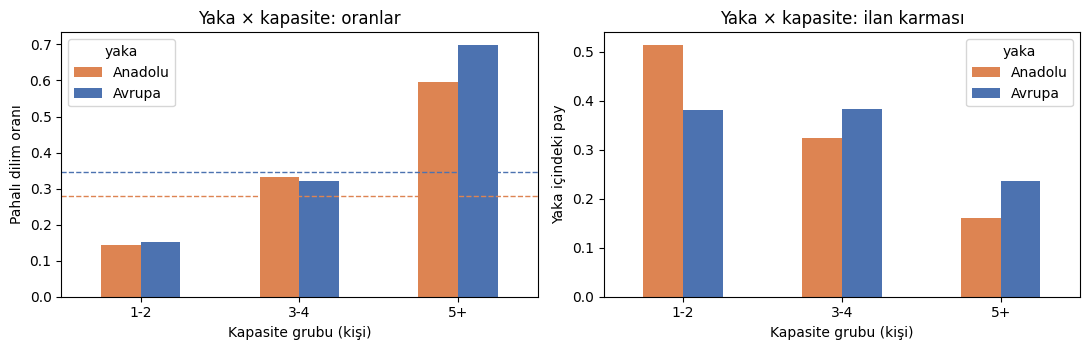

Grafik: solda her kapasite grubunda pahalı ilan oranı (kesikli çizgiler yakaların toplam oranı); sağda her yakanın ilanlarının kapasite gruplarına dağılımı. Anadolu'da küçük ilanların payı büyük, bu yüzden toplam oranı düşük görünüyor.
Avrupa − Anadolu: toplam yön + · oda_tipi kırılımında 2 hücre, tersine dönen: []
evet − hayır: toplam yön + · oda_tipi kırılımında 2 hücre, tersine dönen: []
evet − hayır: toplam yön + · kapasite kırılımında 3 hücre, tersine dönen: []
evet − hayır: toplam yön + · yaka kırılımında 2 hücre, tersine dönen: []


In [30]:
# ---- Toplulaştırmanın gizledikleri: "Avrupa yakası daha pahalı" eğilimi kapasite kırılımında
yaka_kap = kup.pivot_table(index="kapasite", columns="yaka", values="pahali", aggfunc=["mean", "size"], observed=True)
pay = yaka_kap["size"] / yaka_kap["size"].sum()                       # her yakanın kapasite karması
tablo_simpson = pd.concat({"pahalı oranı": yaka_kap["mean"].round(3), "ilan": yaka_kap["size"],
                           "yaka içi pay": pay.round(3)}, axis=1)
toplam = kup.groupby("yaka")["pahali"].mean()
print(f"Toplam: pahalı dilim oranı Avrupa {toplam['Avrupa']:.3f}, Anadolu {toplam['Anadolu']:.3f} → fark {toplam['Avrupa'] - toplam['Anadolu']:+.3f}")
display(tablo_simpson)

# Doğrudan standartlaştırma: Anadolu'nun oranlarını Avrupa'nın kapasite karmasıyla ağırlıklandır
w = pay["Avrupa"]
anadolu_std = (yaka_kap["mean"]["Anadolu"] * w).sum()
print(f"Kapasite karması eşitlenince: Avrupa {toplam['Avrupa']:.3f}, Anadolu {anadolu_std:.3f} → fark {toplam['Avrupa'] - anadolu_std:+.3f} "
      f"(toplam farkın {100 * (1 - (toplam['Avrupa'] - anadolu_std) / (toplam['Avrupa'] - toplam['Anadolu'])):.0f}%'i karmadan geliyor)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
yaka_kap["mean"].plot.bar(ax=ax[0], rot=0, color=["#DD8452", "#4C72B0"])
ax[0].axhline(toplam["Avrupa"], color="#4C72B0", ls="--", lw=1); ax[0].axhline(toplam["Anadolu"], color="#DD8452", ls="--", lw=1)
ax[0].set(xlabel="Kapasite grubu (kişi)", ylabel="Pahalı dilim oranı", title="Yaka × kapasite: oranlar")
pay.plot.bar(ax=ax[1], rot=0, color=["#DD8452", "#4C72B0"])
ax[1].set(xlabel="Kapasite grubu (kişi)", ylabel="Yaka içindeki pay", title="Yaka × kapasite: ilan karması")
plt.tight_layout(); plt.show()
print("Grafik: solda her kapasite grubunda pahalı ilan oranı (kesikli çizgiler yakaların toplam oranı); sağda her yakanın ilanlarının "
      "kapasite gruplarına dağılımı. Anadolu'da küçük ilanların payı büyük, bu yüzden toplam oranı düşük görünüyor.")

# ---- Diğer kırılımlar: eğilim alt gruplarda aynı yönde mi? (en az 150 ilanlı hücreler)
def tersine_donenler(grup, a, b, kirilim, olcu="pahali", min_n=150):
    d = kup[kup[grup].isin([a, b])]
    yon = np.sign(d.loc[d[grup] == a, olcu].mean() - d.loc[d[grup] == b, olcu].mean())
    t = d.pivot_table(index=kirilim, columns=grup, values=olcu, aggfunc=["mean", "size"], observed=True)
    t = t[t["size"].min(axis=1) >= min_n]
    fark = t["mean"][a] - t["mean"][b]
    return f"{a} − {b}: toplam yön {'+' if yon > 0 else '−'} · {kirilim} kırılımında {len(fark)} hücre, tersine dönen: {fark.index[np.sign(fark) != yon].tolist()}"
print(tersine_donenler("yaka", "Avrupa", "Anadolu", "oda_tipi"))
print(tersine_donenler("superhost", "evet", "hayır", "oda_tipi"))
print(tersine_donenler("superhost", "evet", "hayır", "kapasite"))
print(tersine_donenler("superhost", "evet", "hayır", "yaka"))

**Yorum**

**Küpün kurgusu.** Olgu bir ilan, ölçüler ilan sayısı, pahalı dilim oranı ve medyan gecelik fiyat; boyutlar konum (ilçe → yaka), oda tipi, kapasite (kişi → 1–2 / 3–4 / 5+) ve süper ev sahibi. Fiyat için ortalama yerine **medyanı** seçtik: fiyat aşırı sağa çarpık ve tek bir uç değer (≈ 5 milyon TL) ortalamayı çeker, medyanı çekmez. Medyanın bedeli **bütüncül** olmasıdır: ilçe medyanlarının medyanı İstanbul medyanını vermiyor (yukarıdaki kontrol), bu yüzden her düzeyde veriye yeniden baktık. İlan sayısı dağıtılabilir (ilçe sayımları toplanınca bütün çıkıyor), pahalı oranı cebirsel (ilçe oranlarının düz ortalaması yanlış, toplam/sayım doğru).

**Roll-up ve drill-down.** Yaka düzeyinde Avrupa daha pahalı görünüyor (pahalı oranı 0,345'e 0,278; medyan 3.800'e 3.250 TL). İlçeye inince tablo homojen değil: Avrupa'da Esenyurt, Kâğıthane ve Avcılar'ın medyanı 1.800–2.650 TL, Anadolu'da ise Adalar (6.000 TL) ve Şile (5.000 TL) şehrin en pahalı ilçeleri arasında; Üsküdar'ın medyanı (3.873 TL) Fatih'inkinden (3.400 TL) yüksek. Yukarı çıkmak ayrıntı kaybıdır. İki boyutlu küboit, fiyatı belirleyen asıl eksenin oda tipi ve kapasite olduğunu gösteriyor: tüm evde 1–2 kişilik ilanın medyanı ≈ 3.000, 5+ kişilik ilanın ≈ 6.800 TL.

**Toplulaştırmanın gizledikleri.** "Avrupa yakası daha pahalı" eğilimi kapasiteye göre açılınca zayıflıyor: 1–2 kişilik ilanlarda iki yaka neredeyse aynı (0,152'ye 0,144), 3–4 kişilik ilanlarda **tersine dönüyor** (Anadolu 0,332, Avrupa 0,320), fark yalnız 5+ kişilik evlerde kalıyor. Nedeni ilan karması: Anadolu'daki ilanların %51'i 1–2 kişilik (Avrupa'da %38). Kapasite karması eşitlenince 6,7 puanlık fark 2,3 puana iniyor; yani toplam farkın yaklaşık üçte ikisi "konum"dan değil, Anadolu'da küçük ilanların daha çok olmasından geliyor. Bu, Simpson paradoksunun kısmi bir biçimidir: karıştırılan boyut (kapasite) hem yakayla hem fiyatla ilişkili olduğu için toplam yanlış bir hikâye anlatıyor. Süper ev sahibi eğilimi ise oda tipi, kapasite ve yaka kırılımlarında aynı yönde kalıyor.

**Neyi söyleyemeyiz:** 3–4 kişilikteki tersine dönme küçük (1,2 puan) ve tek bir kırılımda; istatistiksel olarak sınamadık. Kapasite dışında yakayla ilişkili başka karıştırıcılar (oda tipi, ev sahibi profili) da olabilir; oda tipi × kapasite birlikte eşitlendiğinde fark 1,4 puana iniyor ama kaybolmuyor. Otel ve ortak oda hücreleri küçük olduğu için (Anadolu'da 26 ve 39 ilan) bu hücrelerdeki oranları yorumlamadık.


### 3.2 Birliktelik: seçenek ve kurulum
İşlem bilgisi varsa **A**, yoksa **B**. Veri değiştirilmez.

**Seçenek:** **B.** Her satır bir ilandır; sepet, sipariş ya da oturum bilgisi yoktur. Inside Airbnb'nin yorum tablosu konuk kimliği taşımadığı için "bir konuğun konakladığı ilanlar" gibi bir işlem de kurulamaz. Sayısal öznitelikleri ayrıklaştırıp her ilanı "öznitelik = değer" öğelerinden oluşan bir işlem olarak ele alıyoruz; hedef (fiyat dilimi) de bir öğedir. Ham veri değiştirilmez, ayrıklaştırma yeni bir tabloya yapılır.


In [31]:
!pip -q install "mlxtend==0.23.4"  # sürüm sabit: yeni mlxtend scikit-learn'ü 1.6.1'den yükseltiyor
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

# mlxtend içe aktarılırken bütün DeprecationWarning'leri "her zaman göster" yapıyor (mlxtend/frequent_patterns/fpcommon.py:8).
# Bu, Colab çekirdeğinin (jupyter_client) her mesajında bir uyarı basmasına yol açıyordu.
# Python'un varsayılanına dönüyoruz: yalnız defterdeki kendi kodumuzdan gelen DeprecationWarning'ler gösterilir.
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("default", category=DeprecationWarning, module="__main__")

In [32]:
# ---- B seçeneği: tabloyu işleme çevirmek (öznitelik = değer öğeleri). Kitle: model tablosuyla aynı 24.553 ilan.
islem = pd.DataFrame(index=veri.index)
islem["oda"]         = veri["room_type"].map({"Entire home/apt": "tum_ev", "Private room": "ozel_oda",
                                              "Hotel room": "otel", "Shared room": "ortak"})
islem["kapasite"]    = kup["kapasite"].astype(str)                                     # 3.1 ile aynı hiyerarşi
islem["yatak_odasi"] = pd.cut(veri["bedrooms"].fillna(1), bins=[-1, 1, 2, 99], labels=["0-1", "2", "3+"]).astype(str)
islem["min_gece"]    = np.select([veri["minimum_nights"] < 7, veri["minimum_nights"] < 28, veri["minimum_nights"] < 100],
                                 ["1-6", "7-27", "28-99"], "100+")                       # haftalık / aylık / mevzuat eşikleri
islem["lisans"]      = X["lisans_durumu"]                                               # 1.3'teki temizlenmiş hâli
islem["olanak"]      = pd.qcut(X["olanak_sayisi"], 3, labels=["az", "orta", "cok"]).astype(str)   # eşit sıklık
ilk5_ilce = veri["neighbourhood_cleansed"].value_counts().index[:5]
islem["ilce"]        = np.where(veri["neighbourhood_cleansed"].isin(ilk5_ilce), veri["neighbourhood_cleansed"], "diger")
islem["yaka"]        = kup["yaka"]
islem["superhost"]   = kup["superhost"].map({"evet": "evet", "hayır": "hayir"})
islem["host_ilan"]   = pd.cut(veri["calculated_host_listings_count"], bins=[0, 1, 10, 10**6], labels=["1", "2-10", "11+"]).astype(str)
islem["yorum"]       = pd.cut(veri["number_of_reviews"], bins=[-1, 0, 10, 10**6], labels=["yok", "1-10", "11+"]).astype(str)
islem["fiyat"]       = veri["fiyat_dilimi"].astype(str).replace({"pahalı": "pahali"})   # hedef (ASCII: Weka için)

print("Ayrıklaştırma sınırları:")
print("  olanak sayısı (eşit sıklık):", pd.qcut(X["olanak_sayisi"], 3).cat.categories.tolist())
print("  en az gece (alan bilgisi)  :", islem["min_gece"].value_counts().reindex(["1-6", "7-27", "28-99", "100+"]).to_dict())
print("  fiyat dilimi (hedef, 1.2)  :", ESIKLER_MODEL, "TL →", islem["fiyat"].value_counts().reindex(["ucuz", "orta", "pahali"]).to_dict())

T = pd.get_dummies(islem, prefix_sep="=")          # her satır bir işlem, her sütun bir öğe
N_ISLEM = len(T)
print(f"\n{N_ISLEM:,} işlem · {T.shape[1]} farklı öğe · her işlemde {int(T.sum(axis=1).iloc[0])} öğe")
print("Örnek işlem:", ", ".join(T.columns[T.iloc[0]]))

Ayrıklaştırma sınırları:
  olanak sayısı (eşit sıklık): [Interval(-0.001, 20.0, closed='right'), Interval(20.0, 38.0, closed='right'), Interval(38.0, 99.0, closed='right')]
  en az gece (alan bilgisi)  : {'1-6': 16184, '7-27': 326, '28-99': 228, '100+': 7815}
  fiyat dilimi (hedef, 1.2)  : [2750, 5100] TL → {'ucuz': 8311, 'orta': 8061, 'pahali': 8181}

24,553 işlem · 40 farklı öğe · her işlemde 12 öğe
Örnek işlem: oda=tum_ev, kapasite=3-4, yatak_odasi=0-1, min_gece=100+, lisans=yok, olanak=cok, ilce=Besiktas, yaka=Avrupa, superhost=hayir, host_ilan=2-10, yorum=11+, fiyat=orta


**Yorum**

**Ayrıklaştırma kararları.** Olanak sayısını **eşit sıklıkla** üçe böldük, çünkü sağa çarpık; eşit genişlikli gruplar üst aralığı neredeyse boş bırakırdı (3. hafta). En az gece için sınırları **alan bilgisinden** aldık: 7 gece haftalık indirimin, 28 gece Airbnb'nin "aylık konaklama" tanımının, 100 gece kısa dönem kiralama mevzuatının eşiğidir; 2.2'deki ağacın kökü de bu boşluğa düşüyordu. Kapasite 3.1'deki hiyerarşiyle aynıdır, böylece küp ile kurallar aynı dili konuşur. İlçede ilk beşi tutup kalan 34 ilçeyi "diğer"de birleştirdik, yoksa her ilçe nadir bir öğe olur ve en az destek eşiğini geçemezdi. Hedef olarak 1.2'deki fiyat dilimi aynen kullanıldı.

**Neyi söyleyemeyiz:** Sınırlar birer karardır; farklı sınırlar farklı kurallar üretir. Ayrıklaştırma bilgi kaybıdır: 2 yatak odalı ile 3 yatak odalı ilan arasındaki fark kurallarda var, 3 ile 5 arasındaki yok. Yorum sayısı ilanın geçmiş performansıdır; grup kararıyla (`SENARYO = "mevcut_ilan"`) modelde de kullanıldığı için burada da tuttuk, ama yeni ilan açan bir ev sahibi için bilinmez.


### 3.3 Kurallar ve ilgi ölçütleri
**A:** işlem tanımı; Apriori ve FP-Growth, en az üç `min_support`; güven, lift ve Kulczynski; null-invariance testi.
**B:** ayrıklaştırma ve "öznitelik = değer" işlemleri; hedefe yönelik kurallar; lift ve Kulczynski; Proje 1 modelinin önemli öznitelikleriyle karşılaştırma.
İki seçenekte de üç kuralın alan bilgisiyle yorumu.

In [33]:
import time
# ---- Ölçeklenme (bilgi amaçlı): üç en az destek değerinde Apriori ve FP-Growth (öncül en fazla 2 öğe)
olcek_satir = []
for ms in [0.02, 0.05, 0.10]:
    t0 = time.time(); fa = apriori(T, min_support=ms, use_colnames=True, max_len=3); ta = time.time() - t0
    t0 = time.time(); ff = fpgrowth(T, min_support=ms, use_colnames=True, max_len=3); tf = time.time() - t0
    olcek_satir.append({"min_support": ms, "en az işlem": int(np.ceil(ms * N_ISLEM)), "sık küme": len(fa),
                        "Apriori (sn)": round(ta, 2), "FP-Growth (sn)": round(tf, 2), "aynı kümeler": set(fa["itemsets"]) == set(ff["itemsets"])})
display(pd.DataFrame(olcek_satir).set_index("min_support"))

# ---- Hedefe yönelik kurallar: sonuç yalnız fiyat=ucuz / orta / pahali
MIN_SUP, MIN_CONF = 0.05, 0.5                       # en az 1.228 ilan (0,05 × 24.553, yukarı yuvarlanmış)
HEDEF_OGELER = {"fiyat=ucuz", "fiyat=orta", "fiyat=pahali"}

def hedef_kurallari(sik, min_conf):
    r = association_rules(sik, metric="confidence", min_threshold=min_conf)
    r = r[r["consequents"].apply(lambda s: len(s) == 1 and next(iter(s)) in HEDEF_OGELER)].copy()
    sA, sB, sAB = r["antecedent support"], r["consequent support"], r["support"]
    r["kulczynski"] = 0.5 * (sAB / sA + sAB / sB)                      # ½·(P(B|A) + P(A|B))
    r["IR"] = (sA - sB).abs() / (sA + sB - sAB)                         # dengesizlik oranı
    r["A_ilan"] = (sA * N_ISLEM).round().astype(int)
    r["A"] = r["antecedents"].apply(lambda s: ", ".join(sorted(s)))
    r["B"] = r["consequents"].apply(lambda s: next(iter(s)))
    return r

KOL = ["A", "B", "A_ilan", "support", "confidence", "lift", "kulczynski", "IR"]
sik = apriori(T, min_support=MIN_SUP, use_colnames=True, max_len=3)
kurallar = hedef_kurallari(sik, MIN_CONF)
print(f"Hedefe yönelik güçlü kural (destek ≥ {MIN_SUP}, güven ≥ {MIN_CONF}): {len(kurallar)} · sonuca göre:",
      kurallar["B"].value_counts().reindex(sorted(HEDEF_OGELER), fill_value=0).to_dict())
for hedef in ["fiyat=pahali", "fiyat=ucuz"]:
    k = kurallar[kurallar["B"] == hedef]
    print(f"\n=== {hedef} · LIFT'e göre ilk 5 ===");       display(k.sort_values("lift", ascending=False)[KOL].head(5).round(3))
    print(f"=== {hedef} · KULCZYNSKI'ye göre ilk 5 ==="); display(k.sort_values("kulczynski", ascending=False)[KOL].head(5).round(3))

# "orta" dilime giden kural güven 0,5'i geçmiyor: eşiği düşürüp en iyilerine bakıyoruz
orta = hedef_kurallari(sik, 0.3)
print("\n=== fiyat=orta · güven ≥ 0,3, LIFT'e göre ilk 5 ===")
display(orta[orta["B"] == "fiyat=orta"].sort_values("lift", ascending=False)[KOL].head(5).round(3))

,en az işlem,sık küme,Apriori (sn),FP-Growth (sn),aynı kümeler
min_support,,,,,
0.02,492,3384,0.95,294.75,True
0.05,1228,1868,0.30,146.09,True
0.10,2456,860,0.23,64.25,True


Hedefe yönelik güçlü kural (destek ≥ 0.05, güven ≥ 0.5): 109 · sonuca göre: {'fiyat=orta': 0, 'fiyat=pahali': 45, 'fiyat=ucuz': 64}

=== fiyat=pahali · LIFT'e göre ilk 5 ===


,A,B,A_ilan,support,confidence,lift,kulczynski,IR
1695,"min_gece=1-6, yatak_odasi=3+",fiyat=pahali,1787,0.067,0.921,2.763,0.561,0.768
1700,"lisans=numara, yatak_odasi=3+",fiyat=pahali,1547,0.058,0.915,2.747,0.544,0.798
1293,"kapasite=5+, superhost=evet",fiyat=pahali,1685,0.060,0.868,2.606,0.524,0.773
1228,"kapasite=5+, yatak_odasi=3+",fiyat=pahali,2350,0.078,0.817,2.452,0.526,0.677
565,"oda=tum_ev, yatak_odasi=3+",fiyat=pahali,2400,0.079,0.804,2.412,0.520,0.668


=== fiyat=pahali · KULCZYNSKI'ye göre ilk 5 ===


,A,B,A_ilan,support,confidence,lift,kulczynski,IR
1248,"kapasite=5+, min_gece=1-6",fiyat=pahali,3945,0.129,0.801,2.402,0.593,0.472
64,kapasite=5+,fiyat=pahali,5453,0.152,0.685,2.056,0.571,0.276
474,"kapasite=5+, oda=tum_ev",fiyat=pahali,5124,0.145,0.697,2.090,0.566,0.314
1266,"kapasite=5+, lisans=numara",fiyat=pahali,3436,0.111,0.792,2.376,0.562,0.533
1695,"min_gece=1-6, yatak_odasi=3+",fiyat=pahali,1787,0.067,0.921,2.763,0.561,0.768



=== fiyat=ucuz · LIFT'e göre ilk 5 ===


,A,B,A_ilan,support,confidence,lift,kulczynski,IR
392,"host_ilan=1, oda=ozel_oda",fiyat=ucuz,1867,0.065,0.854,2.522,0.523,0.751
344,"lisans=yok, oda=ozel_oda",fiyat=ucuz,2947,0.101,0.839,2.479,0.568,0.611
322,"min_gece=100+, oda=ozel_oda",fiyat=ucuz,3056,0.104,0.832,2.458,0.569,0.596
997,"kapasite=1-2, lisans=yok",fiyat=ucuz,3563,0.116,0.800,2.364,0.572,0.526
969,"kapasite=1-2, min_gece=100+",fiyat=ucuz,3685,0.120,0.800,2.363,0.577,0.511


=== fiyat=ucuz · KULCZYNSKI'ye göre ilk 5 ===


,A,B,A_ilan,support,confidence,lift,kulczynski,IR
134,min_gece=100+,fiyat=ucuz,7815,0.203,0.638,1.884,0.619,0.045
2047,"min_gece=100+, superhost=hayir",fiyat=ucuz,7652,0.199,0.640,1.890,0.614,0.060
1973,"lisans=yok, min_gece=100+",fiyat=ucuz,7472,0.196,0.644,1.903,0.612,0.076
161,lisans=yok,fiyat=ucuz,7584,0.197,0.638,1.884,0.610,0.066
2270,"lisans=yok, superhost=hayir",fiyat=ucuz,7452,0.194,0.640,1.891,0.607,0.078



=== fiyat=orta · güven ≥ 0,3, LIFT'e göre ilk 5 ===


,A,B,A_ilan,support,confidence,lift,kulczynski,IR
2423,"kapasite=3-4, min_gece=1-6",fiyat=orta,6141,0.122,0.486,1.481,0.428,0.171
2493,"kapasite=3-4, lisans=numara",fiyat=orta,5321,0.104,0.480,1.461,0.398,0.253
2698,"kapasite=3-4, yorum=11+",fiyat=orta,3469,0.068,0.480,1.461,0.343,0.465
2577,"kapasite=3-4, olanak=orta",fiyat=orta,3194,0.062,0.476,1.450,0.332,0.500
2680,"host_ilan=11+, kapasite=3-4",fiyat=orta,3212,0.061,0.469,1.430,0.328,0.497


In [34]:
# ---- Nadir kategorilerde lift ile Kulczynski'nin farkı: otel odası (264), ortak oda (149), lisans muaf (179)
# Bu öğelerin desteği 0,05'in çok altında: eşiği 0,003'e (≈ 74 ilan) indirip yalnız tek öncüllü kurallara bakıyoruz.
sik_nadir = apriori(T, min_support=0.003, use_colnames=True, max_len=2)
nadir = hedef_kurallari(sik_nadir, 0.3)
nadir = nadir[nadir["A"].isin(["oda=otel", "oda=ortak", "lisans=muaf"])]
yaygin = kurallar[kurallar["A"].isin(["min_gece=100+", "kapasite=5+", "kapasite=1-2"])]
print("Nadir öncüller (lift yüksek, Kulczynski nötrün altında):"); display(nadir[KOL].round(3))
print("Karşılaştırma için yaygın öncüller:");                     display(yaygin[KOL].round(3))

# ---- Bölüm 2 modeliyle karşılaştırma: rastgele ormanın permütasyon önemi (ev sahibine göre ilk test katı)
from sklearn.base import clone
from sklearn.inspection import permutation_importance
rf_hat = clone(MODELLER_21[SECILEN])
egitim, test = CV_GRUP[0]
rf_hat.fit(X.iloc[egitim], y[egitim])
pi = permutation_importance(rf_hat, X.iloc[test], y[test], scoring="f1_macro", n_repeats=3, random_state=SEED, n_jobs=-1)
onem = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False)
print(f"{SECILEN} · permütasyon önemi (makro F1 düşüşü, test katı {len(test):,} ilan) · ilk 8:")
display(onem.head(8).round(4).to_frame("önem"))
print("Ayrıntılı öznitelik önemi analizi Ek paket 1 (E1.3)'te; burada yalnız kurallarla karşılaştırma için.")

Nadir öncüller (lift yüksek, Kulczynski nötrün altında):


,A,B,A_ilan,support,confidence,lift,kulczynski,IR
9,oda=ortak,fiyat=ucuz,149,0.004,0.597,1.765,0.304,0.975
23,oda=otel,fiyat=pahali,264,0.006,0.587,1.762,0.303,0.955


Karşılaştırma için yaygın öncüller:


,A,B,A_ilan,support,confidence,lift,kulczynski,IR
52,kapasite=1-2,fiyat=ucuz,9938,0.222,0.549,1.621,0.602,0.127
64,kapasite=5+,fiyat=pahali,5453,0.152,0.685,2.056,0.571,0.276
134,min_gece=100+,fiyat=ucuz,7815,0.203,0.638,1.884,0.619,0.045


Rastgele orman · 300 ağaç · permütasyon önemi (makro F1 düşüşü, test katı 4,862 ilan) · ilk 8:


,önem
log_min_gece,0.0404
kapasite,0.0310
lisans_durumu,0.0212
boylam,0.0152
yatak_odasi,0.0149
enlem,0.0108
puan_konum,0.0107
aylik_yorum,0.0099


Ayrıntılı öznitelik önemi analizi Ek paket 1 (E1.3)'te; burada yalnız kurallarla karşılaştırma için.


**Yorum**

**İki sıralama, iki farklı hikâye.** Lift'e göre en güçlü kurallar dar, iki koşullu öncüller: `min_gece=1-6 ∧ yatak_odasi=3+ → pahalı` (1.787 ilan, güven 0,92, lift 2,76) ya da `host_ilan=1 ∧ oda=özel_oda → ucuz` (1.867 ilan, güven 0,85, lift 2,52). Kulczynski'ye göre en güçlüler ise geniş, tek koşullu öncüller: `kapasite=5+ → pahalı` (5.453 ilan) ve `min_gece=100+ → ucuz` (7.815 ilan, Kulczynski 0,62, IR 0,05). Fark makalenin öngördüğü yerde: lift, öncül daraldıkça büyür; Kulczynski her iki yönün koşullu olasılığını birlikte istediği için hedef sınıfın ancak küçük bir kısmını açıklayan dar öncülleri cezalandırır (dar kuralların IR'si 0,7–0,8: tek yönlü ilişki). Nadir öncüllerde fark en uçta: `oda=otel → pahalı` lift'e göre güçlü (1,76), ama Kulczynski 0,30 ve IR 0,96; otel odaları pahalı ilanların yalnız %2'si. **Orta dilime giden hiçbir kural güven 0,5'i geçmiyor**: orta dilim iki komşusuyla sınır paylaştığı için hiçbir öznitelik değeri onu tek başına belirlemiyor. Bu, 1.6'daki hata analiziyle tutarlı: orta dilim en zor sınıftı (doğru sınıflanan oranı %52).

**Üç kuralın alan bilgisiyle yorumu.** (1) **`min_gece=100+ → ucuz`** (güven 0,64, Kulczynski 0,62): en az 100 gece isteyen ilanlar aylık fiyatlandırılır ve Inside Airbnb gecelik fiyatı aylık indirimli fiyattan türetir; ayrıca 100 geceden kısa kiralama turizm izni gerektirdiği için izinsiz ilanlar uzun dönem kiralıyor. Yani bu kural kısmen piyasayı, kısmen ölçümü (fiyatın nasıl hesaplandığını) yansıtıyor. (2) **`kapasite=5+ → pahalı`** (güven 0,69): gecelik fiyat konaklayan kişi sayısıyla birlikte artar; kural "pahalı ilan" değil "büyük ilan" söylüyor, kişi başı fiyatta bu ilişki zayıflar (1.2'de alternatif hedef olarak anıldı). (3) **`host_ilan=1 ∧ oda=özel_oda → ucuz`** (güven 0,85): tek ilanı olan ve evinin bir odasını kiralayan ev sahipleri, profesyonel işletmecilere göre ucuz fiyatlıyor; bu, paylaşım ekonomisinin "kendi evinde oda" kesimiyle profesyonel kısa dönem kiralama kesiminin ayrı fiyat düzeylerinde olduğunu düşündürüyor.

**Modelle karşılaştırma.** Rastgele ormanın permütasyon önemi listesinin başındaki öznitelikler (en az gece, kapasite, lisans durumu, yatak odası) kuralların öncüllerinde de yer alıyor; ilk sekizde bunlara boylam, enlem, konum puanı ve aylık yorum sayısı ekleniyor; 2.2'deki ağacın kökü de en az gece, ikinci düzeyi yatak odası ve kapasiteydi. Örtüşme beklenir: üçü de aynı tek değişkenli sinyalleri yakalıyor. Kuralların modelden fazlası bu sinyalleri okunur eşiklerle (100 gece, 5+ kişi, 3+ yatak odası) ifade etmesi; modelin kurallardan fazlası ise enlem–boylam gibi ayrıklaştırılınca kaybolan sürekli bilgiyi kullanması.

**Neyi söyleyemeyiz:** Kurallar nedensellik söylemez; büyük bir ev açmak fiyatı "yükseltmez", büyük evler zaten pahalıdır. Kurallar ayrıklaştırma sınırlarına bağlıdır. Destek eşiği (0,05) nadir ama ilginç örüntüleri (ör. Adalar'daki yazlık evler) dışarıda bırakıyor; bunlar için eşiği düşürmek kural sayısını hızla artırır ve rastlantısal kuralların payını büyütür.


### 3.4 Weka ile kontrol
Aynı eşiklerde Weka Apriori çıktısı.

In [35]:
# ---- Weka için ARFF: işlem tablosunun kendisi (bütün öznitelikler nominal; sınıf = fiyat, en sonda)
from pathlib import Path
ARFF_ISLEM = "weka_airbnb_islem.arff"          # veri dosyasıdır: GitHub'a konmaz (.gitignore)
satirlar = ["@relation airbnb_istanbul_islem", ""]
for c in islem.columns:
    satirlar.append(f"@attribute {c} {{{','.join(sorted(islem[c].astype(str).unique()))}}}")
satirlar += ["", "@data"] + [",".join(map(str, r)) for r in islem.astype(str).itertuples(index=False)]
Path(ARFF_ISLEM).write_text("\n".join(satirlar), encoding="utf-8")
print(f"{ARFF_ISLEM} yazıldı: {len(islem):,} işlem, {islem.shape[1]} nominal öznitelik (sonuncusu sınıf: fiyat)")

# ---- Eşik: 0,05 × N = 1227,65. Weka bunu en yakın tamsayıya yuvarlar (1228); mlxtend "destek ≥ 0,05" der → yine en az 1228
ESIK_ILAN = int(np.ceil(MIN_SUP * N_ISLEM))
print(f"0,05 × {N_ISLEM:,} = {MIN_SUP * N_ISLEM:.2f} → iki araçta da en az {ESIK_ILAN} işlem")

# ---- Weka'nın sınıf birliktelik kurallarının (car = True) Python karşılığı:
#      sonuç = fiyat dilimi, öncül uzunluğu SINIRSIZ (Weka'da sınır yok), güven ≥ 0,5, güvene göre sıralı
sik_car = apriori(T, min_support=MIN_SUP, use_colnames=True)
sinif_ici = sik_car[sik_car["itemsets"].apply(lambda s: sum(o in HEDEF_OGELER for o in s) == 1 and len(s) > 1)]
L_PY = sinif_ici["itemsets"].apply(len).sub(1).value_counts().sort_index().to_dict()
print("Python · sınıfı içeren sık kümeler, öncül uzunluğuna göre (Weka'daki L(k)):", L_PY)
kural_car = hedef_kurallari(sik_car, MIN_CONF)
kural_car["AB_ilan"] = (kural_car["support"] * N_ISLEM).round().astype(int)
kural_car = kural_car.sort_values(["confidence", "AB_ilan"], ascending=False)
print(f"Python · sınıf kuralı sayısı (güven ≥ 0,5): {len(kural_car):,}")
display(kural_car[["A", "B", "A_ilan", "AB_ilan", "confidence", "lift"]].head(10).round(3))

weka_airbnb_islem.arff yazıldı: 24,553 işlem, 12 nominal öznitelik (sonuncusu sınıf: fiyat)
0,05 × 24,553 = 1227.65 → iki araçta da en az 1228 işlem
Python · sınıfı içeren sık kümeler, öncül uzunluğuna göre (Weka'daki L(k)): {1: 73, 2: 380, 3: 731, 4: 623, 5: 265, 6: 58, 7: 5}
Python · sınıf kuralı sayısı (güven ≥ 0,5): 1,050


,A,B,A_ilan,AB_ilan,confidence,lift
30750,"kapasite=5+, lisans=numara, min_gece=1-6, oda=...",fiyat=pahali,1376,1305,0.948,2.846
21904,"kapasite=5+, lisans=numara, min_gece=1-6, yata...",fiyat=pahali,1422,1342,0.944,2.832
16603,"lisans=numara, min_gece=1-6, oda=tum_ev, yatak...",fiyat=pahali,1410,1328,0.942,2.827
14993,"kapasite=5+, min_gece=1-6, oda=tum_ev, yatak_o...",fiyat=pahali,1663,1563,0.940,2.821
30782,"kapasite=5+, min_gece=1-6, oda=tum_ev, yaka=Av...",fiyat=pahali,1489,1399,0.940,2.820
21920,"kapasite=5+, min_gece=1-6, yaka=Avrupa, yatak_...",fiyat=pahali,1535,1441,0.939,2.817
15023,"kapasite=5+, lisans=numara, oda=tum_ev, yatak_...",fiyat=pahali,1438,1347,0.937,2.811
7636,"kapasite=5+, min_gece=1-6, yatak_odasi=3+",fiyat=pahali,1721,1609,0.935,2.806
16618,"min_gece=1-6, oda=tum_ev, yaka=Avrupa, yatak_o...",fiyat=pahali,1520,1421,0.935,2.806
4657,"min_gece=1-6, oda=tum_ev, yatak_odasi=3+",fiyat=pahali,1706,1592,0.933,2.801


In [36]:
# ---- Weka Apriori, AYNI ARFF ve AYNI eşiklerle. Masaüstü Weka gerekmez: Weka 3.8'in kendi weka.jar'ı Java ile çalıştırılır.
#  Explorer'daki karşılığı (Associate → Apriori): car = True · classIndex = -1 · metricType = Confidence · minMetric = 0.5
#    lowerBoundMinSupport = 0.05 · upperBoundMinSupport = 1.0 · delta = 0.05 · numRules = 2000
#  Neden numRules = 2000 ve üst sınır 1.0? Weka desteği 1,0'dan başlayıp delta adımlarıyla düşürür ve numRules kurala
#  ulaşınca DURUR: numRules = 10 ile 0,15'te durur (0,05'e hiç inmez). car = True iken üst sınır ayrıca kuralların
#  desteğine tavan gibi davranıyor (0,10 verince desteği 0,10'u aşan kurallar listeden düşüyor) — denedik, bu yüzden 1.0.
# weka.jar ve _weka/ klasörü de GitHub'a konmaz (.gitignore)
import glob, os, re, shutil, subprocess, sys, tarfile

def weka_jar():
    """python-weka-wrapper3 kaynak paketinin içindeki weka.jar'ı (Weka 3.8) çıkarır; paket KURULMAZ, yalnız indirilir."""
    if os.path.exists("weka.jar"):
        return "weka.jar"
    subprocess.run([sys.executable, "-m", "pip", "download", "-q", "python-weka-wrapper3==0.3.3",
                    "--no-deps", "--no-binary", ":all:", "-d", "_weka"], check=True)
    with tarfile.open(glob.glob("_weka/*.tar.gz")[0]) as t:
        uye = next(m for m in t.getmembers() if m.name.endswith("/weka/lib/weka.jar"))
        with open("weka.jar", "wb") as f:
            f.write(t.extractfile(uye).read())
    return "weka.jar"

if shutil.which("java") is None:                      # Colab'da genelde Java vardır; yoksa kur
    subprocess.run("apt-get -qq install -y default-jre-headless > /dev/null", shell=True)

komut = ["java", "--add-opens", "java.base/java.lang=ALL-UNNAMED", "-Xmx2g", "-cp", weka_jar(),
         "weka.associations.Apriori", "-t", ARFF_ISLEM, "-A", "-c", "-1",
         "-T", "0", "-C", "0.5", "-M", "0.05", "-U", "1.0", "-D", "0.05", "-N", "2000"]
weka_apriori = subprocess.run(komut, capture_output=True, text=True).stdout

# Çıktının başı + ilk 10 kural (tamamı 1.000+ satır)
bas, _, kurallar = weka_apriori.partition("Best rules found:")
print(bas.strip(), "\n\nBest rules found:")
print("\n".join(kurallar.strip().splitlines()[:10]))

# ---- Otomatik karşılaştırma: eşik, L(k) sayıları, kural kümesi
L_WEKA = {int(k): int(v) for k, v in re.findall(r"L\((\d+)\): (\d+)", weka_apriori)}
k_w = {(frozenset(a.split()), b) for a, b in re.findall(r"^\s*\d+\.\s+(.*?) \d+ ==> (\S+) \d+", weka_apriori, flags=re.M)}
k_p = set(zip(kural_car["antecedents"], kural_car["B"]))
print("\nKarşılaştırma")
print("  Weka eşiği              :", re.search(r"Minimum support: .*", weka_apriori).group(0))
print("  L(k) Weka = Python      :", L_WEKA == L_PY, L_WEKA)
print(f"  kural sayısı            : Weka {len(k_w):,} · Python {len(k_p):,} · ortak {len(k_w & k_p):,}")
ilk10_w = re.findall(r"^\s*\d+\.\s+(.*?) (\d+) ==> (\S+) (\d+)", weka_apriori, flags=re.M)[:10]
ilk10_p = kural_car.head(10)
print("  ilk 10 kural aynı sayılarla:", all(int(nA) == a and int(nAB) == ab
      for (_, nA, _, nAB), a, ab in zip(ilk10_w, ilk10_p["A_ilan"], ilk10_p["AB_ilan"])))

[0.039s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.039s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate

Apriori

Minimum support: 0.05 (1228 instances)
Minimum metric <confidence>: 0.5
Number of cycles performed: 19

Generated sets of large itemsets:

Size of set of large itemsets L(1): 73

Size of set of large itemsets L(2): 380

Size of set of large itemsets L(3): 731

Size of set of large itemsets L(4): 623

Size of set of large itemsets L(5): 265

Size of set of large itemsets L(6): 58

Size of set of large itemsets L(7): 5 

Best rules found:
1. oda=tum_ev kapasite=5+ yatak_odasi=3+ min_gece=1-6 lisans=numara 1376 ==> fiyat=pahali 1305    conf:(0.95)
   2. kapasite=5+ yatak_odasi=3+ min_gece=1-6 lisans=numara 1422 ==> fiyat=pahali 1342    conf:(0.94)
   3. od

**Yorum**

**Kurulum.** İşlem tablosu ARFF olarak kaydedildi ve Weka 3.8'in Apriori'si aynı dosyada, aynı eşiklerle (destek 0,05, güven 0,5) çalıştırıldı. Weka'nın sınıf birliktelik kuralları (`car = True`, sınıf = fiyat) Python'daki "sonucu fiyat dilimi olan kurallar" ile aynı tanıma sahiptir; tek fark Weka'da öncül uzunluğu sınırsız olduğu için Python'da da bu kontrolde sınırı kaldırdık. Eşik: 0,05 × 24.553 = 1.227,65; Weka en yakın tamsayıya yuvarlayıp "1228 instances" yazıyor, mlxtend "destek ≥ 0,05" istediği için o da pratikte en az 1.228 işlem arıyor. Yani bu veride iki araç aynı eşikte.

**Sonuç: iki araç birebir aynı.** Weka'nın sınıfı içeren sık küme sayıları (L(1)…L(7): 73, 380, 731, 623, 265, 58, 5) Python'la aynı; kural sayısı ikisinde de 1.050 ve kümeler örtüşüyor; güvene göre ilk 10 kural aynı sırada, aynı öncül ve kural işlem sayılarıyla geliyor. İlk kuralların hepsi `fiyat=pahali` sonuçlu ve öncülünde `yatak_odasi=3+`, `kapasite=5+`, `min_gece=1-6` bulunan 4–5 öğeli kurallar (güven 0,93–0,95).

**Weka ayarlarında öğrendiğimiz iki şey.** (1) Weka desteği 1,0'dan başlayıp delta adımlarıyla düşürür ve `numRules` kurala ulaşınca durur; varsayılan `numRules = 10` ile 0,15'te durdu ve 0,05'e hiç inmedi. "Aynı eşik" için `numRules`'u büyük verdik (2000). (2) `car = True` iken üst destek sınırı kurallara tavan gibi davrandı: 0,10 verdiğimizde desteği 0,10'u aşan 146 kural (ör. `kapasite=5+ → pahalı`) listeden düştü, 0,05 verdiğimizde yalnız 2 kural kaldı. Bu yüzden üst sınırı 1,0 bıraktık. Weka çıktısının başındaki "Minimum support" satırını kontrol etmeden iki aracın aynı eşikte çalıştığını varsaymak yanıltıcı olurdu.

**Neyi söyleyemeyiz:** Weka kontrolü sayımların doğru yapıldığını gösterir, ayrıklaştırma kararlarının doğru olduğunu göstermez: iki araç aynı tabloyu aynı biçimde sayıyor. Weka bu modda yalnız güveni yazıyor; Kulczynski ve IR gibi null-değişmez ölçütler için Python gerekiyor. Güvene göre sıralanan uzun kurallar birbirinin neredeyse aynısı (aynı 1.300–1.600 ilanı tarif ediyorlar); 3.3'te öncülü en fazla iki öğeyle sınırlamamızın nedeni bu.


# Ek paket 1 · Topluluk yöntemleri ve öznitelik önemi *(4 ve 5 kişilik gruplar)*

### E1.1 Budama eğrisi
Karar ağacında `ccp_alpha` taraması; ağaç boyutu ile eğitim ve test başarımı aynı grafikte.

Eğitim: 19,691 ilan / 6,822 ev sahibi · Test: 4,862 ilan / 1,728 ev sahibi · ortak ev sahibi: 0
Budama yolunda 2,444 farklı alfa (8.5e-06 … 6.6e-02)


,yaprak,doğrulama F1 (iç ÇD),TEST F1
ağaç,,,
Budamasız (alfa = 0),4111,0.563,0.577
En iyi doğrulama (alfa = 8.7e-04),36,0.613,0.621
1-SH kuralı · SEÇİLEN (alfa = 8.7e-04),36,0.613,0.621
2.1–2.2: yaprak ≥ 20,689,NaN,0.597
"2.3 ızgarası: derinlik 8, yaprak ≥ 50",131,NaN,0.630


Seçilen ağaç: 36 yaprak, derinlik 9 · budamasız ağaç: 4,111 yaprak, derinlik 33, eğitim F1 1.000


,alfa,yaprak,derinlik,egitim_f1,dogrulama_f1,dogrulama_std,test_f1
0,0.0000,4111,33,0.9996,0.5627,0.0132,0.5766
3,0.0000,4106,33,0.9996,0.5627,0.0132,0.5766
6,0.0000,4015,33,0.9995,0.5628,0.0133,0.5774
9,0.0001,1602,28,0.9396,0.5720,0.0165,0.5939
12,0.0003,262,18,0.7648,0.6033,0.0159,0.6209
15,0.0006,55,12,0.6657,0.6075,0.0093,0.6201
18,0.0016,16,8,0.6264,0.6017,0.0085,0.6148
21,0.0041,8,4,0.5987,0.5935,0.0060,0.6073
24,0.0103,5,3,0.5847,0.5838,0.0123,0.5881
27,0.0260,3,2,0.5847,0.5838,0.0123,0.5881


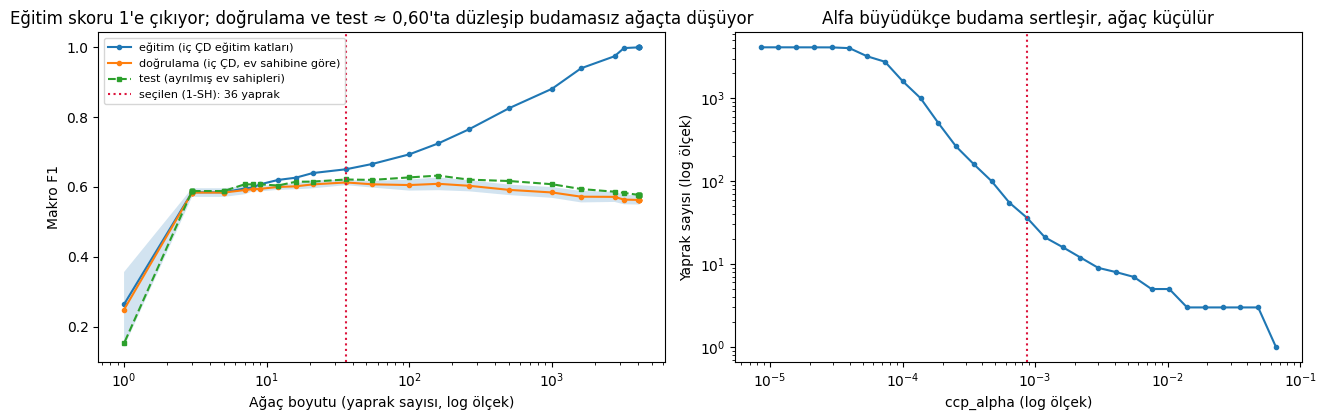

Grafik: solda yatay eksen ağaç boyutu; mavi eğitim, turuncu doğrulama (bant ± std), yeşil test. Kırmızı çizgi 1-SH kuralının seçtiği ağaç. Sağda budama gücü (alfa) ile ağaç boyutu ilişkisi.


In [37]:
# =====================================================================
# Ek paket 1 · ortak kurulum
# Önkoşul: ortak hat (X, y, gruplar, CV_GRUP, on_isleme), 2.1 (MODELLER_21), 2.2 (agac_on_isleme), 2.5 (SECILEN)
# Bütün Ek 1 deneyleri ev sahibine göre ayrılmış AYNI eğitim / test bölmesinde: CV_GRUP[0]
# (3.3'teki permütasyon önemiyle aynı bölme). Test kısmı hiçbir SEÇİMDE (alfa, ağaç sayısı) kullanılmaz; yalnız raporlanır.
# =====================================================================
import warnings
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.metrics import f1_score, accuracy_score
from sklearn.tree import DecisionTreeClassifier

EG, TE = CV_GRUP[0]
print(f"Eğitim: {len(EG):,} ilan / {len(np.unique(gruplar[EG])):,} ev sahibi · Test: {len(TE):,} ilan / {len(np.unique(gruplar[TE])):,} ev sahibi · "
      f"ortak ev sahibi: {len(set(gruplar[EG]) & set(gruplar[TE]))}")

# =====================================================================
# E1.1 Budama eğrisi: ccp_alpha (maliyet-karmaşıklık budaması) taraması
# Ağaç 2.2'deki ölçeksiz hatla kurulur (agac_on_isleme); ölçüt makro F1 (bütün defterle aynı).
# =====================================================================
def budamali_agac(alfa):
    return Pipeline([("on", agac_on_isleme()), ("model", DecisionTreeClassifier(ccp_alpha=alfa, random_state=SEED))])

# (1) Budama yolu: tam büyümüş ağaçtan başlayıp her adımda "en az işe yarayan" dalı kesen alfa değerleri.
#     YALNIZ eğitim kısmından hesaplanır (ön işleme de yalnız eğitimde fit edilir).
on_e11 = agac_on_isleme().fit(X.iloc[EG], y[EG])
yol = DecisionTreeClassifier(random_state=SEED).cost_complexity_pruning_path(on_e11.transform(X.iloc[EG]), y[EG])
pozitif = yol.ccp_alphas[yol.ccp_alphas > 0]
print(f"Budama yolunda {len(yol.ccp_alphas):,} farklı alfa ({pozitif.min():.1e} … {pozitif.max():.1e})")
ALFALAR = np.r_[0.0, np.geomspace(pozitif.min(), pozitif.max(), 30)]   # 0 = budamasız ağaç + logaritmik 30 değer

# (2) Her alfa için: eğitim kısmında ev sahibine göre 5 katlı iç ÇD (eğitim ve doğrulama makro F1'i)
#     + bütün eğitim kısmıyla kurulup TEST kısmında ölçülen makro F1. Alfa SEÇİMİ yalnız doğrulama skoruyla yapılır.
ic_cv_e11 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
satirlar = []
for a in ALFALAR:
    cvs = cross_validate(budamali_agac(a), X.iloc[EG], y[EG], groups=gruplar[EG], cv=ic_cv_e11, scoring="f1_macro",
                         return_train_score=True, n_jobs=-1)
    tam = budamali_agac(a).fit(X.iloc[EG], y[EG])
    satirlar.append({"alfa": a, "yaprak": tam.named_steps["model"].get_n_leaves(), "derinlik": tam.named_steps["model"].get_depth(),
                     "egitim_f1": cvs["train_score"].mean(),
                     "dogrulama_f1": cvs["test_score"].mean(), "dogrulama_std": cvs["test_score"].std(),
                     "test_f1": f1_score(y[TE], tam.predict(X.iloc[TE]), average="macro")})
budama = pd.DataFrame(satirlar)

# (3) Nerede durmalı? Bir standart hata (1-SH) kuralı: en iyi doğrulama skorundan en fazla 1 SH aşağıda kalan EN BASİT ağaç
en_iyi = budama["dogrulama_f1"].idxmax()
sh = budama.loc[en_iyi, "dogrulama_std"] / np.sqrt(ic_cv_e11.get_n_splits())
SECILEN_ALFA = budama.loc[budama["dogrulama_f1"] >= budama.loc[en_iyi, "dogrulama_f1"] - sh, "alfa"].max()
s_ = budama.set_index("alfa").loc[SECILEN_ALFA]
b0 = budama.iloc[0]

# Bağlam: 2.1–2.3'te kullanılan ağaçlar aynı bölmede (yalnız karşılaştırma için)
def agac_test_f1(**p):
    m = Pipeline([("on", agac_on_isleme()), ("model", DecisionTreeClassifier(random_state=SEED, **p))]).fit(X.iloc[EG], y[EG])
    return f1_score(y[TE], m.predict(X.iloc[TE]), average="macro"), m.named_steps["model"].get_n_leaves()
karsilastirma = pd.DataFrame([
    {"ağaç": "Budamasız (alfa = 0)", "yaprak": int(b0["yaprak"]), "doğrulama F1 (iç ÇD)": b0["dogrulama_f1"], "TEST F1": b0["test_f1"]},
    {"ağaç": f"En iyi doğrulama (alfa = {budama.loc[en_iyi, 'alfa']:.1e})", "yaprak": int(budama.loc[en_iyi, "yaprak"]),
     "doğrulama F1 (iç ÇD)": budama.loc[en_iyi, "dogrulama_f1"], "TEST F1": budama.loc[en_iyi, "test_f1"]},
    {"ağaç": f"1-SH kuralı · SEÇİLEN (alfa = {SECILEN_ALFA:.1e})", "yaprak": int(s_["yaprak"]),
     "doğrulama F1 (iç ÇD)": s_["dogrulama_f1"], "TEST F1": s_["test_f1"]},
    {"ağaç": "2.1–2.2: yaprak ≥ 20", "yaprak": agac_test_f1(min_samples_leaf=20)[1], "doğrulama F1 (iç ÇD)": np.nan,
     "TEST F1": agac_test_f1(min_samples_leaf=20)[0]},
    {"ağaç": "2.3 ızgarası: derinlik 8, yaprak ≥ 50", "yaprak": agac_test_f1(max_depth=8, min_samples_leaf=50)[1],
     "doğrulama F1 (iç ÇD)": np.nan, "TEST F1": agac_test_f1(max_depth=8, min_samples_leaf=50)[0]},
]).set_index("ağaç")
display(karsilastirma.round(3))
print(f"Seçilen ağaç: {int(s_['yaprak'])} yaprak, derinlik {int(s_['derinlik'])} · budamasız ağaç: {int(b0['yaprak']):,} yaprak, "
      f"derinlik {int(b0['derinlik'])}, eğitim F1 {b0['egitim_f1']:.3f}")
display(budama[["alfa", "yaprak", "derinlik", "egitim_f1", "dogrulama_f1", "dogrulama_std", "test_f1"]].iloc[::3].round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].plot(budama["yaprak"], budama["egitim_f1"], "o-", ms=3, label="eğitim (iç ÇD eğitim katları)")
ax[0].plot(budama["yaprak"], budama["dogrulama_f1"], "o-", ms=3, label="doğrulama (iç ÇD, ev sahibine göre)")
ax[0].fill_between(budama["yaprak"], budama["dogrulama_f1"] - budama["dogrulama_std"],
                   budama["dogrulama_f1"] + budama["dogrulama_std"], alpha=.2)
ax[0].plot(budama["yaprak"], budama["test_f1"], "s--", ms=3, label="test (ayrılmış ev sahipleri)")
ax[0].axvline(s_["yaprak"], color="crimson", ls=":", label=f"seçilen (1-SH): {int(s_['yaprak'])} yaprak")
ax[0].set_xscale("log"); ax[0].set_xlabel("Ağaç boyutu (yaprak sayısı, log ölçek)"); ax[0].set_ylabel("Makro F1")
ax[0].set_title("Eğitim skoru 1'e çıkıyor; doğrulama ve test ≈ 0,60'ta düzleşip budamasız ağaçta düşüyor"); ax[0].legend(fontsize=8)
ax[1].plot(budama["alfa"].iloc[1:], budama["yaprak"].iloc[1:], "o-", ms=3)
ax[1].axvline(SECILEN_ALFA, color="crimson", ls=":")
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("ccp_alpha (log ölçek)"); ax[1].set_ylabel("Yaprak sayısı (log ölçek)")
ax[1].set_title("Alfa büyüdükçe budama sertleşir, ağaç küçülür")
plt.tight_layout(); plt.show()
print("Grafik: solda yatay eksen ağaç boyutu; mavi eğitim, turuncu doğrulama (bant ± std), yeşil test. "
      "Kırmızı çizgi 1-SH kuralının seçtiği ağaç. Sağda budama gücü (alfa) ile ağaç boyutu ilişkisi.")

**Yorum**

**Ne bulduk.** Budamasız ağaç eğitim kısmını ezberliyor: 4.111 yaprak, derinlik 33, eğitim makro F1'i 1,000; ama iç doğrulamada 0,563, testte 0,577. Budama gücü (`ccp_alpha`) arttıkça eğitim skoru düzenli olarak düşüyor. Doğrulama skoru ise yaklaşık 16–260 yaprak arasında 0,60–0,61'lik düz bir tepeye çıkıyor ve ağaç 9 yaprağın altına inince yeniden düşüyor. Tek yapraklı ağaç herkese aynı dilimi söylediği için 0,15–0,25'e kadar iniyor. Bir standart hata kuralı (1-SH) `alfa = 8,7·10⁻⁴`'ü seçti: **36 yaprak**, derinlik 9, doğrulama 0,613, **test 0,621**. Bu, en iyi doğrulama skorunu veren ağacın ta kendisi; daha basit komşularının hiçbiri bir standart hata bandının içinde kalmadı (21 yapraklı ağaç 0,607, eşik 0,609). Budama ağacı %99 küçültüp test skorunu 0,045 artırıyor. Karmaşıklığı başka yollarla sınırlayan ağaçlar da aynı bölmede benzer yere varıyor: 2.1–2.2'deki "yaprak ≥ 20" ağacı (689 yaprak) testte 0,597, 2.3 ızgarasındaki "derinlik 8, yaprak ≥ 50" ağacı (131 yaprak) 0,630.

**Nerede durmalı?** Doğrulama eğrisinin düz olduğu bölgede **en basit** ağaçta: 1-SH kuralının seçtiği 36 yapraklı ağaç. Eğri 16–260 yaprak arasında o kadar düz ki, yorumlanabilirlik daha da önemliyse 16 yapraklı (derinlik 8) ağaç doğrulamada yalnız 0,011 kaybediyor; 2.2'de okuduğumuz kök ve ilk iki düzey de zaten bu küçük ağacın içinde. Eğitim ile doğrulama arasındaki fark ezberin ölçüsüdür: seçilen ağaçta 0,04, budamasız ağaçta 0,44.

**Ne anlama geliyor.** Tek bir karar ağacının bu veride tavanı yaklaşık 0,61–0,62. Budama aşırı uyumu temizliyor ama ağacı orman (0,663) ya da gradyan artırma (0,667) düzeyine çıkarmıyor. Tek ağacın asıl sorunu yalnız ezber değil, **varyans**: küçük bir veri değişikliği ağacın yapısını değiştiriyor (2.2'de sağ çocuk 25 katta üç farklı öznitelik seçmişti). Ormanın çözdüğü sorun bu (E1.2).

**Neyi söyleyemeyiz.** Test skoru tek bir bölmeden geliyor (4.862 ilan, 1.728 ev sahibi). Test eğrisi 16–1.003 yaprak arasında 0,61–0,63 bandında dalgalanıyor; en yüksek test skoru 160 yapraklı ağaçta (0,632), ama bu fark tek bölmenin gürültüsü içinde. Bu bölmede test skoru (0,621) doğrulamadan (0,613) biraz yüksek: test ilanları bu bölmede ortalamadan biraz kolay, ve 31 alfa arasından en iyiyi seçmenin iyimserliği (2.3'te küçük ölçülmüştü) bunu tersine çevirecek kadar büyük değil. Test eğrisi yalnız raporlandı, seçimde kullanılmadı; testte en iyi görünen alfayı ya da 2.3 ızgarasındaki ağacı (0,630) seçmek iyimser bir skor verirdi. Alfa değerleri bu eğitim kümesine özgü: başka bir bölmede aynı alfa farklı boyutta bir ağaç verir. Bu yüzden aktarılacak olan alfa değil, yöntemdir (iç ÇD + 1-SH).

### E1.2 Doyum eğrisi
Rastgele ormanda ağaç sayısı 1–500; OOB ve test hatası.

agac,1,2,3,5,8,10,15,20,30,50,75,100,150,200,300,400,500
oob_hata,0.5586,0.4867,0.4380,0.3765,0.3334,0.3178,0.2955,0.2832,0.2701,0.2622,0.2545,0.2524,0.2505,0.2483,0.2465,0.2448,0.2443
test_hata,0.4476,0.4216,0.4054,0.3892,0.3752,0.3707,0.3626,0.3593,0.3555,0.3477,0.3458,0.3446,0.3410,0.3410,0.3407,0.3413,0.3395
test_f1,0.5507,0.5751,0.5921,0.6093,0.6232,0.6276,0.6358,0.6393,0.6432,0.6510,0.6530,0.6543,0.6580,0.6579,0.6583,0.6576,0.6593


500 ağaç · EV SAHİBİNE göre bölme (3 bölme ort.): OOB hata 0.2443 | TEST hata 0.3395 ± 0.0061 | OOB makro F1 0.754 · test makro F1 0.659
500 ağaç · SATIRA göre bölme               : OOB hata 0.2550 | TEST hata 0.2619
Test hatası 500 ağaçtakinin ±0.005 içine ilk kez 150 ağaçta giriyor
Test hatası 500 ağaçtakinin ±0.002 içine ilk kez 150 ağaçta giriyor
Oran: ilk 50 ağaç hatayı 0.100 düşürüyor, sonraki 450 ağaç 0.008


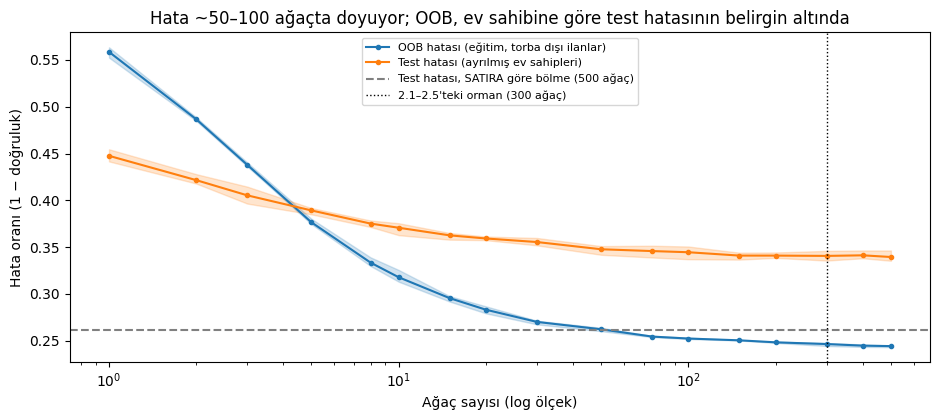

Grafik: çizgiler 3 bölmenin ortalaması, bantlar en küçük–en büyük. 10 ağacın altındaki OOB değerleri güvenilmez: ilanların bir kısmı hiçbir ağacın torba dışında kalmadığı için tahminsiz kalıyor.


In [38]:
# =====================================================================
# E1.2 Doyum eğrisi: rastgele ormanda ağaç sayısı 1 → 500; OOB ve test hatası
# Model 2.5'te seçilen orman (aynı ayarlar: yaprak ≥ 2, aynı ön işleme). warm_start ile her adımda YALNIZ yeni ağaçlar eklenir.
# Hata = 1 − doğruluk (sınıflar dengeli olduğu için doğruluk makro F1'e çok yakın; makro F1 de yanında raporlanıyor).
# Eğri tek bir bölmeye bağlı kalmasın diye üç farklı ÇD tekrarının ilk katı kullanılıyor (bant = en küçük – en büyük).
# =====================================================================
rf_sablon = MODELLER_21[SECILEN]
AGAC_SAYILARI = [1, 2, 3, 5, 8, 10, 15, 20, 30, 50, 75, 100, 150, 200, 300, 400, 500]
BOLMELER_E12 = {"tekrar 1": CV_GRUP[0], "tekrar 2": CV_GRUP[5], "tekrar 3": CV_GRUP[10]}

def doyum_egrisi(eg, te, agac_sayilari=AGAC_SAYILARI):
    on = clone(rf_sablon.named_steps["on"]).fit(X.iloc[eg], y[eg])
    Xe, Xt = on.transform(X.iloc[eg]), on.transform(X.iloc[te])
    orman = clone(rf_sablon.named_steps["model"]).set_params(warm_start=True, oob_score=True)
    satir = []
    for k in agac_sayilari:
        with warnings.catch_warnings():            # az ağaçta bazı ilanlar hiç "torba dışı" kalmaz; sklearn uyarır
            warnings.simplefilter("ignore")
            orman.set_params(n_estimators=k).fit(Xe, y[eg])
        tahmin = orman.predict(Xt)
        satir.append({"agac": k, "oob_hata": 1 - orman.oob_score_, "test_hata": 1 - accuracy_score(y[te], tahmin),
                      "test_f1": f1_score(y[te], tahmin, average="macro")})
    oob_f1 = f1_score(y[eg], orman.oob_decision_function_.argmax(1), average="macro")   # 500 ağaçta her ilanın OOB tahmini var
    return pd.DataFrame(satir), oob_f1

doyum, oob_f1 = [], {}
for ad, (eg, te) in BOLMELER_E12.items():
    d, oob_f1[ad] = doyum_egrisi(eg, te)
    doyum.append(d.assign(bolme=ad))
doyum = pd.concat(doyum)
ozet_e12 = doyum.groupby("agac")[["oob_hata", "test_hata", "test_f1"]].agg(["mean", "min", "max"])
display(ozet_e12.xs("mean", axis=1, level=1).T.round(4))

# Kontrol: OOB ev sahibini bilmez (torba dışı kalan İLANDIR, ev sahibi değil). Aynı ormanı SATIRA göre bölmede kuruyoruz:
# satıra göre test hatası OOB'ye yaklaşıyorsa, OOB–test farkının kaynağı ev sahibi bilgisinin sızmasıdır (1.5 ve 2.3 ile aynı olgu).
d_satir, oob_f1_satir = doyum_egrisi(*CV_SATIR[0], agac_sayilari=[500])
son = doyum[doyum["agac"] == 500]
print(f"500 ağaç · EV SAHİBİNE göre bölme (3 bölme ort.): OOB hata {son['oob_hata'].mean():.4f} | TEST hata {son['test_hata'].mean():.4f} "
      f"± {son['test_hata'].std():.4f} | OOB makro F1 {np.mean(list(oob_f1.values())):.3f} · test makro F1 {son['test_f1'].mean():.3f}")
print(f"500 ağaç · SATIRA göre bölme               : OOB hata {d_satir['oob_hata'].iloc[0]:.4f} | TEST hata {d_satir['test_hata'].iloc[0]:.4f}")

# Doyum noktası: ortalama test hatasının 500 ağaçtakine 0,005 ve 0,002 kadar yaklaştığı ilk ağaç sayısı
th = ozet_e12[("test_hata", "mean")]
for tol in [0.005, 0.002]:
    print(f"Test hatası 500 ağaçtakinin ±{tol} içine ilk kez {int(th.index[(th - th.loc[500]).abs() <= tol][0])} ağaçta giriyor")
print(f"Oran: ilk 50 ağaç hatayı {th.loc[1] - th.loc[50]:.3f} düşürüyor, sonraki 450 ağaç {th.loc[50] - th.loc[500]:.3f}")

fig, ax = plt.subplots(figsize=(9.5, 4.3))
for kol, ad, renk in [("oob_hata", "OOB hatası (eğitim, torba dışı ilanlar)", "tab:blue"),
                      ("test_hata", "Test hatası (ayrılmış ev sahipleri)", "tab:orange")]:
    ax.plot(ozet_e12.index, ozet_e12[(kol, "mean")], "o-", ms=3, color=renk, label=ad)
    ax.fill_between(ozet_e12.index, ozet_e12[(kol, "min")], ozet_e12[(kol, "max")], color=renk, alpha=.2)
ax.axhline(d_satir["test_hata"].iloc[0], color="grey", ls="--", label="Test hatası, SATIRA göre bölme (500 ağaç)")
ax.axvline(300, color="black", ls=":", lw=1, label="2.1–2.5'teki orman (300 ağaç)")
ax.set_xscale("log"); ax.set_xlabel("Ağaç sayısı (log ölçek)"); ax.set_ylabel("Hata oranı (1 − doğruluk)")
ax.set_title("Hata ~50–100 ağaçta doyuyor; OOB, ev sahibine göre test hatasının belirgin altında"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Grafik: çizgiler 3 bölmenin ortalaması, bantlar en küçük–en büyük. 10 ağacın altındaki OOB değerleri güvenilmez: "
      "ilanların bir kısmı hiçbir ağacın torba dışında kalmadığı için tahminsiz kalıyor.")

**Yorum**

**Ne bulduk.** Test hatası ilk ağaçlarla hızla düşüyor ve sonra düzleşiyor:

| Ağaç sayısı | Test hatası |
|---|---|
| 1 | 0,448 |
| 10 | 0,371 |
| 50 | 0,348 |
| 150 | 0,341 |
| 500 | 0,340 ± 0,006 |

İlk 50 ağaç hatayı 0,100 düşürüyor, sonraki 450 ağaç yalnız 0,008. Test hatası 150 ağaçta 500 ağaçtaki değerin hem ±0,005 hem ±0,002 içine giriyor. Makro F1 aynı resmi veriyor: 1 ağaçta 0,551, 75 ağaçta 0,653, 500 ağaçta 0,659. Ağaç eklemek hatayı **artırmıyor**; Breiman'ın (2001) gösterdiği gibi rastgele orman ağaç sayısıyla aşırı uymaz, yalnız doyar.

**OOB hatası testten belirgin biçimde iyimser.** OOB eğrisi de doyuyor ama çok daha aşağıda: 500 ağaçta OOB hatası **0,244**, ev sahibine göre test hatası **0,340**. Fark yaklaşık 0,10 puan; makro F1'de 0,754'e karşı 0,659. Nedeni OOB'nin torba dışında kalan **ilana** bakması, ev sahibine değil: bir ilanı tahmin eden ağaçlar, aynı ev sahibinin benzer ilanlarıyla eğitilmiş olabilir. Kontrolü bunu doğruluyor: aynı orman **satıra göre** bölündüğünde test hatası 0,262 çıkıyor, yani OOB'ye (0,255) çok yakın. OOB bu veride satıra göre çapraz doğrulama gibi davranıyor ve 1.5'teki örnek sızıntısını taşıyor. Bu, 2.3 (E)'de 100 ağaçla bulunan farkla da tutarlı (0,742'ye karşı 0,658). Sonuç: OOB skoru bu veride başarı raporu ya da model seçimi için **kullanılamaz**. Yalnız eğrinin şekli, yani ağaç sayısının doyup doymadığı için kullanılabilir: test eğrisi yaklaşık 150 ağaçta düzleşiyor, OOB eğrisi de aynı bölgede yavaşlıyor ama 500 ağaca kadar hafifçe inmeye devam ediyor (150 ağaçta 0,251, 500 ağaçta 0,244). 1–5 ağaçta OOB'nin testten kötü görünmesi bir ölçüm etkisidir: tek ağaçta ilanların yaklaşık %37'si torba dışında kalır, kalan ilanların hiç OOB tahmini olmaz ve hatalı sayılır. 10 ağacın altındaki OOB değerleri yorumlanmamalıdır.

**Ne anlama geliyor.** 2.1–2.5'te kullanılan 300 ağaç doyumun ötesinde: skoru değiştirmiyor, yalnız süreyi uzatıyor. Proje 2'de 150 ağaç aynı sonucu yaklaşık iki kat daha hızlı verir. Seçilen modeli değiştirmeye gerek yok; bu yalnız bir maliyet bulgusu. Ormanın tek ağaca üstünlüğü varyansı azaltmasından geliyor: ormandaki tek bir ağaç (bootstrap ve rastgele öznitelik alt kümesiyle) 0,448 hata yapıyor ve makro F1'i 0,551; budanmış en iyi tek ağaç bile makro F1'de 0,621'de kalıyor (E1.1); ağaçların oyları ortalandıkça hata 0,340'a iniyor, makro F1 0,659'a çıkıyor.

**Neyi söyleyemeyiz.** Eğri üç bölmenin ortalamasıdır ve bant dardır (±0,006), ama doyum noktası ayarlara bağlıdır: farklı `max_features` ya da `min_samples_leaf` ile daha erken ya da geç doyabilir. 150 ile 500 ağaç arasındaki küçük iniş çıkışlar (0,341 ↔ 0,340) gürültüdür; "500 ağaç en iyisi" gibi bir sonuç çıkarılamaz.

### E1.3 Öznitelik önemi
Rastgele bir sütun ekleyin; Gini önemi ve permütasyon önemi sıralamalarını karşılaştırın.

Orman (rastgele sütunlarla) · TEST makro F1 = 0.657


,gini,perm_test,perm_test_std,perm_egitim,sıra_gini,sıra_perm_test,sıra_perm_egitim,fark (perm − gini sırası)
kapasite,0.0702,0.0232,0.0042,0.0864,1,2,1,1
lisans_durumu,0.0644,0.0193,0.0034,0.0668,2,3,2,1
boylam,0.0587,0.0087,0.0032,0.0463,3,6,7,3
olanak_sayisi,0.0581,0.0020,0.0030,0.0550,4,13,4,9
log_min_gece,0.0571,0.0326,0.0032,0.0578,5,1,3,-4
enlem,0.0569,0.0045,0.0014,0.0376,6,9,12,3
log_ev_sahibi_ilan,0.0515,-0.0013,0.0015,0.0419,7,22,10,15
ev_sahipligi_yil,0.0512,-0.0003,0.0021,0.0425,8,19,9,11
yatak_odasi,0.0501,0.0173,0.0030,0.0526,9,4,5,-5
log_aciklama_uzunlugu,0.0482,-0.0014,0.0015,0.0386,10,23,11,13


rastgele_sayi   → Gini sırası 13/26 | eğitimde permütasyon 20/26 | TESTTE permütasyon 24/26 (makro F1 düşüşü -0.0019 ± 0.0016)
rastgele_ikili  → Gini sırası 24/26 | eğitimde permütasyon 24/26 | TESTTE permütasyon 25/26 (makro F1 düşüşü -0.0026 ± 0.0008)
Gini'de rastgele_sayi'nın ALTINDA kalan gerçek öznitelikler: ['puan_konum', 'aylik_yorum', 'oda_tipi', 'puan_temizlik', 'yatak', 'puan_genel', 'log_yorum_sayisi', 'banyo_sayisi', 'banyo_tipi', 'superhost', 'profil_fotografi', 'kimlik_dogrulandi']
Testte permütasyon önemi rastgele_sayi'dan ayırt edilemeyen (≤ rastgele + 2 std) gerçek öznitelikler: ['log_ev_sahibi_ilan', 'ev_sahipligi_yil', 'log_aciklama_uzunlugu', 'puan_temizlik', 'puan_genel', 'log_yorum_sayisi', 'banyo_tipi', 'superhost', 'profil_fotografi', 'kimlik_dogrulandi']


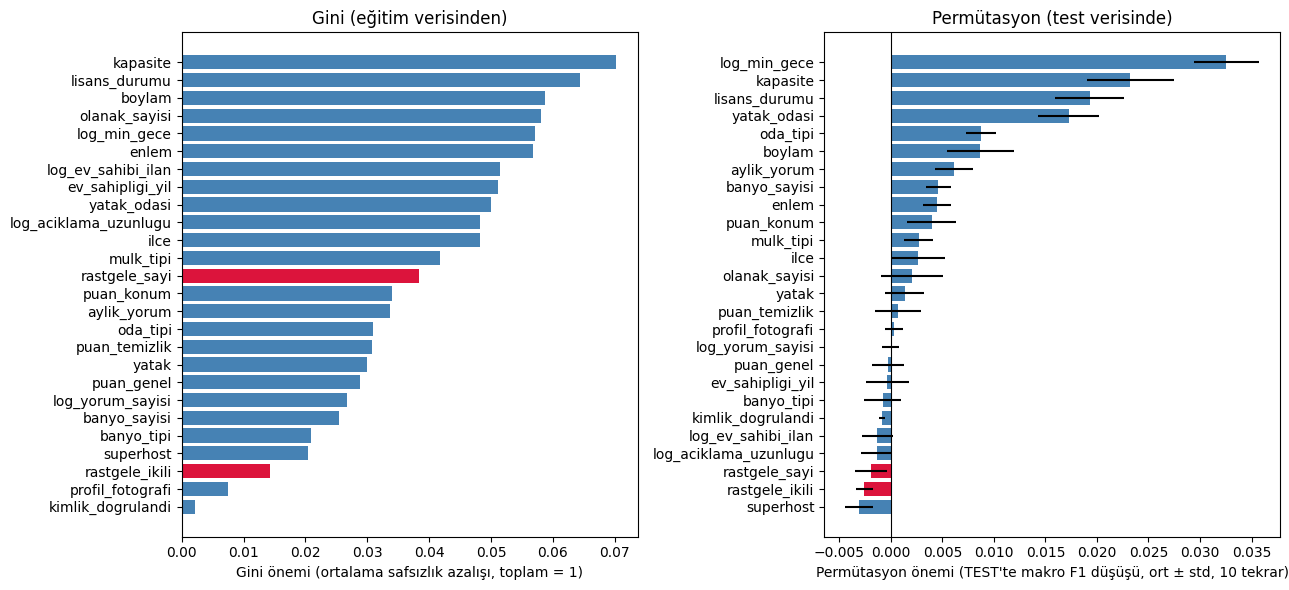

Grafik: kırmızı çubuklar rastgele sütunlar. Solda Gini önemi (eğitimde öğrenilen bölmelerden), sağda permütasyon önemi (görülmemiş ev sahiplerinde, hata çubuğu ± std).


In [39]:
from sklearn.inspection import permutation_importance
# =====================================================================
# E1.3 Öznitelik önemi: tamamen rastgele sütunlar Gini ve permütasyon öneminde kaçıncı çıkıyor?
#   rastgele_sayi : sürekli, her ilanda farklı değer (yüksek kardinalite)  ← yönergenin istediği sütun
#   rastgele_ikili: iki değerli (düşük kardinalite)                          ← karşılaştırma için
# İkisinin de hedefle hiçbir ilişkisi yoktur: doğru bir önem ölçüsü ikisine de ≈ 0 vermelidir.
# =====================================================================
rng = np.random.default_rng(SEED)
X_r = X.copy()
X_r["rastgele_sayi"] = rng.normal(size=len(X_r))
X_r["rastgele_ikili"] = rng.integers(0, 2, size=len(X_r)).astype(str)
SAYISAL_R, KATEGORIK_R = SAYISAL + ["rastgele_sayi"], KATEGORIK + ["rastgele_ikili"]

rf_r = Pipeline([("on", on_isleme(kodlama="nadir", add_indicator=True, sayisal=SAYISAL_R, kategorik=KATEGORIK_R)),
                 ("model", clone(rf_sablon.named_steps["model"]))]).fit(X_r.iloc[EG], y[EG])
print(f"Orman (rastgele sütunlarla) · TEST makro F1 = {f1_score(y[TE], rf_r.predict(X_r.iloc[TE]), average='macro'):.3f}")

# (1) Gini önemi (MDI): eğitim sırasında her bölmenin Gini safsızlığını ne kadar azalttığının ağaçlar üzerinden ortalaması.
#     Bire-bir sütunları ve eksiklik göstergeleri ait oldukları ham özniteliğe toplanır; böylece permütasyon önemiyle
#     aynı düzeyde (24 + 2 öznitelik) karşılaştırılabilir.
KAYNAKLAR = sorted(KATEGORIK_R + [YUKSEK_KARD], key=len, reverse=True)
def kaynak_ad(ad):
    blok, ad = ad.split("__", 1)
    if blok == "sayisal":
        return ad.replace("missingindicator_", "")
    return next(k for k in KAYNAKLAR if ad.startswith(k + "_"))
gini = pd.Series(rf_r.named_steps["model"].feature_importances_,
                 index=[kaynak_ad(a) for a in rf_r.named_steps["on"].get_feature_names_out()]).groupby(level=0).sum()

# (2) Permütasyon önemi: bir sütunun değerleri karıştırılınca makro F1 ne kadar düşüyor?
#     TEST kısmında (asıl ölçü, 10 tekrar) ve karşılaştırma için EĞİTİM kısmında (3 tekrar).
with warnings.catch_warnings():                 # joblib'in zararsız "worker stopped" uyarısını gizle
    warnings.simplefilter("ignore", UserWarning)
    pi_te = permutation_importance(rf_r, X_r.iloc[TE], y[TE], scoring="f1_macro", n_repeats=10, random_state=SEED, n_jobs=-1)
    pi_eg = permutation_importance(rf_r, X_r.iloc[EG], y[EG], scoring="f1_macro", n_repeats=3, random_state=SEED, n_jobs=-1)

onem = pd.DataFrame({"gini": gini,
                     "perm_test": pd.Series(pi_te.importances_mean, index=X_r.columns),
                     "perm_test_std": pd.Series(pi_te.importances_std, index=X_r.columns),
                     "perm_egitim": pd.Series(pi_eg.importances_mean, index=X_r.columns)})
for k in ["gini", "perm_test", "perm_egitim"]:
    onem[f"sıra_{k}"] = onem[k].rank(ascending=False, method="min").astype(int)
onem["fark (perm − gini sırası)"] = onem["sıra_perm_test"] - onem["sıra_gini"]
onem = onem.sort_values("gini", ascending=False)
display(onem.round(4))

n_oz = len(onem)
for r in ["rastgele_sayi", "rastgele_ikili"]:
    print(f"{r:15s} → Gini sırası {onem.loc[r, 'sıra_gini']:2d}/{n_oz} | eğitimde permütasyon {onem.loc[r, 'sıra_perm_egitim']:2d}/{n_oz} | "
          f"TESTTE permütasyon {onem.loc[r, 'sıra_perm_test']:2d}/{n_oz} (makro F1 düşüşü {onem.loc[r, 'perm_test']:+.4f} ± {onem.loc[r, 'perm_test_std']:.4f})")
gercek = onem.index[~onem.index.str.startswith("rastgele")]
print("Gini'de rastgele_sayi'nın ALTINDA kalan gerçek öznitelikler:",
      [o for o in gercek if onem.loc[o, "gini"] < onem.loc["rastgele_sayi", "gini"]])
esik = onem.loc["rastgele_sayi", "perm_test"] + 2 * onem.loc["rastgele_sayi", "perm_test_std"]
print("Testte permütasyon önemi rastgele_sayi'dan ayırt edilemeyen (≤ rastgele + 2 std) gerçek öznitelikler:",
      [o for o in gercek if onem.loc[o, "perm_test"] <= esik])

fig, ax = plt.subplots(1, 2, figsize=(13, 6))
renk = lambda idx: ["crimson" if i.startswith("rastgele") else "steelblue" for i in idx]
ax[0].barh(onem.index, onem["gini"], color=renk(onem.index)); ax[0].invert_yaxis()
ax[0].set_xlabel("Gini önemi (ortalama safsızlık azalışı, toplam = 1)"); ax[0].set_title("Gini (eğitim verisinden)")
p = onem.sort_values("perm_test", ascending=False)
ax[1].barh(p.index, p["perm_test"], xerr=p["perm_test_std"], color=renk(p.index)); ax[1].invert_yaxis()
ax[1].axvline(0, color="black", lw=.8)
ax[1].set_xlabel("Permütasyon önemi (TEST'te makro F1 düşüşü, ort ± std, 10 tekrar)"); ax[1].set_title("Permütasyon (test verisinde)")
plt.tight_layout(); plt.show()
print("Grafik: kırmızı çubuklar rastgele sütunlar. Solda Gini önemi (eğitimde öğrenilen bölmelerden), "
      "sağda permütasyon önemi (görülmemiş ev sahiplerinde, hata çubuğu ± std).")

**Yorum**

**Ne bulduk.** Hedefle hiçbir ilişkisi olmayan `rastgele_sayi`, Gini öneminde **26 öznitelik arasında 13.** sırada. 12 gerçek özniteliğin önünde: aralarında `oda_tipi`, `banyo_sayisi`, `superhost` ve bütün yorum puanları var. Testteki permütasyon öneminde ise **24.** sırada; makro F1 düşüşü −0,0019 ± 0,0016, yani sıfırdan ayırt edilemiyor. İki değerli `rastgele_ikili` Gini'de de alt sıralarda (24.). Bu fark iki rastgele sütunun yalnız **kardinalitesinden** geliyor. Sürekli rastgele sütun her düğümde binlerce olası eşik sunar. Derin ağaçlar (yaprak ≥ 2) eğitim verisindeki gürültüye uyan bir eşiği hep bulur. Gini önemi bu "kazancı" eğitim verisinden ölçtüğü için ona önem yazar (Strobl vd., 2007). Permütasyon önemi ise görülmemiş ev sahipleri üzerinde ölçüldüğü için gürültüye uymak hiçbir şey kazandırmaz.

**Gerçek öznitelikler de aynı yanlılıktan etkileniyor.** Gini'de üstte olan sürekli ve çok değerli sütunlar testte düşüyor: `log_ev_sahibi_ilan` 7. sıradan 22.'ye, `ev_sahipligi_yil` 8.'den 19.'a, `olanak_sayisi` 4.'den 13.'e, `enlem` 6.'dan 9.'a. Az değerli öznitelikler ise yükseliyor: `oda_tipi` 16.'dan 5.'e, `banyo_sayisi` 21.'den 8.'e, `aylik_yorum` 15.'ten 7.'ye. En öğretici iki örnek `ev_sahipligi_yil` ve `log_ev_sahibi_ilan`. Eğitim verisinde permütasyonla da önemli görünüyorlar (9. ve 10. sıra), ama testte rastgele sütundan ayırt edilemiyorlar. İkisi de ev sahibine ait ve bir ev sahibinin bütün ilanlarında aynı; birlikte ev sahibinin bir "parmak izi" oluşturuyorlar. Orman bunları eğitimde ev sahibini tanımak için kullanıyor (1.5'teki ezber), görülmemiş ev sahiplerine ise bu bilgi taşınmıyor. Testte gerçekten önemli olanlar şunlar: `log_min_gece`, `kapasite`, `lisans_durumu`, `yatak_odasi`, `oda_tipi`, `boylam`. Bu liste 2.2'deki ağacın kökü ve ilk düzeyleriyle ve 3.3'teki en güçlü kurallarla örtüşüyor.

**Ne anlama geliyor.** Gini önemi "model eğitimde neye dayandı?" sorusunu cevaplar, "neye genellenebilir biçimde dayanıyor?" sorusunu değil. Rastgele bir sütunun ortalarda çıkması, Gini sıralamasının orta ve alt kısmının yorumlanamayacağını gösteriyor. Bu yüzden Proje 2'deki açıklamalar için permütasyon önemi kullanılmalı: test verisinde ve ev sahibine göre bölmede. Rastgele sütun bir taban çizgisi olarak da işe yarıyor: ondan ayırt edilemeyen öznitelikler (`log_ev_sahibi_ilan`, `ev_sahipligi_yil`, `log_aciklama_uzunlugu`, `puan_temizlik`, `puan_genel`, `log_yorum_sayisi`, `banyo_tipi`, `superhost`, `profil_fotografi`, `kimlik_dogrulandi`) yeni ev sahiplerinde modele bir şey katmıyor. Bu liste Ek paket 2'deki öznitelik seçimi için doğal bir başlangıç.

**Neyi söyleyemeyiz.** Permütasyon önemi birbiriyle ilişkili öznitelikleri küçümser. `log_yorum_sayisi` neredeyse 0 çıkıyor, çünkü `aylik_yorum` ve puanlar aynı bilgiyi büyük ölçüde taşıyor: biri karıştırılınca diğerleri telafi ediyor. "Yorum sayısı önemsiz" demek bu yüzden yanlış olur. Aynı durum kapasite–yatak odası–yatak ve enlem–boylam–ilçe üçlüleri için de geçerli. Hata çubukları yalnız 10 karıştırma tekrarının yayılımıdır; bölmenin belirsizliğini içermez, çünkü tek bir test bölmesi kullandık. Önemler nedensel değildir: bir özniteliğin karıştırılınca skoru düşürmesi, onun fiyatı belirlediği anlamına gelmez.

# Ek paket 2 · Öznitelik seçimi ve kararlılığı *(5 kişilik gruplar)*
**Makale:** Meinshausen ve Bühlmann (2010). Stability selection. *JRSS B*, 72(4).

**Okuma notu:** Meinshausen ve Bühlmann (2010), öznitelik seçiminin verideki küçük değişikliklere karşı ne kadar tutarlı olduğunu ele alır. Yazarlar seçimin verinin çok sayıda alt örnekleminde (her birinde verinin yarısı) tekrarlanmasını ve her öznitelik için bir seçilme olasılığı hesaplanmasını önerir. Bu olasılığı belirli bir eşiğin (0,6–0,9) üzerinde olan öznitelikler kararlı kabul edilir. Yöntemin katkısı, yanlış seçilen öznitelik sayısı için bir üst sınır vermesi ve sonucu tek bir ayar parametresine daha az bağımlı hâle getirmesidir.

### E2.1 Üç aile
Filtre, sarmalayıcı ve gömülü birer yöntem, hattın içinde.

In [40]:
# =====================================================================
# Ek paket 2 · ortak kurulum + E2.1 Üç aile: filtre, sarmalayıcı, gömülü
# Önkoşul: ortak hat (X, y, gruplar, CV_GRUP, on_isleme, degerlendir, tablo, SEED, KATEGORIK, YUKSEK_KARD),
#          2.1 (MODELLER_21, skorlar_21, tablo_21) ve 2.5 (SECILEN).
# - Son model üç yöntemde de 2.5'te Proje 2'ye aktarılan rastgele orman (2.1 ile aynı ayarlar).
# - Seçim adımı Pipeline'ın İÇİNDE: her katta yalnız eğitim verisiyle öğrenir (3. hafta, %88 deneyi).
# - Seçim, ön işlemeden çıkan sütunlar üzerinde yapılır (bire-bir sütunları ve eksiklik göstergeleri dahil).
# - Üç yöntem de aynı sayıda sütun (K) tutar; böylece farklar yalnız "hangi sütunlar" sorusundan gelir.
# - Bölmeler 2.1'dekilerin aynısı (CV_GRUP, ev sahibine göre 5 × 5): seçimsiz ormanla eşleştirilmiş karşılaştırma yapılabilir.
# =====================================================================
import time, warnings
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
warnings.filterwarnings("ignore", category=DeprecationWarning)   # Colab'ın jupyter_client uyarı selini kapat (çıktıyı boğuyordu)

RF_SON = MODELLER_21[SECILEN].named_steps["model"]          # 300 ağaç, yaprak ≥ 2
K = 30                                                       # tutulacak sütun sayısı (gerekçe: Varsayım defteri)

def secici(aile, k=K, n_jobs=-1):
    if aile == "filtre":        # her sütunu hedefle ilişkisine göre TEK TEK puanlar (ANOVA F); hızlı, etkileşimi görmez
        return SelectKBest(f_classif, k=k)
    if aile == "sarmalayici":   # modeli eğitip her turda sütunların %20'si kadarını atar, K kalana kadar tekrarlar
        return RFE(LogisticRegression(max_iter=3000, random_state=SEED), n_features_to_select=k, step=0.2)
    if aile == "gomulu":        # seçim modelin kendi eğitiminden gelir: ormanın Gini önemi en yüksek K sütun
        return SelectFromModel(RandomForestClassifier(n_estimators=100, min_samples_leaf=2, n_jobs=n_jobs,
                                                      random_state=SEED), max_features=k, threshold=-np.inf)
    raise ValueError(aile)

def secimli_hat(aile, k=K):
    return Pipeline([("on", on_isleme(kodlama="nadir", add_indicator=True)),
                     ("sec", secici(aile, k)),
                     ("model", clone(RF_SON))])

AILELER = {"filtre": "Filtre · SelectKBest (ANOVA F)",
           "sarmalayici": "Sarmalayıcı · RFE (lojistik regresyonla)",
           "gomulu": "Gömülü · orman Gini önemi"}

# Ön işlemeden kaç sütun çıkıyor? (yalnız sayı için; skor hesabında kullanılmıyor)
P_SUTUN = on_isleme(kodlama="nadir", add_indicator=True).fit(X, y).get_feature_names_out().size
print(f"Ön işleme sonrası {P_SUTUN} sütun → üç yöntem de {K} sütun tutuyor (%{100 * K / P_SUTUN:.0f})\n")

sonuc_e21, sure_e21 = [], {}
for aile, ad in AILELER.items():
    t0 = time.time()
    with warnings.catch_warnings():                  # joblib'in zararsız "worker stopped" uyarısını gizle
        warnings.simplefilter("ignore", UserWarning)
        sonuc_e21.append(degerlendir(secimli_hat(aile), X, ad=f"{ad} · {K} sütun"))
    sure_e21[aile] = time.time() - t0
# Seçimsiz orman: 2.1'deki 25 skor, AYNI bölmelerde. Yeniden çalıştırılmıyor.
sonuc_e21.append({"kurulum": f"Seçimsiz orman · {P_SUTUN} sütun (2.1)",
                  "f1_macro_ort": skorlar_21[SECILEN].mean(), "f1_macro_std": skorlar_21[SECILEN].std(),
                  "_skorlar": skorlar_21[SECILEN]})
tablo_e21 = tablo(sonuc_e21)
tablo_e21["süre (sn, 25 bölme)"] = [sure_e21[a] for a in AILELER] + [tablo_21.loc[SECILEN, "sure_sn"]]
display(tablo_e21.round(3))

# ---- Üç yöntem AYNI sütunları mı seçiyor? CV_GRUP[0]'ın eğitim kısmında bir kez seçim yapıp karşılaştırıyoruz.
HAM_ADLAR = sorted(KATEGORIK + [YUKSEK_KARD], key=len, reverse=True)
def ham_ad(sutun):
    """Ön işleme sütun adını ait olduğu ham özniteliğe çevirir: 'kategorik__ilce_Fatih' → 'ilce'."""
    blok, ad = sutun.split("__", 1)
    if blok == "sayisal":
        return ad.replace("missingindicator_", "")
    return next(k for k in HAM_ADLAR if ad.startswith(k + "_"))

def secim_yap(aile, idx, X_=None, on_ayar=None, k=K, n_jobs=-1):
    """idx satırlarında ön işleme + seçim (hepsi yalnız bu satırlardan öğrenir); seçilen sütun adlarını döndürür."""
    X_ = X if X_ is None else X_
    on = on_isleme(kodlama="nadir", add_indicator=True, **(on_ayar or {})).fit(X_.iloc[idx], y[idx])
    with warnings.catch_warnings():              # paralel işçilerde de uyarıları sustur (sonucu etkilemez)
        warnings.simplefilter("ignore")
        s = secici(aile, k, n_jobs=n_jobs).fit(on.transform(X_.iloc[idx]), y[idx])
    return on.get_feature_names_out()[s.get_support()]

EG, TE = CV_GRUP[0]
secilen_e21 = {aile: set(secim_yap(aile, EG)) for aile in AILELER}
ham_e21 = {aile: {ham_ad(s) for s in secilen_e21[aile]} for aile in AILELER}

print("\nCV_GRUP[0] eğitim kısmında seçilen sütunların ortaklığı (Jaccard = ortak / birleşim):")
for a, b in [("filtre", "sarmalayici"), ("filtre", "gomulu"), ("sarmalayici", "gomulu")]:
    j_s = len(secilen_e21[a] & secilen_e21[b]) / len(secilen_e21[a] | secilen_e21[b])
    j_h = len(ham_e21[a] & ham_e21[b]) / len(ham_e21[a] | ham_e21[b])
    print(f"  {a:<12s} – {b:<12s}  sütun düzeyinde {j_s:.2f} · ham öznitelik düzeyinde {j_h:.2f}")
uc_yontem = ham_e21["filtre"] & ham_e21["sarmalayici"] & ham_e21["gomulu"]
print(f"\nÜç yöntemin de seçtiği ham öznitelikler ({len(uc_yontem)}): {sorted(uc_yontem)}")
print(f"Hiçbir yöntemin seçmediği ham öznitelikler: {sorted(set(X.columns) - set().union(*ham_e21.values()))}")

Ön işleme sonrası 103 sütun → üç yöntem de 30 sütun tutuyor (%29)

Filtre · SelectKBest (ANOVA F) · 30 sütun               f1_macro = 0.639 ± 0.014
Sarmalayıcı · RFE (lojistik regresyonla) · 30 sütun     f1_macro = 0.592 ± 0.019
Gömülü · orman Gini önemi · 30 sütun                    f1_macro = 0.663 ± 0.015


,f1_macro_ort,f1_macro_std,"süre (sn, 25 bölme)"
kurulum,,,
Filtre · SelectKBest (ANOVA F) · 30 sütun,0.639,0.014,740.639
Sarmalayıcı · RFE (lojistik regresyonla) · 30 sütun,0.592,0.019,321.135
Gömülü · orman Gini önemi · 30 sütun,0.663,0.015,675.279
Seçimsiz orman · 103 sütun (2.1),0.663,0.014,496.454



CV_GRUP[0] eğitim kısmında seçilen sütunların ortaklığı (Jaccard = ortak / birleşim):
  filtre       – sarmalayici   sütun düzeyinde 0.13 · ham öznitelik düzeyinde 0.35
  filtre       – gomulu        sütun düzeyinde 0.62 · ham öznitelik düzeyinde 0.83
  sarmalayici  – gomulu        sütun düzeyinde 0.11 · ham öznitelik düzeyinde 0.32

Üç yöntemin de seçtiği ham öznitelikler (7): ['banyo_tipi', 'ilce', 'kapasite', 'log_min_gece', 'mulk_tipi', 'oda_tipi', 'superhost']
Hiçbir yöntemin seçmediği ham öznitelikler: ['kimlik_dogrulandi']


**Yorum**

Üç yöntemde de ön işleme sonrasındaki 103 sütundan 30'u tutulmuş ve son model olarak 2.5'te seçilen rastgele orman kullanılmıştır. Gömülü yöntem 0,663 ± 0,015 makro F1 ile seçimsiz ormanla (0,663 ± 0,014) aynı düzeyde kalmıştır. Filtre yönteminde başarım 0,639 ± 0,014'e, sarmalayıcı yöntemde ise 0,592 ± 0,019'a düşmüştür.

Gömülü yöntem seçimi ormanın kendi önem ölçüsüne göre yaptığından, atılan sütunlar ormanın zaten az kullandığı sütunlardır. Filtre yöntemi her sütunu ayrı ayrı ve doğrusal bir ilişki üzerinden puanlar. Bu nedenle fiyatla doğrusal olmayan bir ilişkisi olan konum bilgisini (enlem ve boylam) seçmemiştir (bkz. E2.2). Sarmalayıcı yöntem ise lojistik regresyon katsayılarına dayandığı için çoğunlukla ilçe ve mülk tipine ait bire-bir sütunları tutmuş, sayısal sütunların çoğunu dışarıda bırakmıştır. Doğrusal bir modelin işine yarayan sütunlar ormanın işine yarayanlarla aynı olmadığından en büyük kayıp bu yöntemde görülmüştür.

Seçilen sütunlar karşılaştırıldığında filtre ile gömülü yöntemin büyük ölçüde örtüştüğü (ham öznitelik düzeyinde Jaccard benzerliği 0,83), sarmalayıcı yöntemin ise diğer ikisinden ayrıştığı görülmüştür (0,35 ve 0,32). Üç yöntemin de seçtiği öznitelikler kapasite, en az gece sayısı, oda tipi, mülk tipi, ilçe, banyo tipi ve süper ev sahibi durumudur.

Sonuçlar tek bir K değerine (30) dayanmaktadır ve K'nin etkisi yalnızca gömülü yöntem için incelenmiştir (E2.3). Sarmalayıcı yöntemde iç model olarak süre nedeniyle lojistik regresyon kullanıldığından, ormanla kurulan bir sarmalayıcının farklı bir sonuç vermesi olasıdır.

### E2.2 Kararlılık
100 farklı %70'lik alt örneklemde seçimi tekrarlayın; seçilme oranlarını çizin.

100 alt örneklem · ev sahiplerinin %70'i · ilanların %69.8'i (en az %66.4, en çok %72.6)
Süre: 14.6 dk


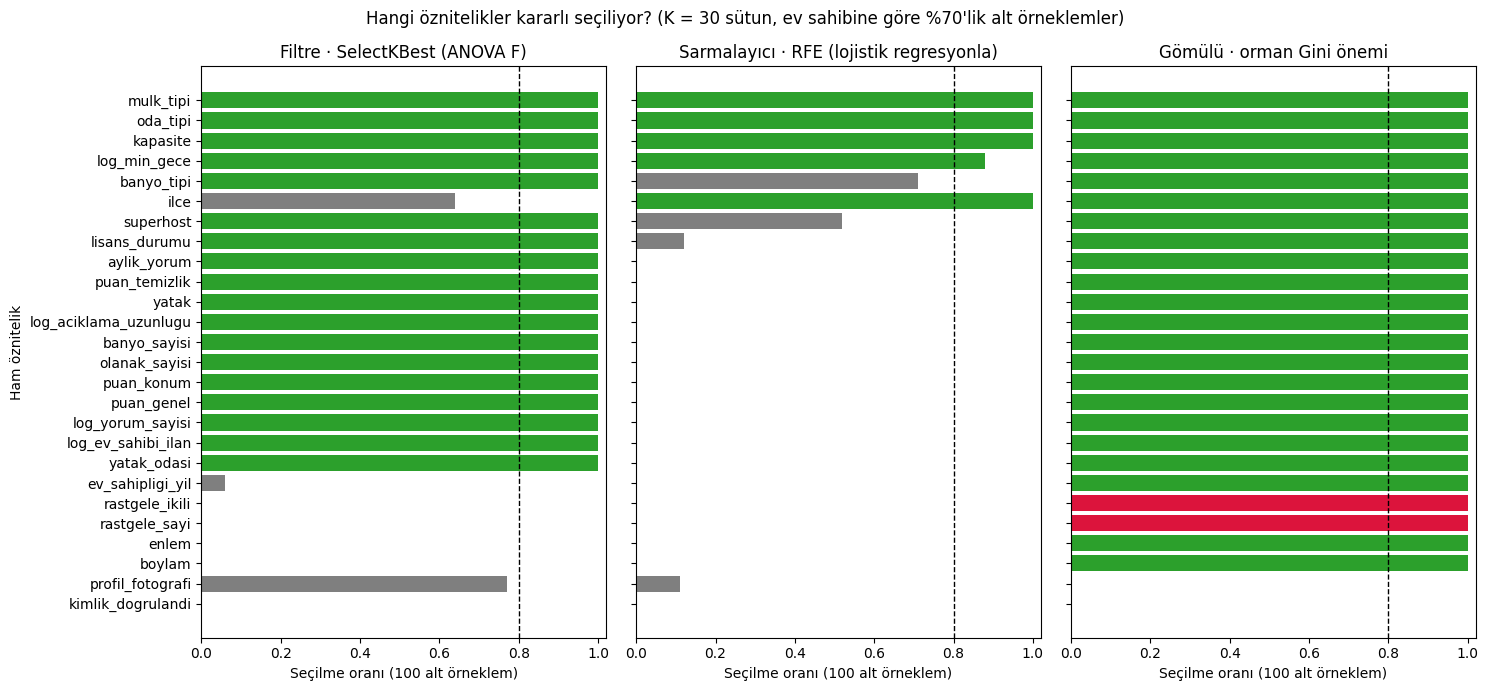

Grafik: çubuk = özniteliğin en az bir sütununun seçildiği alt örneklem oranı. Yeşil ≥ %80 (kararlı), gri altında, kırmızı rastgele kontrol sütunları; kesikli çizgi %80 eşiği.


,kararlı (≥ %80),hiç seçilmeyen,rastgele_sayi oranı,rastgele_ikili oranı,kararlı ama rastgeleden ayırt edilemeyen,kararlı sütun sayısı (sütun düzeyi)
yöntem,,,,,,
Filtre · SelectKBest (ANOVA F),18,3,0.0,0.0,0,27
Sarmalayıcı · RFE (lojistik regresyonla),5,15,0.0,0.0,0,12
Gömülü · orman Gini önemi,22,2,1.0,1.0,22,30


,Filtre · SelectKBest (ANOVA F),Sarmalayıcı · RFE (lojistik regresyonla),Gömülü · orman Gini önemi,sütun sayısı
kapasite,1.00,1.00,1.0,1
yatak_odasi,1.00,0.00,1.0,1
yatak,1.00,0.00,1.0,1
banyo_sayisi,1.00,0.00,1.0,1
enlem,0.00,0.00,1.0,1
boylam,0.00,0.00,1.0,1
log_min_gece,1.00,0.88,1.0,1
olanak_sayisi,1.00,0.00,1.0,1
log_aciklama_uzunlugu,1.00,0.00,1.0,1
oda_tipi,1.00,1.00,1.0,4


Yanlış seçim sınırı: q = 30, p ≈ 94, π = 0.8 → E[V] ≤ 16.0 sütun


In [41]:
# =====================================================================
# E2.2 Kararlılık: seçimi 100 farklı %70'lik alt örneklemde tekrarlamak (Meinshausen ve Bühlmann, 2010)
# Önkoşul: E2.1 hücresi (secici, secim_yap, ham_ad, AILELER, K).
# - Alt örneklemler EV SAHİBİNE GÖRE çekilir: bir ev sahibinin ya bütün ilanları alınır ya hiçbiri (1.5'teki ezber yüzünden).
# - KONTROL: E1.3'teki iki rastgele sütun burada da var. Hedefle ilgisi olmayan bir sütunun seçilme oranı
#   "gürültü tabanı"dır: onu geçemeyen bir özniteliğe kararlı denemez.
# - Süre: 100 alt örneklem × 3 yöntem; Colab'ın 2 çekirdeğinde yaklaşık 25–40 dakika (en pahalısı RFE).
# =====================================================================
from collections import Counter
from joblib import Parallel, delayed
from sklearn.model_selection import GroupShuffleSplit
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)   # Colab'ın jupyter_client uyarı selini kapat (çıktıyı boğuyordu)

N_ALT, ESIK = 100, 0.8

# Kontrol sütunları: E1.3 ile aynı tohum ve aynı tanım → aynı değerler
rng = np.random.default_rng(SEED)
X_k = X.copy()
X_k["rastgele_sayi"] = rng.normal(size=len(X_k))
X_k["rastgele_ikili"] = rng.integers(0, 2, size=len(X_k)).astype(str)
ON_AYAR_K = {"sayisal": SAYISAL + ["rastgele_sayi"], "kategorik": KATEGORIK + ["rastgele_ikili"]}
HAM_ADLAR = sorted(KATEGORIK + ["rastgele_ikili", YUKSEK_KARD], key=len, reverse=True)   # ham_ad() bunu kullanır

# GroupShuffleSplit'te train_size ev sahiplerinin oranıdır; ilan oranı ev sahiplerinin ilan sayısına göre biraz oynar.
gss = GroupShuffleSplit(n_splits=N_ALT, train_size=0.7, random_state=SEED)
alt_ornekler = [tr for tr, _ in gss.split(X_k, y, gruplar)]
oran = np.array([len(a) / len(y) for a in alt_ornekler])
print(f"{N_ALT} alt örneklem · ev sahiplerinin %70'i · ilanların %{100 * oran.mean():.1f}'i "
      f"(en az %{100 * oran.min():.1f}, en çok %{100 * oran.max():.1f})")

def bir_alt_ornek(idx):
    # Paralel çalıştığı için ormanın kendi paralelliği kapalı (n_jobs=1); sonuç değişmez, yalnız hız.
    return {aile: secim_yap(aile, idx, X_=X_k, on_ayar=ON_AYAR_K, n_jobs=1) for aile in AILELER}

t0 = time.time()
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    secimler = Parallel(n_jobs=-1)(delayed(bir_alt_ornek)(idx) for idx in alt_ornekler)
print(f"Süre: {(time.time() - t0) / 60:.1f} dk")

# Seçilme oranı: sütun düzeyinde ve ham öznitelik düzeyinde (bir sütunu seçildiyse öznitelik seçilmiş sayılır)
oran_sutun = pd.DataFrame({AILELER[a]: pd.Series(Counter(s for r in secimler for s in r[a])) / N_ALT for a in AILELER}).fillna(0)
oran_ham = pd.DataFrame({AILELER[a]: pd.Series(Counter(h for r in secimler for h in {ham_ad(s) for s in r[a]})) / N_ALT
                         for a in AILELER}).reindex(list(X_k.columns)).fillna(0)
oran_ham["sütun sayısı"] = pd.Series(Counter(ham_ad(s) for s in oran_sutun.index)).reindex(oran_ham.index).fillna(0).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(15, 7), sharey=True)
sira = oran_ham[list(AILELER.values())].mean(1).sort_values().index
for ax, ad in zip(axes, AILELER.values()):
    renk = ["crimson" if o.startswith("rastgele") else ("tab:green" if oran_ham.loc[o, ad] >= ESIK else "tab:gray") for o in sira]
    ax.barh(sira, oran_ham.loc[sira, ad], color=renk)
    ax.axvline(ESIK, color="black", ls="--", lw=1)
    ax.set(xlim=(0, 1.02), xlabel=f"Seçilme oranı ({N_ALT} alt örneklem)", title=ad)
axes[0].set_ylabel("Ham öznitelik")
plt.suptitle(f"Hangi öznitelikler kararlı seçiliyor? (K = {K} sütun, ev sahibine göre %70'lik alt örneklemler)")
plt.tight_layout(); plt.show()
print(f"Grafik: çubuk = özniteliğin en az bir sütununun seçildiği alt örneklem oranı. Yeşil ≥ %{100 * ESIK:.0f} (kararlı), "
      "gri altında, kırmızı rastgele kontrol sütunları; kesikli çizgi %80 eşiği.")

# Özet tablo: her yöntem için kararlı, gürültü tabanının altında kalan ve kontrol sütunlarının durumu
ozet_e22 = []
for a, ad in AILELER.items():
    s = oran_ham[ad].drop(["rastgele_sayi", "rastgele_ikili"])
    taban = oran_ham.loc[["rastgele_sayi", "rastgele_ikili"], ad].max()
    ozet_e22.append({"yöntem": ad,
                     f"kararlı (≥ %{100 * ESIK:.0f})": int((s >= ESIK).sum()),
                     "hiç seçilmeyen": int((s == 0).sum()),
                     "rastgele_sayi oranı": oran_ham.loc["rastgele_sayi", ad],
                     "rastgele_ikili oranı": oran_ham.loc["rastgele_ikili", ad],
                     "kararlı ama rastgeleden ayırt edilemeyen": int(((s >= ESIK) & (s <= taban)).sum()),
                     "kararlı sütun sayısı (sütun düzeyi)": int((oran_sutun[ad] >= ESIK).sum())})
display(pd.DataFrame(ozet_e22).set_index("yöntem").round(2))
display(oran_ham.sort_values(AILELER["gomulu"], ascending=False).round(2))

# Meinshausen ve Bühlmann'ın yanlış seçim sınırı: E[V] ≤ q² / ((2·π − 1) · p)
# (q = her seçimde tutulan sütun, p = toplam sütun, π = eşik). Sınır n/2'lik alt örneklemler ve
# "değiştirilebilirlik" varsayımı için türetildi; burada yalnız büyüklük fikri vermesi için hesaplanıyor.
p_k = oran_sutun.shape[0]
print(f"Yanlış seçim sınırı: q = {K}, p ≈ {p_k}, π = {ESIK} → E[V] ≤ {K ** 2 / ((2 * ESIK - 1) * p_k):.1f} sütun")

**Yorum**

Seçim, ev sahiplerine göre çekilen 100 alt örneklemde tekrarlanmıştır; her alt örneklem ilanların ortalama %69,8'ini içermektedir. %80 eşiğini geçen öznitelik sayısı filtre yönteminde 18, sarmalayıcı yöntemde 5, gömülü yöntemde 22'dir.

Analizin en dikkat çekici sonucu kontrol sütunlarında görülmüştür. Hedefle hiçbir ilişkisi olmayan iki rastgele sütun, filtre ve sarmalayıcı yöntemde hiç seçilmemiş, gömülü yöntemde ise 100 alt örneklemin tamamında seçilmiştir. Gömülü yöntemin dayandığı Gini önemi, E1.3'te de gösterildiği gibi gürültü sütunlarına önem atamaktadır ve bu yanlılık her alt örneklemde tekrarlanmaktadır. Dolayısıyla yüksek bir seçilme oranı tek başına bir özniteliğin önemli olduğunu göstermez. Gömülü yöntem neredeyse bütün öznitelikleri her seferinde seçtiği için kararlılık sonuçları bu yöntemde ayırt edici değildir.

Kontrol sütunlarını seçmeyen filtre ve sarmalayıcı yöntemler esas alındığında, üç yöntemde de kararlı bulunan öznitelikler kapasite, en az gece sayısı, oda tipi ve mülk tipidir. Bunlardan en az gece sayısı, kapasite ve oda tipi E1.3'teki permütasyon öneminde de öne çıkmıştır. Kimlik doğrulama hiçbir yöntemde seçilmemiş, profil fotoğrafı ise yalnızca filtre yönteminde %77 oranına ulaşmıştır. E1.3'te de rastgele sütundan ayırt edilemeyen bu iki öznitelik gürültü olarak değerlendirilmiştir.

Bir öznitelik, sütunlarından biri seçildiğinde seçilmiş sayıldığı için ilçe ve mülk tipi gibi çok sayıda sütuna sahip özniteliklerin seçilmesi kolaylaşmaktadır. Makalede önerilen yanlış seçim sınırı defterde E[V] ≤ 16,0 olarak hesaplanmıştır. Bu değer seçilen 30 sütunun yaklaşık yarısının yanlış olabileceğine izin verdiğinden anlamlı bir güvence sağlamamaktadır. Ayrıca bu sınır verinin yarısıyla oluşturulan alt örneklemler için türetilmiştir; bu çalışmada ise %70'lik alt örneklemler kullanılmıştır. Alt örneklemler aynı veriden çekildiği için birbirinden bağımsız değildir; bu nedenle seçilme oranları bağımsız tekrarlar gibi yorumlanmamalıdır.

### E2.3 Seçimin katkısı
Seçimli ve seçimsiz hattın dürüst karşılaştırması.

Gömülü · orman Gini önemi · 15 sütun                    f1_macro = 0.652 ± 0.015
Gömülü · orman Gini önemi · 60 sütun                    f1_macro = 0.665 ± 0.014


,fark ort,fark std,seçimlinin önde olduğu bölme,p · düzeltilmiş t (Nadeau–Bengio)
seçimli − seçimsiz,,,,
Filtre · SelectKBest (ANOVA F) · K = 30,-0.0242,0.0065,0 / 25,0.0000
Sarmalayıcı · RFE (lojistik regresyonla) · K = 30,-0.0714,0.0172,0 / 25,0.0000
Gömülü · orman Gini önemi · K = 30,-0.0008,0.0048,10 / 25,0.7637
Gömülü · orman Gini önemi · K = 15,-0.0115,0.0090,2 / 25,0.0292
Gömülü · orman Gini önemi · K = 60,0.0020,0.0029,20 / 25,0.2290


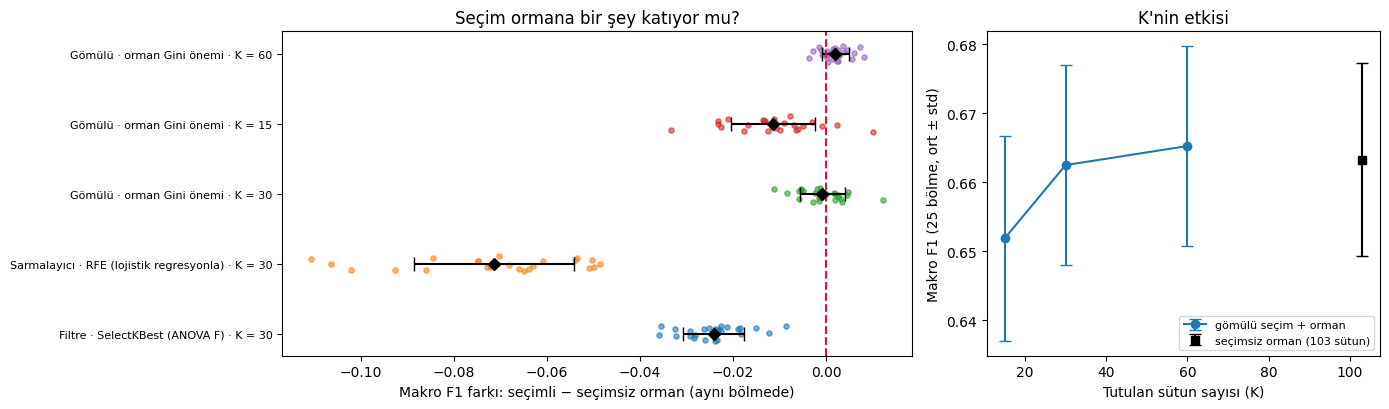

Grafik (sol): her nokta bir bölmedeki fark, siyah elmas ortalama ± std; kırmızı çizgi 'fark yok'. Grafik (sağ): tutulan sütun sayısına göre makro F1; siyah kare seçimsiz orman.


In [42]:
# =====================================================================
# E2.3 Seçimin katkısı: seçimli ve seçimsiz ormanın dürüst karşılaştırması
# Önkoşul: E2.1 (sonuc_e21, secimli_hat, AILELER, K, P_SUTUN) ve 2.4 (t_duzeltilmis).
# - Bütün hatlar AYNI 25 bölmede (CV_GRUP) ölçüldü → farklar eşleştirilmiş (aynı bölmede seçimli − seçimsiz).
# - 25 bölme bağımsız değil: anlamlılık için 2.4'teki Nadeau–Bengio düzeltmeli t testi kullanılıyor.
# - K'nin etkisi: gömülü yöntem (ormanın kendi önemi) için K = 15 ve K = 60 de deneniyor (yaklaşık 15 dk).
# - DİKKAT: E2.2'deki "kararlı öznitelikleri" seçip ormanı onlarla yeniden ölçmek SIZINTI olurdu, çünkü
#   o liste bütün veriden (test katları dahil) çıkarıldı. Bu yüzden burada yapılmıyor.
# =====================================================================
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)   # Colab'ın jupyter_client uyarı selini kapat (çıktıyı boğuyordu)
d_secimsiz = skorlar_21[SECILEN]
satir_e23 = []
for aile, s in zip(AILELER, sonuc_e21[:3]):
    d = s["_skorlar"] - d_secimsiz
    satir_e23.append({"seçimli − seçimsiz": f"{AILELER[aile]} · K = {K}", "_fark": d})

# K duyarlılığı (gömülü yöntem). K = 30 E2.1'den geliyor; yalnız 15 ve 60 yeniden çalışıyor.
sonuc_k = {K: sonuc_e21[list(AILELER).index("gomulu")]}
for k in [15, 60]:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        sonuc_k[k] = degerlendir(secimli_hat("gomulu", k=k), X, ad=f"{AILELER['gomulu']} · {k} sütun")
for k in [15, 60]:
    satir_e23.append({"seçimli − seçimsiz": f"{AILELER['gomulu']} · K = {k}", "_fark": sonuc_k[k]["_skorlar"] - d_secimsiz})

tablo_e23 = pd.DataFrame([{
    "seçimli − seçimsiz": r["seçimli − seçimsiz"],
    "fark ort": r["_fark"].mean(), "fark std": r["_fark"].std(),
    "seçimlinin önde olduğu bölme": f"{int((r['_fark'] > 0).sum())} / {len(r['_fark'])}",
    "p · düzeltilmiş t (Nadeau–Bengio)": t_duzeltilmis(r["_fark"])[1],
} for r in satir_e23]).set_index("seçimli − seçimsiz")
display(tablo_e23.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
jit = np.random.default_rng(SEED)
for i, r in enumerate(satir_e23):
    ax[0].scatter(r["_fark"], np.full(25, i) + jit.uniform(-0.12, 0.12, 25), s=14, alpha=0.6)
    ax[0].errorbar(r["_fark"].mean(), i, xerr=r["_fark"].std(), fmt="D", color="black", capsize=5)
ax[0].set_yticks(range(len(satir_e23))); ax[0].set_yticklabels([r["seçimli − seçimsiz"] for r in satir_e23], fontsize=8)
ax[0].axvline(0, color="crimson", ls="--")
ax[0].set(xlabel="Makro F1 farkı: seçimli − seçimsiz orman (aynı bölmede)", title="Seçim ormana bir şey katıyor mu?")

ks = [15, K, 60]
ax[1].errorbar(ks, [sonuc_k[k]["f1_macro_ort"] for k in ks], yerr=[sonuc_k[k]["f1_macro_std"] for k in ks],
               fmt="o-", capsize=4, label="gömülü seçim + orman")
ax[1].errorbar([P_SUTUN], [d_secimsiz.mean()], yerr=[d_secimsiz.std()], fmt="s", color="black", capsize=4,
               label=f"seçimsiz orman ({P_SUTUN} sütun)")
ax[1].set(xlabel="Tutulan sütun sayısı (K)", ylabel="Makro F1 (25 bölme, ort ± std)", title="K'nin etkisi")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Grafik (sol): her nokta bir bölmedeki fark, siyah elmas ortalama ± std; kırmızı çizgi 'fark yok'. "
      "Grafik (sağ): tutulan sütun sayısına göre makro F1; siyah kare seçimsiz orman.")

**Yorum**

Seçimli ve seçimsiz orman aynı 25 bölmede, eşleştirilmiş farklar üzerinden karşılaştırılmıştır. Filtre (−0,024 ± 0,007) ve sarmalayıcı (−0,071 ± 0,017) yöntemler 25 bölmenin hiçbirinde seçimsiz ormanı geçememiş ve bu farklar Nadeau–Bengio düzeltmeli t testinde anlamlı bulunmuştur (p < 0,0001). Gömülü yöntemde K = 30 için fark yok denecek kadar küçüktür (−0,001 ± 0,005; 10/25 bölmede önde; p = 0,76). K = 15'te başarım 0,652'ye düşmüştür (−0,012 ± 0,009; 2/25; p = 0,029). Ancak beş karşılaştırma yapıldığı için Holm düzeltmesi uygulandığında bu fark anlamlılığını yitirmektedir (düzeltilmiş p ≈ 0,09). K = 60'ta başarım 0,665 olmuş, fark anlamlı bulunmamıştır (+0,002 ± 0,003; 20/25; p = 0,23). Seçimli hatların tamamı 2.1'deki baseline'ın (0,334) belirgin biçimde üzerindedir.

Bu sonuçlar, öznitelik seçiminin bu veride rastgele ormanın başarımını artırmadığını göstermektedir. Rastgele orman her bölmede yararlı sütunları kendi içinde seçtiği ve zayıf sütunlardan görece az etkilendiği için dışarıdan yapılan seçim ona yeni bir bilgi kazandırmamaktadır. Farklı bir ölçüte dayanan seçim ise ormanın kullandığı bilginin bir kısmını dışarıda bırakmaktadır. Bu nedenle Proje 2'ye aktarılan modele öznitelik seçimi adımı eklenmemiştir. Gömülü yöntemin aynı başarımı 30 sütunla sağlaması daha sade bir modelin mümkün olduğunu göstermekle birlikte, bunun çalışma süresine etkisi ölçülmemiştir.

Üç yöntem ve üç K değerinin sonuçlarının tamamı raporlanmıştır; yalnızca en iyi sonucun raporlanması iyimser bir yanlılığa yol açacağından böyle bir seçim yapılmamıştır. 25 bölme birbirinden bağımsız olmadığından sıradan t testi yerine Nadeau–Bengio düzeltmesi kullanılmıştır; bu düzeltme yaklaşık bir yöntemdir. E2.2'deki kararlı öznitelik listesi bütün veriden elde edildiği için, bu listeyle modelin yeniden değerlendirilmesi sızıntıya yol açacaktı; bu nedenle böyle bir karşılaştırma yapılmamıştır. Doğru bir karşılaştırma için kararlılık seçiminin de her katın içinde ve yalnızca eğitim verisiyle uygulanması gerekir.

#### Ek paket 2 · Varsayım defterine taşınacak maddeler

- **Karar:** Üç yöntemde de son model olarak 2.5'te seçilen rastgele orman kullanıldı. — **Gerekçe:** Seçimin katkısı, Proje 2'ye aktarılan modelle ölçülmelidir.
- **Karar:** Sarmalayıcı yöntemde (RFE) iç model olarak lojistik regresyon kullanıldı. — **Gerekçe:** RFE modeli her katta defalarca eğittiğinden, ormanla çalıştırılması süreyi çok uzatacaktı.
- **Karar:** Üç yöntemde de aynı sayıda sütun (K = 30) tutuldu. — **Gerekçe:** Karşılaştırmanın adil olması için; K'nin etkisi gömülü yöntemde K = 15 ve 60 ile ayrıca incelendi.
- **Karar:** Seçim, Pipeline içinde ve ön işleme sonrasındaki sütunlar üzerinde yapıldı. — **Gerekçe:** Seçim hedef değişkene baktığı için bütün veride yapılması sızıntıya yol açar.
- **Karar:** Kararlılık analizinde alt örneklemler ev sahibine göre çekildi ve iki rastgele kontrol sütunu eklendi. — **Gerekçe:** Meinshausen ve Bühlmann (2010) seçimin alt örneklemlerde tekrarlanmasını önerir. Ev sahibine göre örnekleme 1.5'te gösterilen ezber etkisini önler; kontrol sütunları ise seçilme oranlarının yorumlanması için bir referans sağlar.
- **Karar:** Kararlılık eşiği %80 olarak alındı. — **Gerekçe:** Yönergede belirtilen eşiktir ve makalenin önerdiği 0,6–0,9 aralığındadır.

## Varsayım defteri
Bu ödevde verdiğimiz kararlar ve gerekçeleri. **(Makale)** işaretli kararlar doğrudan o bölümün ödev makalesine dayanıyor.

**Bölüm 1 · Veri, hedef ve değerlendirme düzeni**
- **Karar:** Veri olarak Inside Airbnb'nin 25 Eylül 2026 İstanbul kazıması; hedef, fiyatı olan 24.553 ilan. — **Gerekçe:** Fiyatı olmayan ilanlar (çoğu takvimi kapalı) etiketlenemez; tek kesit, bütün bölümlerin aynı kitleyle çalışmasını sağlar.
- **Karar:** Fiyat üç dilime ayrıldı: ucuz < 2.750 TL ≤ orta < 5.100 TL ≤ pahalı. Eşikler bütün verinin tercillerinin 50 TL'ye yuvarlanmasıyla bulundu. — **Gerekçe:** Fiyat çok çarpık; tercil sınıfları dengeli tutar (%33,8 / %32,8 / %33,3). Eşikleri yalnız eğitim katından hesaplamanın etiketleri neredeyse değiştirmediği ayrıca kontrol edildi.
- **Karar:** `KAPSAM = "hepsi"`: uzun dönem (100 gecelik teklif) ilanlar da kapsamda; uzun dönem bilgisi en az gece sütunuyla modele veriliyor. — **Gerekçe:** Bu ilanlar verinin üçte birinden fazlası; çıkarılırsa model İstanbul pazarının büyük bir kısmını hiç görmez. Hedefin vekil olduğu (teklif süresine bağlı gecelik fiyat) 1.1'de ve yorumlarda açıkça yazıldı.
- **Karar:** `SENARYO = "mevcut_ilan"`: yorum sayısı ve puanlar kullanılıyor. — **Gerekçe:** Soru, yayında olan ilanların fiyat dilimini tahmin etmek. Yeni ilan senaryosu (`"yeni_ilan"`) kodda duruyor; tek satırla duyarlılık analizi yapılabilir.
- **Karar (Makale):** Fiyattan türeyen sütunlar (`price_quote_*`, `estimated_revenue_l365d`) ve fiyatın sonucu olabilecek sütunlar (doluluk, son dönem yorum sayıları) modelden çıkarıldı. — **Gerekçe:** Kaufman vd. (2012) öznitelik sızıntısı: tahmin anında meşru olarak bilinemeyecek ya da hedeften sonra oluşan bilgi modele girmemeli.
- **Karar (Makale):** Bütün deneyler ev sahibine göre gruplu, katmanlı 5×5 çapraz doğrulamayla (`CV_GRUP`, StratifiedGroupKFold, tohumlar 42–46) yapıldı. — **Gerekçe:** Kaufman vd. (2012) eğitim örneği sızıntısı: aynı ev sahibinin neredeyse aynı ilanları hem eğitimde hem testte olursa skor şişer. 1.5'te ilana göre bölmenin skoru yaklaşık 8 puan şişirdiği ölçüldü.
- **Karar:** Veriden öğrenen bütün adımlar (doldurma, ölçekleme, kodlama, seçim) `Pipeline` içinde. — **Gerekçe:** Her katta yalnız eğitim verisiyle öğrenilsinler; aksi hâlde test bilgisi eğitime karışır (1.4'teki yanlış hedef kodlama gösterimi).
- **Karar:** Kodlanmış eksikler (ör. 0 ya da boş metin olarak gelen eksikler) NaN'a çevrildi; sayısal eksikler medyanla doldurulup `add_indicator=True` ile "eksikti" bilgisi eklendi. — **Gerekçe:** Eksikler bloklar hâlinde ve rastgele değil (ör. yorumsuz ilanlarda puan yok); eksik olmak bilgi taşıyor.
- **Karar:** Kategoriklerde bire-bir kodlama; 30'dan az ilanı olan kategoriler "diğer" olarak birleştirildi. — **Gerekçe:** 1.4'te kat dışı hedef kodlamayla aynı başarım, daha az sütun, yorumlanabilir katsayılar ve Weka'nın nominal öznitelikleriyle uyum.
- **Karar:** Ana ölçüt makro F1; doğruluk ve dengeli doğruluk yan ölçüt. — **Gerekçe:** Üç sınıf da eşit önemde; makro F1 bir sınıfın ihmal edilmesini cezalandırır.

**Bölüm 2 · Modelleme ve karşılaştırma**
- **Karar:** 2.1'de bütün modeller sabit ve makul ayarlarla, aynı 25 bölmede karşılaştırıldı; ayar araması yalnız 2.3'te, iç içe ÇD ile. — **Gerekçe:** Ayarlanmış modeller kendi ÇD skoruyla raporlanırsa iyimser yanlılık oluşur; 2.3 bu yanlılığı ölçüyor.
- **Karar:** 2.3'teki iç ÇD de ev sahibine göre gruplu. — **Gerekçe:** Ayar aşamasında da aynı ev sahibi hem eğitimde hem doğrulamada olmamalı.
- **Karar (Makale):** Ana istatistik test olarak gruplu 5×2cv t testi sonuçlara bakmadan önceden seçildi; Alpaydın F, Nadeau–Bengio düzeltmeli t, McNemar ve ev sahibi bootstrap'ı yan testler; Holm düzeltmesi uygulandı; iki kontrol çifti eklendi. — **Gerekçe:** Dietterich (1998), 5×2cv t testinin I. tip hatayı kontrol ettiğini, tekrarlı ÇD üzerinde saf t testinin ve tek bölmede McNemar'ın ise yanılabildiğini gösterir. Testi önceden seçmek, "anlamlı çıkan testi seçme" riskini kaldırır.
- **Karar:** Son model rastgele orman (300 ağaç, yaprak ≥ 2). — **Gerekçe:** Gradyan artırmayla farkı (+0,005) sağlam testlerin hiçbirinde anlamlı değil; bu durumda seçimi skor belirlemez. Orman ayarsız kararlı ve E1'de açıklanabilirlik incelemesine uygun.
- **Karar:** Proje 2'ye, bütün veriyle eğitilen model yanında ev sahibine göre kat dışı (OOF) tahminler de aktarıldı. — **Gerekçe:** Modelin kendi eğitim verisindeki skoru (0,954) ezber içerir; hata analizi görülmemiş ev sahibi tahminleriyle yapılmalı.

**Bölüm 3 · Veri küpü ve birliktelik kuralları**
- **Karar:** Seçenek B: tablo "öznitelik = değer" işlemlerine çevrildi; hedefe yönelik kurallar (sonuç = fiyat dilimi). — **Gerekçe:** Sorumuz fiyat dilimi; kuralları modelin önemli öznitelikleriyle karşılaştırmayı sağlar.
- **Karar:** Olanak sayısı eşit sıklıkla üçe bölündü; en az gece için alan bilgisi sınırları kullanıldı (1–6 / 7–27 / 28–99 / 100+). — **Gerekçe:** Sağa çarpık değişkende eşit genişlik üst grupları boş bırakır; 7, 28 ve 100 gece haftalık, aylık ve mevzuat (100 gün) eşikleri.
- **Karar:** Destek ≥ 0,05 (en az 1.228 ilan), güven ≥ 0,5. — **Gerekçe:** Üç destek değeri denendi; 0,05 hem yorumlanabilir sayıda kural hem yeterli ilan sayısı veriyor. Weka Apriori aynı eşiklerde aynı kural kümesini verdi.
- **Karar (Makale):** Kurallar lift'in yanında Kulczynski (ve dengesizlik oranı) ile de sıralandı. — **Gerekçe:** Wu, Chen ve Han (2010): lift null işlemlerine duyarlıdır; Kulczynski null-değişmezdir ve IR ile birlikte tek yönlü ilişkileri ayırt eder.

**Ek paket 1 · Budama, ağaç sayısı ve önem ölçüleri**
- **Karar:** Budama gücü (`ccp_alpha`) bir standart hata kuralıyla seçildi. — **Gerekçe:** En iyi doğrulama skoruna en fazla bir standart hata uzaklıktaki en basit ağaç, aşırı uyuma karşı daha temkinli bir seçimdir.
- **Karar:** Öznitelik önemi, Gini öneminin yanında **test** verisinde permütasyon önemiyle ölçüldü; iki rastgele kontrol sütunu (sürekli ve ikili) eklendi. — **Gerekçe:** Strobl vd. (2007): Gini önemi çok değerli değişkenlere doğru yanlıdır; rastgele sütunlar bu yanlılığı görünür kılar.

**Ek paket 2 · Öznitelik seçimi** (maddeler E2 bölümünün sonunda da var)
- **Karar:** Üç yöntemde de son model, 2.5'te Proje 2'ye aktarılan rastgele orman. — **Gerekçe:** Seçimin katkısı, gerçekten kullandığımız modelle ölçülmeli.
- **Karar:** Sarmalayıcı yöntemde (RFE) seçimi yapan iç model lojistik regresyon. — **Gerekçe:** RFE'yi ormanla çalıştırmak süreyi saatlerce uzatırdı; seçici ile son modelin farklı olabileceği yorumda belirtildi.
- **Karar:** Üç yöntem de aynı sayıda sütun tutuyor (K = 30); K'nin etkisi gömülü yöntemde K = 15 ve 60 ile ayrıca sınandı. — **Gerekçe:** Aynı K ile karşılaştırma adil olur.
- **Karar:** Seçim Pipeline'ın içinde, ön işlemeden çıkan sütunlar üzerinde. — **Gerekçe:** Seçim hedefe baktığı için bütün veride yapılırsa sızıntı olur.
- **Karar (Makale):** Kararlılık analizinde alt örneklemler ev sahibine göre çekildi, iki rastgele kontrol sütunu eklendi, eşik %80. — **Gerekçe:** Meinshausen ve Bühlmann (2010) seçimin alt örneklemlerde tekrarlanmasını önerir ve 0,6–0,9 aralığındaki eşikleri makul bulur; ev sahibine göre çekmek 1.5'teki ezber sorununu önler.


## Katkı beyanı (zorunlu)
Her üyenin hangi alt başlıklarda ve hangi işlerde (kod, analiz, yorum, sunum hazırlığı) çalıştığı. Katkı puanı bu beyana göre verilir: somutluk %30, pay %30, GitHub commit geçmişiyle tutarlılık %25, sunumla tutarlılık %15.

| Üye | Çalıştığı alt başlıklar ve işler | Sunumda anlattığı alt başlık |
|---|---|---|
| Kübra Girit Kopuz | **Bölüm 1 (1.1–1.7):** veri künyesi, şüpheli öznitelik taraması ve sızıntı sütunlarının ayıklanması, eksik değer analizi ve `add_indicator` deneyi, kategorik kodlama karşılaştırması, ilana / ev sahibine göre bölme karşılaştırması, baseline ve ilk model, Weka ile bağımsız kontrol (ZeroR ve J48); bütün bölümlerin kullandığı **model tablosu ve ortak değerlendirme hattı** (`on_isleme`, `CV_GRUP`, `degerlendir`); Kaufman vd. (2012) okuma notu; kod, analiz ve yorumlar; sunum hazırlığı. | Bölüm 1 |
| Barış Refik Aykent | **Bölüm 2 (2.1–2.5):** model karşılaştırması, karar ağacının yorumu, iç içe ÇD ile iyimser yanlılık, istatistik testler (5×2cv t, Alpaydın F, Nadeau–Bengio, McNemar, bootstrap, Holm) ve Proje 2'ye aktarım (model, OOF tahminleri, protokol dosyası); Dietterich (1998) okuma notu; kod, analiz ve yorumlar. **Ortak bölümler:** varsayım defteri ve kaynakların derlenmesi, README; sunum hazırlığı. | Bölüm 2 |
| Elif Öztürk | **Bölüm 3 (3.1–3.4):** veri küpü ve kavram hiyerarşileri, dilimleme / yukarı toplama ve Simpson paradoksu analizi, işlem tablosu ve ayrıklaştırma (seçenek B), Apriori ve FP-Growth, lift–Kulczynski karşılaştırması, kuralların alan bilgisiyle yorumu, Weka Apriori ile birebir kontrol; Wu, Chen ve Han (2010) okuma notu; kod, analiz ve yorumlar; sunum hazırlığı. | Bölüm 3 |
| Alicem Elverdi | **Ek paket 1 (E1.1–E1.3):** budama eğrisi ve bir standart hata kuralı, ağaç sayısı ile test ve OOB hatası, Gini önemi ile permütasyon öneminin rastgele kontrol sütunlarıyla karşılaştırılması; kod, analiz ve yorumlar; sunum hazırlığı. | Ek paket 1 |
| Nurseda Akgül | **Ek paket 2 (E2.1–E2.3):** filtre, sarmalayıcı (RFE) ve gömülü öznitelik seçimi, ev sahibine göre alt örneklemlerle kararlılık analizi, seçimin katkısının Nadeau–Bengio testiyle ölçülmesi ve K duyarlılığı; Meinshausen ve Bühlmann (2010) okuma notu; kod, analiz ve yorumlar; sunum hazırlığı. | Ek paket 2 |


## Yapay zekâ beyanı
Yapay zekâ araçları kullandıysanız hangi aşamada ve ne için kullandığınızı yazın. Kullanmadıysanız "Kullanılmadı" yazın.

**Kübra Girit Kopuz:** Anthropic Claude Opus 5.5 modeli ve Google Gemini kullandım. 1. bölümde yer alan kodlar yapay zeka tarafından yazıldı. Claude'un yazdığı kodlarda yer alan metotlar ve fonksiyonların işlevlerini ayrıca araştırarak kod akışını anlayacak ve kodu okuyabilecek kadar hakim olmaya özen gösterdim. Gemini'yi fonksiyonların ve istatistiksel kavramların açıklamalarını karşılaştırmak için kullandım. Kodu Colab'de çalıştırarak Claude'un oluşturduğu çıktıları çalıştırdığım kod ile karşılaştırarak ilerledim. Taslaklarını yapay zekanın yazdığı yorumların doğruluğunu yapay zeka ile karşılıklı konuşarak teyit edip, yorumlarda düzenlemeler yapıp son halini verdim. Her aşamada yapay zekanın çıktılarını sorgulayarak, veriyi her aşamada anlayıp, modellerin çıktılarını sorgulayıp devam ettim. Kapsam, senaryo ve veriyi bölme gibi kararları grupça alarak ilerledik.

**Barış Refik Aykent:** Anthropic'in Claude modelini (Claude Code ortamında) kullandım. (1) Öğrenme: Bölüm 2'deki modelleri, istatistik testleri ve sızıntı kavramını soru-cevap ve küçük örneklerle öğrendim. (2) Kod: 2.1–2.5'in kodunu Claude yazdı ve çalıştırdı. Model seçimi, ana testin önceden seçilmesi, kullanılacak scikit-learn sürümü ve Proje 2'ye aktarılacak çıktılar gibi kararları ben verdim. (3) Yorumlar: Bölüm 2 yorumlarının taslaklarını Claude yazdı. Dili sadeleştirmesini ve kendi anlatabileceğim tonda yazmasını istedim; sayıları Colab çıktılarıyla karşılaştırarak onayladım. (4) Ortak bölümler ve teslim: Varsayım defteri ve kaynakların derlenmesinde, README'de ve birleşik defterin hazırlanmasında Claude'u kullandım. Bu aşamada, bölüm sahiplerinin onayıyla, yorumlardaki sayılar defter çıktılarıyla eşitlendi, mlxtend sürümü sabitlendi ve defter baştan sona yeniden çalıştırılarak kontrol edildi. (5) Etkileşimli sayfalar: Kontrol sayfasını ve fiyat atölyesini Claude ile hazırladık; ödevi test etmek ve durumunu izlemek için kullandık.

**Elif Öztürk:** Bölüm 3'ün (3.1–3.4: veri küpü, birliktelik kuralları ve Weka kontrolü) hazırlanmasında Anthropic'in Claude modelini (Claude uygulaması üzerinden) kullandım. Claude'u kodun yazılmasında (Weka Apriori'yi Colab içinde çalıştırıp sonuçlarını Python'la karşılaştıran hücre dahil), yorum metinlerinin ve okuma notunun taslaklarının hazırlanmasında ve ödevin konularını anlamak için açıklama almakta kullandım. Kararları (küp boyutları, ayrıklaştırma sınırları, ilgi ölçütlerinin yorumu) Claude'un açıklamalarıyla öğrenerek gözden geçirdim ve sunumda anlatabilecek düzeyde çalıştım. Defteri Weka adımı dahil Colab'da çalıştırdım, yorumları gözden geçirip düzenledim ve sonuçların defter çıktılarıyla tutarlı olduğunu kontrol ettim.

**Alicem Elverdi:** Anthropic'in Claude modelini (claude.ai üzerinden) kullandım. **(1) Öğrenme:** Projenin amacını, sızıntı kavramını ve İstanbul Airbnb verisiyle neyi neden yaptığımızı anlamak için açıklama istedim. Yazılan kodun her satırının ne işe yaradığını senaryo üzerinden anlattırdım. **(2) Kod:** Ek paket 1'in (E1.1 budama eğrisi, E1.2 doyum eğrisi, E1.3 öznitelik önemi) kodunu Claude, grubun ortak hattının (`X`, `y`, `CV_GRUP`, 2.5'te seçilen rastgele orman) üzerine kurdu ve test etti. Ek 1'i grubun kurulumuna (ev sahibine göre bölme, makro F1, seçilen model) bağlı kalarak yapma kararını ben verdim. **(3) Yorumlar:** Ek 1'deki üç yorumun taslağını Claude yazdı. Ben okuyup sadeleştirme ve düzeltme istedim ve sayıları Colab'daki defter çıktılarıyla karşılaştırarak onayladım. **(4) Diğer:** Bu bölümle ilgili iki kaynağın (Breiman 2001; Strobl vd. 2007) eklenmesinde Claude'u kullandım. Projenin ilk aşamasında veri yükleme, 1.1 ve 1.2 için de Claude ile bir deneme defteri hazırladım; grup sonunda başka bir sürümle devam etti.

**Nurseda Akgül:** Ek paket 2'nin (E2.1–E2.3) hazırlanmasında Anthropic'in Claude modelini (claude.ai üzerinden) kullandım. Claude'u kodun yazılmasında, yorum metinlerinin ve okuma notunun taslaklarının hazırlanmasında ve ödevin konularını anlamak için açıklama almakta kullandım. Defteri Colab'da çalıştırdım, yorumları gözden geçirip düzenlettim ve sonuçların defter çıktılarıyla tutarlı olduğunu kontrol ettim.

## Kaynaklar
**Ödev makaleleri**
- Kaufman, S., Rosset, S., Perlich, C. ve Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data*, 6(4), 15:1–15:21. *(Bölüm 1)*
- Dietterich, T. G. (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation*, 10(7), 1895–1923. *(Bölüm 2)*
- Wu, T., Chen, Y. ve Han, J. (2010). Re-examination of interestingness measures in pattern mining: A unified framework. *Data Mining and Knowledge Discovery*, 21(3), 371–397. *(Bölüm 3)*
- Meinshausen, N. ve Bühlmann, P. (2010). Stability selection. *Journal of the Royal Statistical Society: Series B*, 72(4), 417–473. *(Ek paket 2)*

**Diğer yöntem kaynakları**
- Alpaydın, E. (1999). Combined 5 × 2 cv F test for comparing supervised classification learning algorithms. *Neural Computation*, 11(8), 1885–1892. *(2.4)*
- Nadeau, C. ve Bengio, Y. (2003). Inference for the generalization error. *Machine Learning*, 52(3), 239–281. *(2.4, E2.3)*
- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32. *(E1.2)*
- Strobl, C., Boulesteix, A.-L., Zeileis, A. ve Hothorn, T. (2007). Bias in random forest variable importance measures: Illustrations, sources and a solution. *BMC Bioinformatics*, 8, 25. *(E1.3)*

**Veri ve yazılım**
- Inside Airbnb. *İstanbul, 25 Eylül 2026 kazıması* (`listings.csv.gz`). https://insideairbnb.com/get-the-data/ (CC BY 4.0).
- Pedregosa, F. vd. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Raschka, S. (2018). MLxtend: Providing machine learning and data science utilities and extensions to Python's scientific computing stack. *Journal of Open Source Software*, 3(24), 638. *(Bölüm 3)*
- Frank, E., Hall, M. A. ve Witten, I. H. (2016). The WEKA Workbench. *Data Mining: Practical Machine Learning Tools and Techniques* (4. baskı) çevrim içi eki. Morgan Kaufmann. *(1.7, 3.4)*
